In [1]:
import numpy as np
import skexplain
import seaborn as sns
import plotting_config
import matplotlib as mpl
import itertools
import scipy
import xarray as xr
import matplotlib.colors as mcolors
from sklearn.ensemble import RandomForestRegressor

In [2]:
from time_series_deconfounder import *
from utils.evaluation_utils import load_data, save_data
from loguru import logger

2025-12-26 07:23:51.813767: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-12-26 07:23:51.857835: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-12-26 07:23:52.598450: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
INFO:Using GPU with memory growth
2025-12-26 07:23:53.417253: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1639] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46289 MB memory:  

Number of devices: 1


In [3]:
# useful function
def _get_centres(x):
    return (x[1:] + x[:-1]) / 2

def _check_two_ints(values):
    if isinstance(values, (int, np.integer)):
        values = (values, values)
    elif len(values) == 1:
        values = (values[0], values[0])
    elif len(values) != 2:
        raise ValueError(
            "'{}' values were given. Expected at most 2.".format(len(values))
        )

    if not all(isinstance(n_bin, (int, np.integer)) for n_bin in values):
        raise ValueError(
            "All values must be an integer. Got types '{}' instead.".format(
                {type(n_bin) for n_bin in values}
            )
        )
    return values

## 0. Data Preprocessing

### 0.0 复习一下

config = {'covariate_cols':['gender','age','income','weekday_0','weekday_1','weekday_2','weekday_3','weekday_4', 'weekday_5', 'weekday_6', 'voluntary','festivals','year_0','year_1','year_2','edu','married','dist_yes','density', 'entropy','flow','temperature','percipit','E1','E2'], 'treatment_cols':['conformity'],

In [4]:
dataset = load_data("../data/sample_32w_sci750.h5")
for key in dataset.keys():
    print(key)
    print(dataset[key].shape)
    print(dataset[key].dtype)

covariates
(981651, 161, 23)
float32
outcomes
(981651, 161, 1)
float32
previous_covariates
(981651, 160, 23)
float32
previous_treatments
(981651, 160, 1)
float32
sequence_length
(981651,)
int64
treatments
(981651, 161, 1)
float32


In [5]:
# 删除previous_covariates和previous_treatments两个key
# 删除 previous_treatments 键和其数据
if 'previous_treatments' in dataset:
    del dataset['previous_treatments']

# 删除 previous_covariates 键和其数据
if 'previous_covariates' in dataset:
    del dataset['previous_covariates']

for key in dataset.keys():
    print(key)
    print(dataset[key].shape)
    print(dataset[key].dtype)

covariates
(981651, 161, 23)
float32
outcomes
(981651, 161, 1)
float32
sequence_length
(981651,)
int64
treatments
(981651, 161, 1)
float32


把它改成：

config = {'covariate_cols':['gender','age','income','weekday_0','weekday_1','weekday_2','weekday_3','weekday_4', 'weekday_5', 'weekday_6',
           'voluntary','festivals','year_0','year_1','year_2','edu','married','dist_yes','density',
                           'entropy','flow','temperature','percipit','E1','E2'],
            'treatment_cols':['conformity'],
* 也就是把政策项E1、E2放到协变量中

### 获取32,000人的三年数据

In [6]:
dataset19 = obtain_dataset(dataset, 12)
dataset20 = obtain_dataset(dataset, 13)
dataset23 = obtain_dataset(dataset, 14)

In [7]:
# 定义函数根据索引选择数据集中的个体
def select_individuals(data, indices):
    return {key: data[key][indices] for key in data}

# 假设三个数据字典分别是dataset19, dataset20, dataset23
datasets = [dataset19, dataset20, dataset23]

# 分别对三个数据字典进行选择操作
# selected_datasets = [select_individuals(dataset, 32000) for dataset in datasets]
total_samples = dataset19['covariates'].shape[0]
random_indices = np.random.choice(total_samples, size=32000, replace=False)
selected_datasets = [select_individuals(dataset, random_indices) for dataset in datasets]

# 合并三个数据字典
combined_dataset = {
    'covariates': np.concatenate([d['covariates'] for d in selected_datasets], axis=0),
    'outcomes': np.concatenate([d['outcomes'] for d in selected_datasets], axis=0),
    'sequence_length': np.concatenate([d['sequence_length'] for d in selected_datasets], axis=0),  # 假设sequence_length在三年中是一致的
    'treatments': np.concatenate([d['treatments'] for d in selected_datasets], axis=0),
}

# 输出合并后的数据字典的形状
for key, value in combined_dataset.items():
    print(f"{key}: {value.shape}")

covariates: (96000, 161, 23)
outcomes: (96000, 161, 1)
sequence_length: (96000,)
treatments: (96000, 161, 1)


In [8]:
save_data("../data/sample_3w2_sci750.h5", combined_dataset)

Finish ../data/sample_3w2_sci750.h5!


### 1. Feature Importance (Fig2.a)

* **基于ale标准差**

#### 1.1 整体三年的特征相对重要性

In [4]:
# 导入数据
dataset = load_data("../data/sample_3w2_sci750.h5")

for key in dataset.keys():
    print(key)
    print(dataset[key].shape)
    print(dataset[key].dtype)

covariates
(96000, 161, 23)
float32
outcomes
(96000, 161, 1)
float32
sequence_length
(96000,)
int64
treatments
(96000, 161, 1)
float32


In [7]:
# 模型编号
exp_name = "base_model_sci750_sampling_v7"

In [6]:
# 定义要计算的特征
features = ['conformity', 'gender','age','income','weekday_0','weekday_1','weekday_2','weekday_3','weekday_4', 'weekday_5', 'weekday_6',
            'voluntary','festivals','year_0','year_1','year_2','edu','married','dist_yes','density','temperature','percipit','E1','E2']

**计算每个特征的一阶 ALE（含分箱）与原始取值**

In [7]:
# 对每个特征分别计算其ale
def compute_ale_for_features(
    dataset,
    features,
    exp_name,
    *,
    n_sample=1000,
    treatment_feature_name="conformity",
    covariate_tensor_key="covariates",
    treatment_tensor_key="treatments",
):
    """
    返回：
      - ALE_1ST:        {feature -> np.ndarray (n_bins 或 [n_bootstrap, n_bins])}
      - ALE_1ST_bin:    {feature -> np.ndarray (分箱中心值)}
      - feature_values: {feature -> np.ndarray (原始特征取值, shape [N, T] 或已拉平)}
    """

    ALE_1ST, ALE_1ST_bin, feature_values = {}, {}, {}

    for feature in features:
    # for feature in ['conformity', 'gender','age','income','voluntary','festivals','edu','married','density','temperature','percipit']:
        # n_bootstrap = 1
        sub_dataset = dataset_sampling(dataset, n_sample)
        # for _ in range(n_bootstrap):
        _, ale_1st, quantiles_tmp = compute_ale(sub_dataset, f'rmsn_{exp_name}', b_use_predicted_confounders=False, features = [feature])
        ALE_1ST[feature] = ale_1st
        
        quantiles_tmp = (quantiles_tmp[:-1] + quantiles_tmp[1:]) / 2
        ALE_1ST_bin[feature] = quantiles_tmp
        
        if feature == 'conformity':
            feature_values[feature]=dataset['treatments'][:,:,0]
        else:
            feature_index = features.index(feature) - 1
            feature_value = dataset['covariates'][:,:,feature_index]
            # feature_values[feature] = np.repeat(feature_value, 3, axis=0)
            feature_values[feature] = feature_value
            
            
    for key in ALE_1ST.keys():
        ALE_1ST[key] = np.array(ALE_1ST[key])

    for key in ALE_1ST_bin.keys():
        ALE_1ST_bin[key] = np.array(ALE_1ST_bin[key])

    for key in feature_values.keys():
        feature_values[key] = np.array(feature_values[key])
    
    return ALE_1ST, ALE_1ST_bin, feature_values

**组装 xarray.Dataset（便于 skexplain 读取）**

In [8]:
# data transformation
def build_ale_xarray_dataset(
    ALE_1ST, ALE_1ST_bin, feature_values, features, *, model_name="RNN_Model"
):
# model_name = 'RNN_Model'

    data_vars = {}
    for feature in features:
    # for feature in ['conformity', 'gender','age','income','voluntary','festivals','edu','married','density','temperature','percipit']:
        ale = ALE_1ST[feature]
        if ale.ndim == 1:
            ale = ale[np.newaxis, :]
        data_vars[f"{feature}__{model_name}__ale"] = (["n_bootstrap", f"n_bins__{feature}"], ale)
        
        quantiles = ALE_1ST_bin[feature]
        data_vars[f"{feature}__bin_values"] = ([f"n_bins__{feature}"], quantiles)
        
        feature_value = feature_values[feature]
        if feature_value.ndim > 1:
            flattened_value = feature_value.reshape(-1)
        else:
            flattened_value = feature_value
        data_vars[feature] = (["n_X"], flattened_value)

        
    ale_1d_dataset = xr.Dataset(
        data_vars=data_vars,
        #coords={
        #    "n_bootstrap": np.arange(ale.shape[0]), 
        #    f"n_bins__{feature_name}": np.arange(quantiles.shape[0]),  
        #    "n_X": np.arange(flattened_values.shape[0]),  
        #},
        attrs={
            "estimator_output": "raw",
            "estimators used": [model_name],
            "method": "ale",
            "dimension": "1D",
            "features used": features,
        }
    )

    for key in feature_values.keys():
        if feature_values[key].ndim > 1:
            feature_values[key] = feature_values[key].reshape(-1)
        feature_values[key] = pd.Series(feature_values[key])

    X = pd.DataFrame()
    X = X.assign(**feature_values)

    y = pd.Series(dataset['outcomes'][:,:,0].flatten())

    return ale_1d_dataset, X, y

**计算 ALE 方差 + 画图**

In [9]:
def ale_variance_and_plot(
    X,
    y,
    ale_1d_dataset,
    *,
    model_name="RNN_Model",
    extra_estimators=(),
    figsize=(8, 6),
    ax=None,
    show_topN=None, # take None or [start:stop]
    save_path="./figures/fig_1a_feature_importance_all_var.png",
    show=True,
):
    """
    执行：
      1) 计算 ALE 方差（特征重要性）
      2) 绘制水平条形图并保存
    返回：
      - ale_var_result: skexplain 的结果字典
    """
    estimators = (model_name, *extra_estimators)
    explainer = skexplain.ExplainToolkit(estimators=estimators, X=X, y=y)
    ale_var_result = explainer.ale_variance(ale=ale_1d_dataset)

    # 取排名和分数
    features_ale_var = ale_var_result['ale_variance_rankings__RNN_Model']
    scores_ale_var = ale_var_result['ale_variance_scores__RNN_Model'][:,0]

    if show_topN is not None:
        if isinstance(show_topN, (list, tuple)) and len(show_topN) == 2:
            start, stop = show_topN
            features_ale_var = features_ale_var[start:stop]
            scores_ale_var = scores_ale_var[start:stop]
        else:
            raise ValueError("show_topN 必须是形如 [start, stop] 的列表或元组，例如 [0, 10]")

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    # 画图（保持你原有风格）
    palette = sns.cubehelix_palette(n_colors=len(features_ale_var), reverse=True)

    bars = ax.barh(features_ale_var, scores_ale_var, color=palette)

    for bar in bars:
        width = bar.get_width()
        ax.text(width + 0.001, bar.get_y() + bar.get_height()/2,
                f"{width:.3f}", va='center', ha='left')

    ax.invert_yaxis()
    ax.set_xlabel('Feature Importance')
    ax.set_xlim(0, float(scores_ale_var.max()) * 1.1 if len(scores_ale_var) else 1.0)
    ax.grid(True, linestyle='--', linewidth=0.5, which='major', axis='x')
    ax.tick_params(axis='both', which='major', labelsize=10, tick1On=False, tick2On=False)
    ax.spines['bottom'].set_visible(False)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300)
    if show:
        plt.show()

    return ale_var_result, fig, ax

**run ale pipeline**

2025-10-20 21:47:20.891 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.2215924  3.6746821  3.9659748  4.1872373  4.373621
  4.5326457  4.680782   4.8192916  4.955477   5.0915     5.229705
  5.367915   5.5130224  5.667732   5.8370495  6.0325017  6.289115
  6.5993137  7.053803  12.366792 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.30it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.60it/s]
2025-10-20 21:47:24.772 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.2215924  3.6746821  3.9659748  4.1872373  4.373621
  4.5326457  4.680782   4.8192916  4.955477   5.0915     5.229705
  5.367915   5.5130224  5.667732   5.8370495  6.0325017  6.289115
  6.5993137  7.053803  12.366792 ].


[1.6107962 3.4481373 3.8203285 4.076606  4.280429  4.4531336 4.606714
 4.7500367 4.8873844 5.0234885 5.1606026 5.29881   5.440469  5.590377
 5.752391  5.9347754 6.1608086 6.4442143 6.826558  9.710298 ]


2025-10-20 21:47:25.925 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.31it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.59it/s]
2025-10-20 21:47:29.853 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 21:47:30.976 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 2.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.56it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.40it/s]
2025-10-20 21:47:34.948 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 2.].


[1.]


2025-10-20 21:47:36.068 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1. 2. 3. 4.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.41it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.44it/s]
2025-10-20 21:47:39.984 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1. 2. 3. 4.].


[0.5 1.5 2.5 3.5]


2025-10-20 21:47:41.118 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.70it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.65it/s]
2025-10-20 21:47:44.976 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 21:47:46.095 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.79it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.59it/s]
2025-10-20 21:47:50.080 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 21:47:51.196 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.91it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.55it/s]
2025-10-20 21:47:55.053 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 21:47:56.144 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.43it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.47it/s]
2025-10-20 21:48:00.087 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 21:48:01.220 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.27it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.45it/s]
2025-10-20 21:48:05.164 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 21:48:06.323 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.19it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.09it/s]
2025-10-20 21:48:10.269 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 21:48:11.381 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.75it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.55it/s]
2025-10-20 21:48:15.318 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 21:48:16.485 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.        1.609438  4.1108737].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.96it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.62it/s]
2025-10-20 21:48:20.537 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.        1.609438  4.1108737].


[0.804719  2.8601558]


2025-10-20 21:48:21.670 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.29it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.80it/s]
2025-10-20 21:48:25.806 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 21:48:27.027 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.61it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.71it/s]
2025-10-20 21:48:31.052 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 21:48:32.181 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.19it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.82it/s]
2025-10-20 21:48:36.286 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 21:48:37.510 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.97it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.36it/s]
2025-10-20 21:48:41.554 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 21:48:42.688 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.         0.21064815 0.2840091  0.33291006 0.36274746 0.38149044
 0.40739334 0.42607534 0.44600892 0.45870176 0.47120106 0.48257318
 0.49377868 0.50699747 0.51772285 0.5298263  0.5424444  0.557411
 0.5738084  0.5995953  0.6882057 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.33it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.77it/s]
2025-10-20 21:48:46.828 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.         0.21064815 0.2840091  0.33291006 0.36274746 0.38149044
 0.40739334 0.42607534 0.44600892 0.45870176 0.47120106 0.48257318
 0.49377868 0.50699747 0.51772285 0.5298263  0.5424444  0.557411
 0.5738084  0.5995953  0.6882057 ].


[0.10532407 0.24732862 0.30845958 0.34782875 0.37211895 0.3944419
 0.41673434 0.43604213 0.45235533 0.4649514  0.4768871  0.48817593
 0.5003881  0.51236016 0.52377456 0.5361353  0.5499277  0.5656097
 0.58670187 0.6439005 ]


2025-10-20 21:48:47.791 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.         0.81103516 1.2822266  1.6220703  1.9042969  2.171875
 2.4296875  2.640625   2.8457031  3.0585938  3.2753906  3.5175781
 3.8300781  5.3398438 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.47it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.48it/s]
2025-10-20 21:48:51.971 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.         0.81103516 1.2822266  1.6220703  1.9042969  2.171875
 2.4296875  2.640625   2.8457031  3.0585938  3.2753906  3.5175781
 3.8300781  5.3398438 ].


[0.40551758 1.0466309  1.4521484  1.7631836  2.038086   2.3007812
 2.5351562  2.743164   2.9521484  3.1669922  3.3964844  3.6738281
 4.584961  ]


2025-10-20 21:48:52.929 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [  0.          2.6453333   5.48146     9.406659   12.049338   14.848277
  17.873392   20.625206   24.23567    27.227236   30.952621   34.753674
  39.214714   42.79685    46.29789    50.20624    55.719418   61.947075
  68.633354   83.10578   127.71306  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.39it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.63it/s]
2025-10-20 21:48:57.109 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [  0.          2.6453333   5.48146     9.406659   12.049338   14.848277
  17.873392   20.625206   24.23567    27.227236   30.952621   34.753674
  39.214714   42.79685    46.29789    50.20624    55.719418   61.947075
  68.633354   83.10578   127.71306  ].


[  1.3226666   4.0633965   7.4440594  10.727999   13.448808   16.360834
  19.249298   22.430439   25.731453   29.089928   32.85315    36.98419
  41.005783   44.54737    48.252068   52.96283    58.833244   65.290215
  75.86957   105.409424 ]


2025-10-20 21:48:58.063 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.         0.0109972  0.02070273 0.02941265 0.03727131 0.04719625
 0.0598989  0.07214065 0.08902879 0.10927036 0.13090852 0.1495973
 0.17291339 0.19647105 0.22025    0.24510512 0.26819232 0.30092958
 0.33452582 0.40170228 0.6359294 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.53it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.46it/s]
2025-10-20 21:49:02.238 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.         0.0109972  0.02070273 0.02941265 0.03727131 0.04719625
 0.0598989  0.07214065 0.08902879 0.10927036 0.13090852 0.1495973
 0.17291339 0.19647105 0.22025    0.24510512 0.26819232 0.30092958
 0.33452582 0.40170228 0.6359294 ].


[0.0054986  0.01584997 0.02505769 0.03334198 0.04223378 0.05354757
 0.06601977 0.08058472 0.09914957 0.12008944 0.14025292 0.16125534
 0.18469222 0.20836052 0.23267755 0.25664872 0.28456095 0.31772768
 0.36811405 0.5188159 ]


More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
2025-10-20 21:49:03.221 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [11.4 15.8 17.2 18.4 19.2 20.  20.4 20.9 21.4 22.  22.7 23.7 24.5 25.3
 26.2 27.  27.8 28.5 29.3 29.9 32.2].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.81it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.70it/s]
2025-10-20 21:49:07.351 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [11.4 15.8 17.2 18.4 19.2 20.  20.4 20.9 21.4 22.  22.7 23.7 24.5 25.3
 26.2 27.  27.8 28.5 29.3 29.9 32.2].


[13.6      16.5      17.8      18.8      19.6      20.2      20.65
 21.15     21.7      22.35     23.2      24.1      24.9      25.75
 26.6      27.4      28.15     28.9      29.599998 31.05    ]


2025-10-20 21:49:08.327 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.   0.2  0.5  1.7  3.2  7.3 14.1 26.2 90.6].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.43it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.39it/s]
2025-10-20 21:49:12.565 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.   0.2  0.5  1.7  3.2  7.3 14.1 26.2 90.6].


[ 0.1       0.35      1.1       2.45      5.25     10.700001 20.150002
 58.4     ]


2025-10-20 21:49:13.544 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.56it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.88it/s]
2025-10-20 21:49:17.763 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 21:49:18.687 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.36it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.49it/s]
2025-10-20 21:49:22.868 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


Degrees of freedom <= 0 for slice.


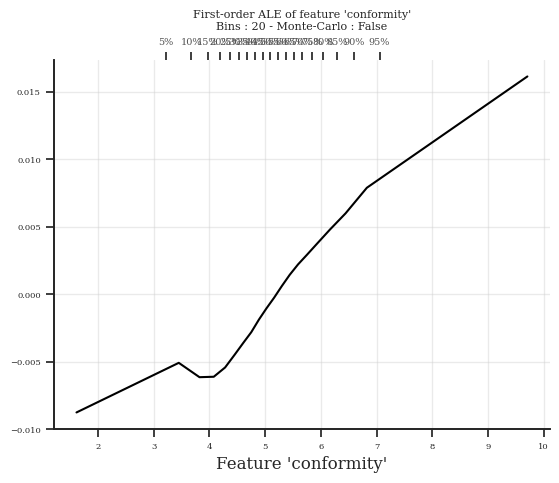

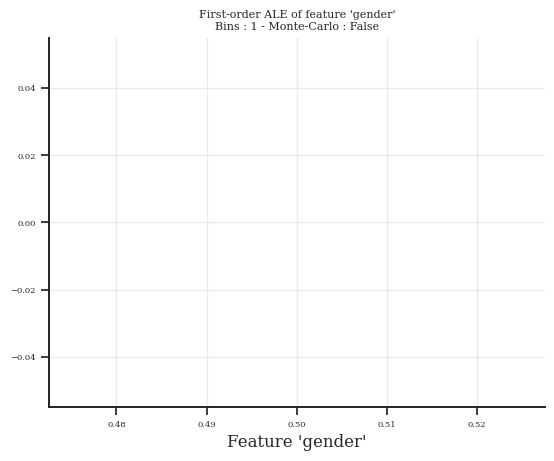

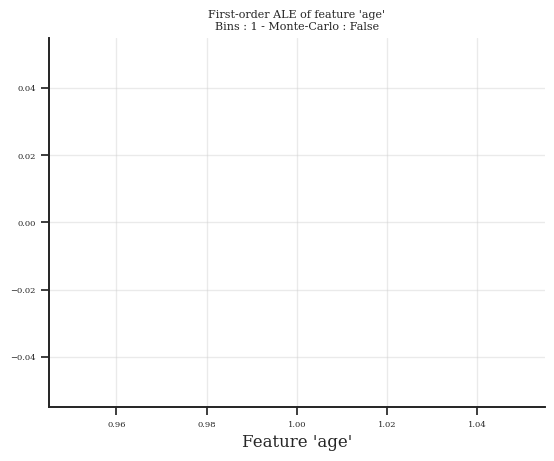

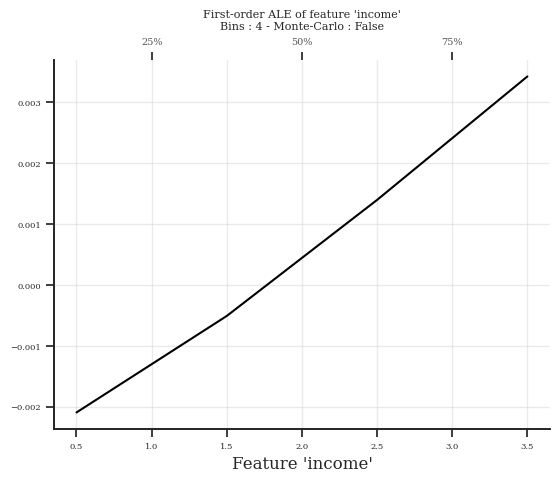

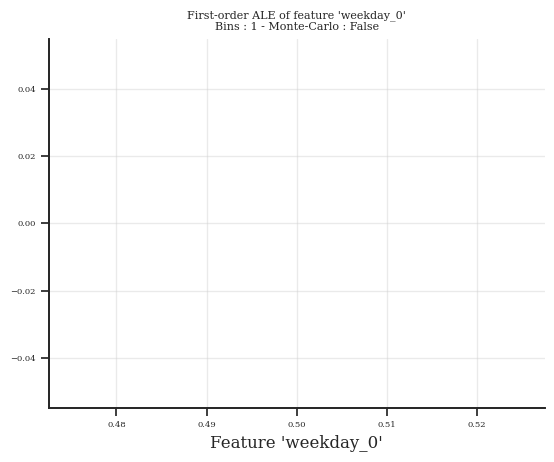

...

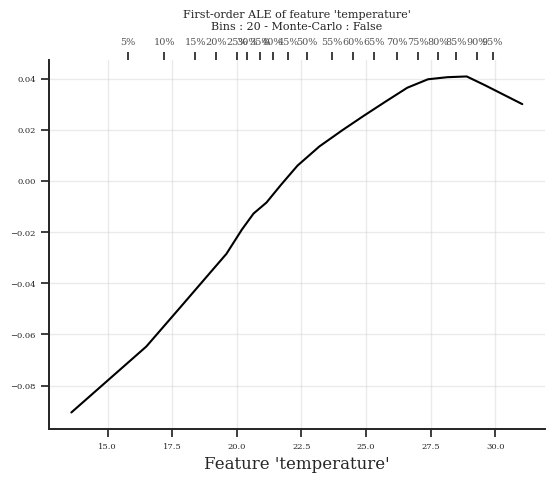

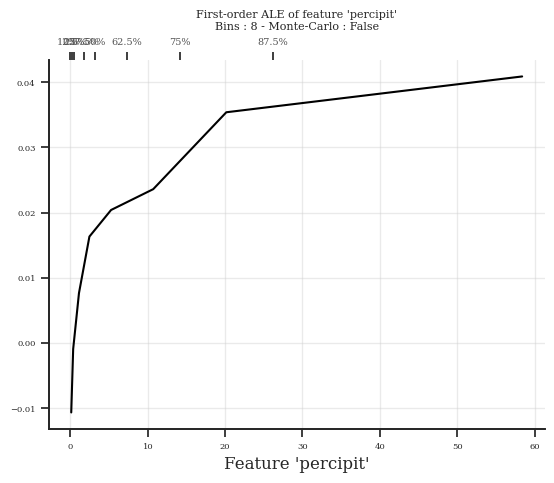

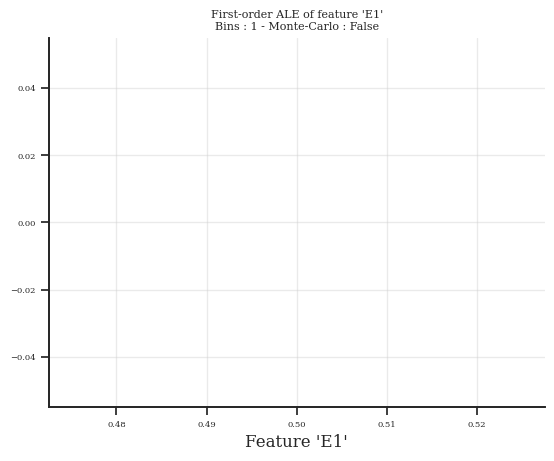

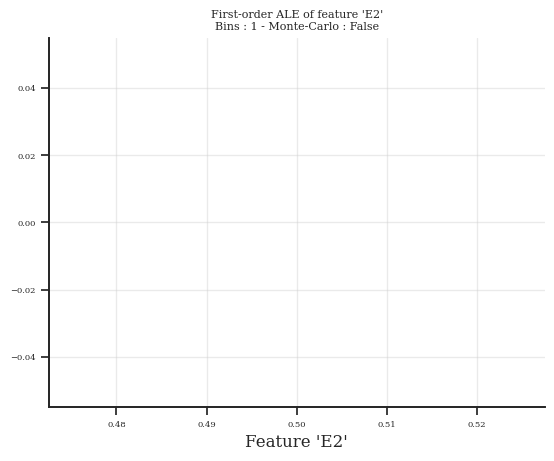

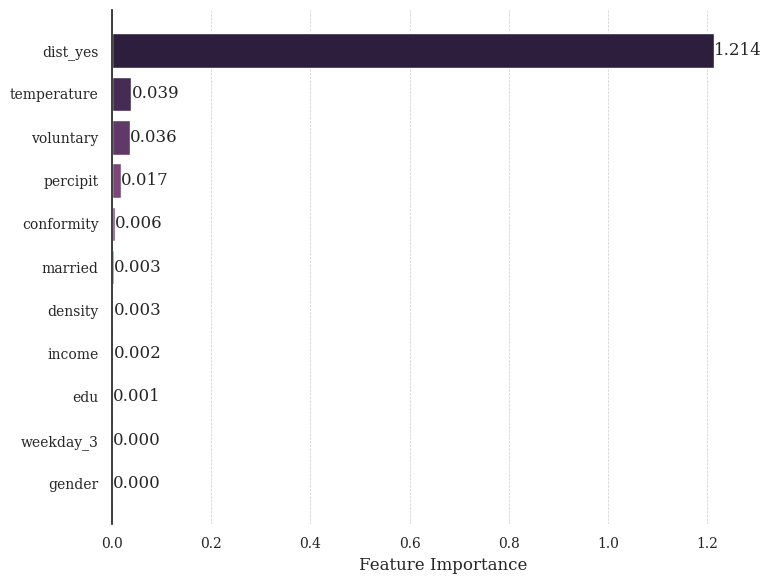

In [11]:
ALE_1ST, ALE_1ST_bin, feature_values = compute_ale_for_features(
        dataset, features, exp_name,
        n_sample=1000, treatment_feature_name="conformity"
    )

ale_ds, X, y = build_ale_xarray_dataset(
    ALE_1ST, ALE_1ST_bin, feature_values, features
)

ale_var_result, global_fig, ax = ale_variance_and_plot(
        X, y, ale_ds,
        model_name='RNN_Model',
        extra_estimators=(RandomForestRegressor(),),
        save_path=False,
        show=False,
        show_topN=[1,11]
    )

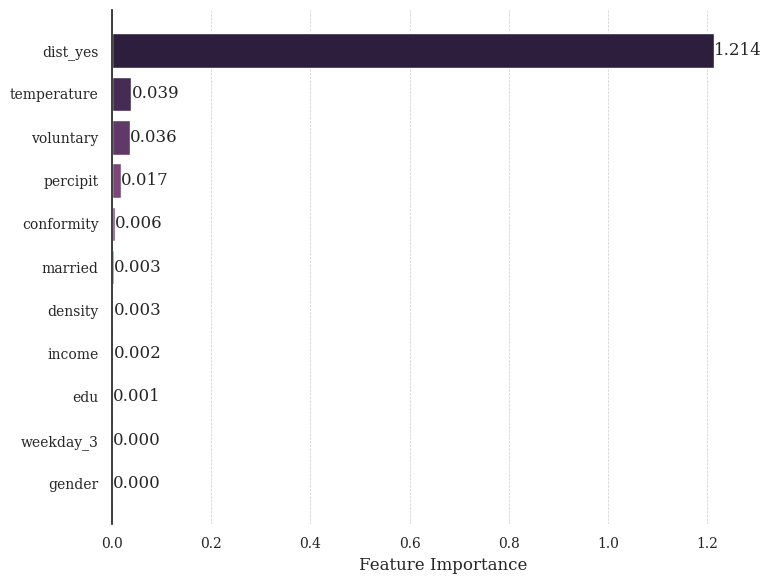

In [12]:
global_fig

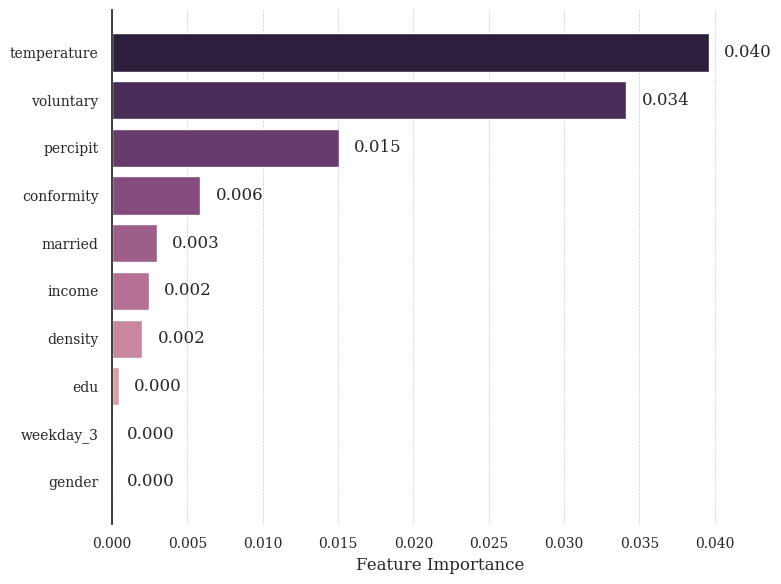

In [34]:
global_fig

#### 1.2 分三年各自的特征相对重要性

In [6]:
# 先划分数据集
column_2019 = 12  # index of year 2019 indicator
column_2020 = 13  # index of year 2020 indicator
column_2023 = 14  # index of year 2023 indicator

dataset19 = obtain_dataset(dataset, column_2019)
dataset20 = obtain_dataset(dataset, column_2020)
dataset23 = obtain_dataset(dataset, column_2023)

In [17]:
# 这里要删掉与年份相关的变量以及非疫情年中与疫情相关的变量
features_19 = [f for f in features if f not in ['voluntary', 'year_0', 'year_1', 'year_2', 'E1', 'E2', 'weekday_0', 'weekday_1','weekday_2', 'weekday_3', 'weekday_4', 'weekday_5', 'weekday_6']]
features_20 = [f for f in features if f not in ['year_0', 'year_1', 'year_2', 'weekday_0', 'weekday_1','weekday_2', 'weekday_3', 'weekday_4', 'weekday_5', 'weekday_6']]

Processing 2019 dataset...


2025-10-20 22:46:39.969 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3495417  3.7819293  4.0531263  4.257332   4.4280367
  4.5767536  4.715622   4.8500094  4.975775   5.100861   5.227017
  5.360263   5.501082   5.656945   5.846439   6.0644546  6.3263564
  6.6476235  7.138324  13.235176 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.09it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.23it/s]
2025-10-20 22:46:44.342 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3495417  3.7819293  4.0531263  4.257332   4.4280367
  4.5767536  4.715622   4.8500094  4.975775   5.100861   5.227017
  5.360263   5.501082   5.656945   5.846439   6.0644546  6.3263564
  6.6476235  7.138324  13.235176 ].


[ 1.6747708  3.5657353  3.9175277  4.155229   4.3426843  4.502395
  4.646188   4.782816   4.9128923  5.0383177  5.163939   5.29364
  5.4306726  5.579014   5.751692   5.9554467  6.1954055  6.48699
  6.892974  10.18675  ]


2025-10-20 22:46:45.545 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.67it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.35it/s]
2025-10-20 22:46:49.928 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 22:46:51.094 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 2.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.04it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.07it/s]
2025-10-20 22:46:55.288 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 2.].


[1.]


2025-10-20 22:46:56.450 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1. 2. 3. 4.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.35it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.81it/s]
2025-10-20 22:47:00.539 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1. 2. 3. 4.].


[0.5 1.5 2.5 3.5]


2025-10-20 22:47:01.720 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.17it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.52it/s]
2025-10-20 22:47:05.798 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 22:47:06.933 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.         0.21314327 0.29815584 0.34028322 0.3665217  0.38791844
 0.40978932 0.4304474  0.45012805 0.46259966 0.4768889  0.49007025
 0.501458   0.51360387 0.5250228  0.53430784 0.54633105 0.56050795
 0.5747212  0.5992992  0.66265005].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.49it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.22it/s]
2025-10-20 22:47:11.091 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.         0.21314327 0.29815584 0.34028322 0.3665217  0.38791844
 0.40978932 0.4304474  0.45012805 0.46259966 0.4768889  0.49007025
 0.501458   0.51360387 0.5250228  0.53430784 0.54633105 0.56050795
 0.5747212  0.5992992  0.66265005].


[0.10657164 0.25564957 0.31921953 0.35340244 0.37722006 0.3988539
 0.42011836 0.4402877  0.45636386 0.46974427 0.48347956 0.49576414
 0.5075309  0.51931334 0.52966535 0.54031944 0.5534195  0.56761456
 0.5870102  0.63097465]


2025-10-20 22:47:12.245 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.        1.0703125 1.4589844 1.7480469 1.9980469 2.2382812 2.4355469
 2.6425781 2.8339844 3.0351562 3.2578125 3.4960938 3.8066406 5.4648438].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.42it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.76it/s]
2025-10-20 22:47:16.275 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.        1.0703125 1.4589844 1.7480469 1.9980469 2.2382812 2.4355469
 2.6425781 2.8339844 3.0351562 3.2578125 3.4960938 3.8066406 5.4648438].


[0.53515625 1.2646484  1.6035156  1.8730469  2.118164   2.336914
 2.5390625  2.7382812  2.9345703  3.1464844  3.3769531  3.6513672
 4.635742  ]


2025-10-20 22:47:17.224 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [  0.          2.3352416   5.6722775   9.235536   12.314184   14.739947
  17.78544    21.376192   24.430502   28.68366    31.722286   34.71531
  38.479404   42.638157   47.21131    53.20509    57.36926    62.707893
  70.52106    85.65813   148.87485  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.75it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.70it/s]
2025-10-20 22:47:21.583 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [  0.          2.3352416   5.6722775   9.235536   12.314184   14.739947
  17.78544    21.376192   24.430502   28.68366    31.722286   34.71531
  38.479404   42.638157   47.21131    53.20509    57.36926    62.707893
  70.52106    85.65813   148.87485  ].


[  1.1676208   4.0037594   7.4539065  10.77486    13.527065   16.262693
  19.580816   22.903347   26.557081   30.202972   33.218796   36.59736
  40.55878    44.924736   50.2082     55.287174   60.038574   66.61447
  78.08959   117.26649  ]


2025-10-20 22:47:22.542 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.         0.01101534 0.01866153 0.02818951 0.03826544 0.04997405
 0.06029887 0.07535643 0.09223866 0.10897598 0.12888943 0.14847712
 0.1695655  0.1870769  0.20903473 0.23325917 0.2661105  0.29081208
 0.32300463 0.3878776  0.6624904 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.75it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.26it/s]
2025-10-20 22:47:26.829 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.         0.01101534 0.01866153 0.02818951 0.03826544 0.04997405
 0.06029887 0.07535643 0.09223866 0.10897598 0.12888943 0.14847712
 0.1695655  0.1870769  0.20903473 0.23325917 0.2661105  0.29081208
 0.32300463 0.3878776  0.6624904 ].


[0.00550767 0.01483843 0.02342552 0.03322747 0.04411975 0.05513646
 0.06782766 0.08379754 0.10060732 0.1189327  0.13868327 0.15902132
 0.1783212  0.1980558  0.22114694 0.24968484 0.27846128 0.30690837
 0.35544112 0.52518404]


2025-10-20 22:47:27.793 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [13.2 15.8 16.7 17.6 18.5 19.  20.  20.5 21.  21.1 21.5 22.2 22.7 23.7
 24.7 25.2 26.  26.6 27.4 28.7 29.8].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.09it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.49it/s]
2025-10-20 22:47:32.051 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [13.2 15.8 16.7 17.6 18.5 19.  20.  20.5 21.  21.1 21.5 22.2 22.7 23.7
 24.7 25.2 26.  26.6 27.4 28.7 29.8].


[14.5      16.25     17.150002 18.05     18.75     19.5      20.25
 20.75     21.05     21.3      21.85     22.45     23.2      24.2
 24.95     25.6      26.3      27.       28.05     29.25    ]


2025-10-20 22:47:33.051 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.   0.1  1.1  3.1  5.4  9.7 16.9 24.4 64.1].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.72it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.33it/s]
2025-10-20 22:47:37.343 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.   0.1  1.1  3.1  5.4  9.7 16.9 24.4 64.1].


[ 0.05      0.6       2.1       4.25      7.55     13.299999 20.65
 44.25    ]


Degrees of freedom <= 0 for slice.


Processing 2020 dataset...


2025-10-20 22:47:39.146 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.7611368  3.2114105  3.4918346  3.7205489  3.9033737
  4.0634537  4.2082424  4.3491387  4.4840837  4.6191688  4.749651
  4.883105   5.0247493  5.1774535  5.341764   5.537302   5.778781
  6.11035    6.5967817 12.1260605].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.24it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.34it/s]
2025-10-20 22:47:43.467 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.7611368  3.2114105  3.4918346  3.7205489  3.9033737
  4.0634537  4.2082424  4.3491387  4.4840837  4.6191688  4.749651
  4.883105   5.0247493  5.1774535  5.341764   5.537302   5.778781
  6.11035    6.5967817 12.1260605].


[1.3805684 2.9862738 3.3516226 3.6061916 3.8119612 3.9834137 4.135848
 4.2786903 4.416611  4.551626  4.68441   4.8163776 4.953927  5.1011014
 5.2596087 5.439533  5.6580415 5.944566  6.353566  9.361422 ]


2025-10-20 22:47:44.424 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.52it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.53it/s]
2025-10-20 22:47:48.634 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 22:47:49.587 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 2.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.48it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.52it/s]
2025-10-20 22:47:53.773 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 2.].


[1.]


2025-10-20 22:47:54.709 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1. 2. 3. 4.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.32it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.46it/s]
2025-10-20 22:47:59.025 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1. 2. 3. 4.].


[0.5 1.5 2.5 3.5]


2025-10-20 22:47:59.972 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.        0.6931472 1.609438  2.3025851 3.0445225 4.1108737].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.82it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.21it/s]
2025-10-20 22:48:04.286 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.        0.6931472 1.609438  2.3025851 3.0445225 4.1108737].


[0.3465736 1.1512926 1.9560115 2.673554  3.5776982]


2025-10-20 22:48:05.281 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.78it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.44it/s]
2025-10-20 22:48:09.567 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 22:48:10.568 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.         0.23109303 0.30166543 0.34940705 0.37707976 0.40033245
 0.4158394  0.43347505 0.45151523 0.46521807 0.48034513 0.49383557
 0.50817347 0.5194415  0.5292991  0.54065293 0.5536695  0.5628737
 0.5806975  0.60183114 0.72362983].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.35it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.32it/s]
2025-10-20 22:48:14.861 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.         0.23109303 0.30166543 0.34940705 0.37707976 0.40033245
 0.4158394  0.43347505 0.45151523 0.46521807 0.48034513 0.49383557
 0.50817347 0.5194415  0.5292991  0.54065293 0.5536695  0.5628737
 0.5806975  0.60183114 0.72362983].


[0.11554652 0.26637924 0.32553625 0.3632434  0.3887061  0.40808594
 0.42465723 0.44249514 0.45836663 0.4727816  0.48709035 0.5010045
 0.5138075  0.5243703  0.534976   0.5471612  0.55827165 0.57178557
 0.5912643  0.66273046]


2025-10-20 22:48:15.823 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.        0.8847656 1.3291016 1.6835938 2.0136719 2.3144531 2.5683594
 2.8164062 3.0429688 3.2871094 3.5351562 3.8574219 5.484375 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.02it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.63it/s]
2025-10-20 22:48:20.089 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.        0.8847656 1.3291016 1.6835938 2.0136719 2.3144531 2.5683594
 2.8164062 3.0429688 3.2871094 3.5351562 3.8574219 5.484375 ].


[0.4423828 1.1069336 1.5063477 1.8486328 2.1640625 2.4414062 2.6923828
 2.9296875 3.165039  3.4111328 3.696289  4.6708984]


More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
2025-10-20 22:48:21.043 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [  0.          2.3946688   6.229931   10.403906   12.826672   14.941426
  17.966614   20.709604   23.609953   26.814054   30.103775   33.19439
  37.847      41.758133   45.28782    49.410763   55.23664    61.808243
  69.78137    83.54497   120.16842  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.81it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.70it/s]
2025-10-20 22:48:25.298 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [  0.          2.3946688   6.229931   10.403906   12.826672   14.941426
  17.966614   20.709604   23.609953   26.814054   30.103775   33.19439
  37.847      41.758133   45.28782    49.410763   55.23664    61.808243
  69.78137    83.54497   120.16842  ].


[  1.1973344   4.3122997   8.316918   11.615289   13.884048   16.45402
  19.338108   22.159779   25.212004   28.458916   31.649082   35.520695
  39.802567   43.522976   47.34929    52.3237     58.52244    65.79481
  76.66317   101.85669  ]


2025-10-20 22:48:26.253 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.         0.00954469 0.01934042 0.02766934 0.03542825 0.04557497
 0.05781488 0.07338082 0.09595285 0.11280289 0.1345993  0.1553024
 0.17695832 0.20381382 0.22046074 0.24065536 0.26773953 0.30075023
 0.32820806 0.37960902 0.5237552 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.73it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.46it/s]
2025-10-20 22:48:30.475 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.         0.00954469 0.01934042 0.02766934 0.03542825 0.04557497
 0.05781488 0.07338082 0.09595285 0.11280289 0.1345993  0.1553024
 0.17695832 0.20381382 0.22046074 0.24065536 0.26773953 0.30075023
 0.32820806 0.37960902 0.5237552 ].


[0.00477235 0.01444256 0.02350488 0.03154879 0.04050161 0.05169493
 0.06559785 0.08466683 0.10437787 0.1237011  0.14495085 0.16613036
 0.19038607 0.21213728 0.23055805 0.25419745 0.2842449  0.31447914
 0.35390854 0.4516821 ]


2025-10-20 22:48:31.444 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [11.4 14.4 16.3 16.8 17.6 18.5 19.1 19.6 20.1 20.2 20.4 20.9 21.7 22.1
 22.7 23.8 25.4 26.5 27.4 28.5 29.2].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.88it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.57it/s]
2025-10-20 22:48:35.790 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [11.4 14.4 16.3 16.8 17.6 18.5 19.1 19.6 20.1 20.2 20.4 20.9 21.7 22.1
 22.7 23.8 25.4 26.5 27.4 28.5 29.2].


[12.9      15.349999 16.55     17.2      18.05     18.8      19.35
 19.85     20.150002 20.3      20.65     21.3      21.900002 22.400002
 23.25     24.599998 25.95     26.95     27.95     28.85    ]


2025-10-20 22:48:36.757 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.   0.1  0.2  1.2  2.3  9.2 17.3 69.1].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.85it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.23it/s]
2025-10-20 22:48:41.087 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.   0.1  0.2  1.2  2.3  9.2 17.3 69.1].


[ 0.05        0.15        0.70000005  1.75        5.75       13.25
 43.199997  ]


2025-10-20 22:48:42.026 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.61it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.98it/s]
2025-10-20 22:48:46.309 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 22:48:47.246 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.54it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.40it/s]
2025-10-20 22:48:51.505 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


Degrees of freedom <= 0 for slice.


Processing 2023 dataset...


2025-10-20 22:48:53.411 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.03033599  3.9561472   4.326974    4.5656114   4.739475    4.8870444
  5.013504    5.1280694   5.2365746   5.3432574   5.446493    5.553875
  5.6656404   5.7821417   5.9071565   6.0428987   6.201036    6.412599
  6.690363    7.1089745  11.322745  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.68it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.14it/s]
2025-10-20 22:48:57.687 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.03033599  3.9561472   4.326974    4.5656114   4.739475    4.8870444
  5.013504    5.1280694   5.2365746   5.3432574   5.446493    5.553875
  5.6656404   5.7821417   5.9071565   6.0428987   6.201036    6.412599
  6.690363    7.1089745  11.322745  ].


[1.9932415 4.1415606 4.446293  4.652543  4.8132596 4.9502745 5.0707865
 5.182322  5.289916  5.3948755 5.500184  5.6097574 5.7238913 5.8446493
 5.9750276 6.1219673 6.3068175 6.5514812 6.8996687 9.21586  ]


2025-10-20 22:48:58.634 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.46it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.64it/s]
2025-10-20 22:49:02.899 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 22:49:03.857 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 2.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.93it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.79it/s]
2025-10-20 22:49:08.274 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 2.].


[1.]


2025-10-20 22:49:09.195 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1. 2. 3. 4.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.23it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.56it/s]
2025-10-20 22:49:13.617 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1. 2. 3. 4.].


[0.5 1.5 2.5 3.5]


2025-10-20 22:49:14.589 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0. 1.].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.37it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.56it/s]
2025-10-20 22:49:18.926 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0. 1.].


[0.5]


2025-10-20 22:49:19.863 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.         0.22136976 0.2819113  0.32762972 0.35706148 0.38035116
 0.4023547  0.4214292  0.43555814 0.45096242 0.4653185  0.47932163
 0.49383557 0.51127154 0.52573824 0.5389227  0.55033886 0.5624039
 0.58136123 0.5968038  0.68590844].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.44it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.50it/s]
2025-10-20 22:49:24.165 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.         0.22136976 0.2819113  0.32762972 0.35706148 0.38035116
 0.4023547  0.4214292  0.43555814 0.45096242 0.4653185  0.47932163
 0.49383557 0.51127154 0.52573824 0.5389227  0.55033886 0.5624039
 0.58136123 0.5968038  0.68590844].


[0.11068488 0.25164053 0.30477053 0.3423456  0.36870632 0.39135292
 0.41189194 0.42849368 0.44326028 0.45814046 0.47232008 0.48657858
 0.5025536  0.51850486 0.5323305  0.54463077 0.5563714  0.5718826
 0.5890825  0.6413561 ]


2025-10-20 22:49:25.121 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.        0.5605469 1.0478516 1.4130859 1.7451172 2.0039062 2.2578125
 2.5058594 2.7324219 2.9316406 3.1679688 3.3789062 3.6152344 3.8925781
 5.3515625].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.93it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.58it/s]
2025-10-20 22:49:29.453 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.        0.5605469 1.0478516 1.4130859 1.7451172 2.0039062 2.2578125
 2.5058594 2.7324219 2.9316406 3.1679688 3.3789062 3.6152344 3.8925781
 5.3515625].


[0.28027344 0.8041992  1.2304688  1.5791016  1.8745117  2.1308594
 2.381836   2.6191406  2.8320312  3.0498047  3.2734375  3.4970703
 3.7539062  4.6220703 ]


2025-10-20 22:49:30.395 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [  0.          2.9444764   6.475128    9.607075   12.71029    15.978731
  18.88555    21.724161   24.90006    28.690372   31.74596    35.082947
  38.85119    42.845623   47.743587   52.66139    58.799137   65.18423
  73.321434   86.19995   129.422    ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.03it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.53it/s]
2025-10-20 22:49:34.709 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [  0.          2.9444764   6.475128    9.607075   12.71029    15.978731
  18.88555    21.724161   24.90006    28.690372   31.74596    35.082947
  38.85119    42.845623   47.743587   52.66139    58.799137   65.18423
  73.321434   86.19995   129.422    ].


[  1.4722382   4.709802    8.041101   11.158682   14.344511   17.43214
  20.304855   23.31211    26.795216   30.218166   33.41445    36.967068
  40.848404   45.294605   50.202488   55.730263   61.991684   69.25283
  79.7607    107.810974 ]


2025-10-20 22:49:35.663 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.         0.01145925 0.02045564 0.02942291 0.03906321 0.05411307
 0.06560327 0.08379605 0.10854573 0.12678984 0.14365183 0.15846547
 0.17516628 0.20247056 0.22809352 0.25070935 0.2760327  0.3106858
 0.3475863  0.40128472 0.6359294 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.85it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.73it/s]
2025-10-20 22:49:40.127 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.         0.01145925 0.02045564 0.02942291 0.03906321 0.05411307
 0.06560327 0.08379605 0.10854573 0.12678984 0.14365183 0.15846547
 0.17516628 0.20247056 0.22809352 0.25070935 0.2760327  0.3106858
 0.3475863  0.40128472 0.6359294 ].


[0.00572963 0.01595744 0.02493928 0.03424306 0.04658814 0.05985817
 0.07469966 0.09617089 0.11766778 0.13522083 0.15105864 0.16681588
 0.18881842 0.21528204 0.23940143 0.26337102 0.29335925 0.32913607
 0.3744355  0.5186071 ]


2025-10-20 22:49:41.090 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [16.8 19.3 20.6 21.3 22.2 22.9 23.9 24.5 25.2 26.3 27.  27.7 28.2 28.4
 28.9 29.3 29.6 29.9 30.1 30.3 32.2].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.49it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.10it/s]
2025-10-20 22:49:45.477 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [16.8 19.3 20.6 21.3 22.2 22.9 23.9 24.5 25.2 26.3 27.  27.7 28.2 28.4
 28.9 29.3 29.6 29.9 30.1 30.3 32.2].


[18.05     19.95     20.95     21.75     22.55     23.4      24.2
 24.85     25.75     26.65     27.35     27.95     28.3      28.65
 29.099998 29.45     29.75     30.       30.2      31.25    ]


2025-10-20 22:49:46.437 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.   0.3  0.5  1.5  2.5  5.5  8.4 18.  44.2 90.6].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.57it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.75it/s]
2025-10-20 22:49:50.809 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.   0.3  0.5  1.5  2.5  5.5  8.4 18.  44.2 90.6].


[ 0.15  0.4   1.    2.    4.    6.95 13.2  31.1  67.4 ]


Degrees of freedom <= 0 for slice.


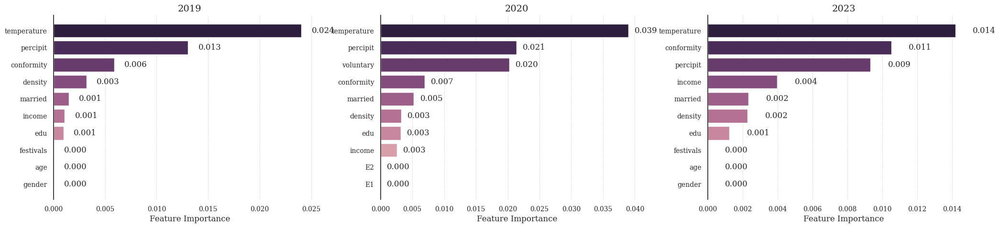

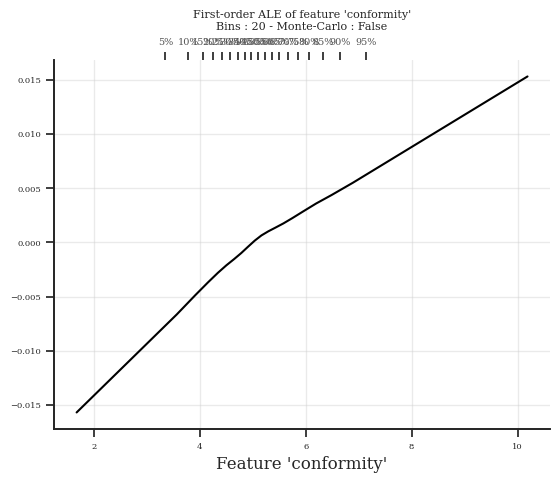

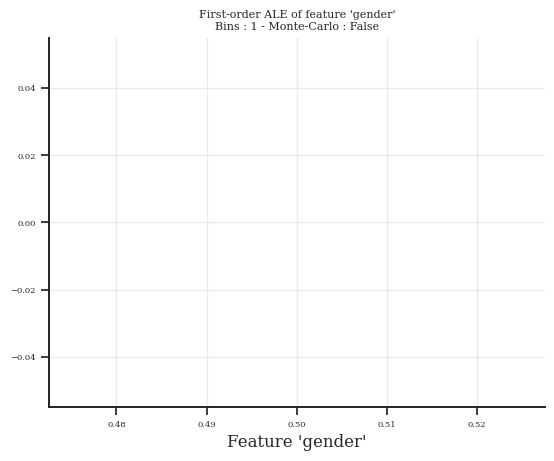

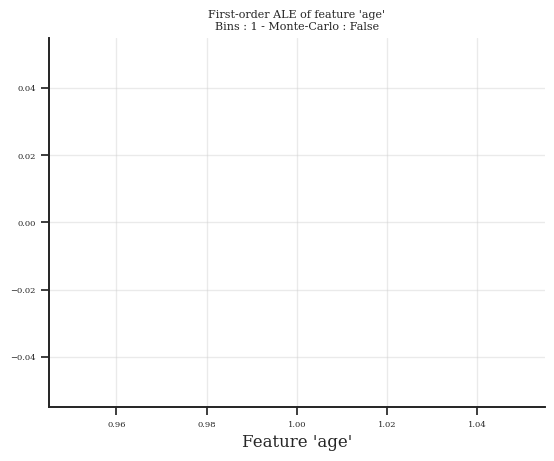

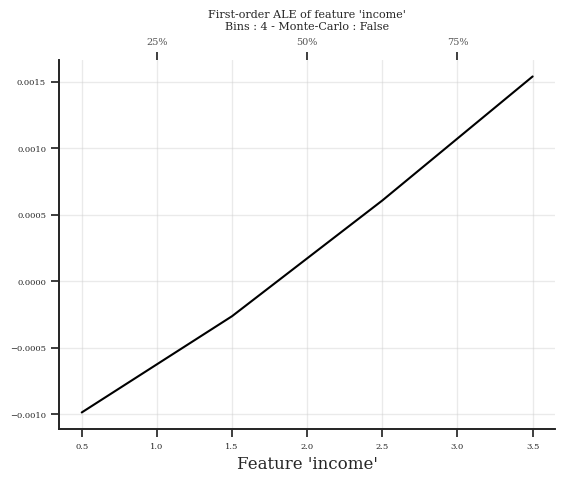

...

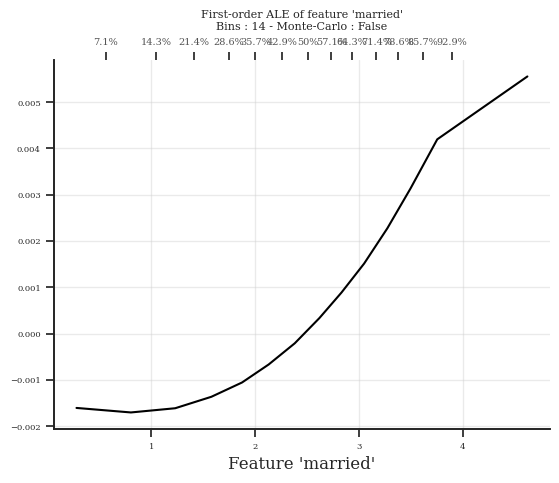

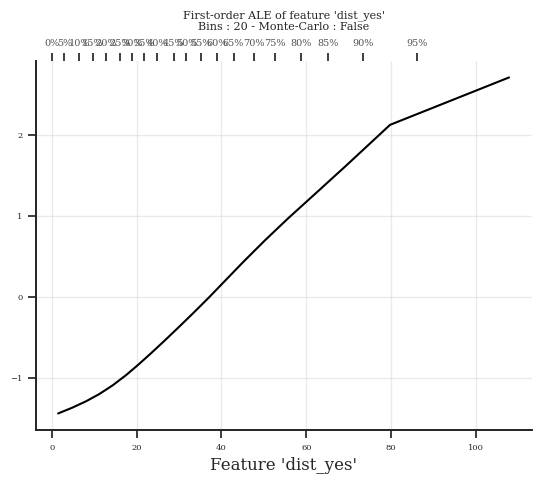

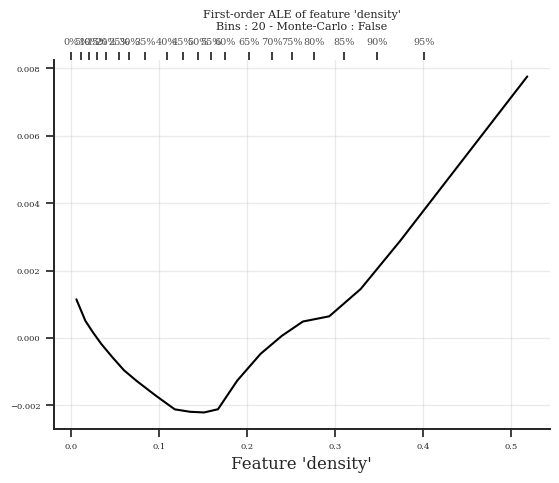

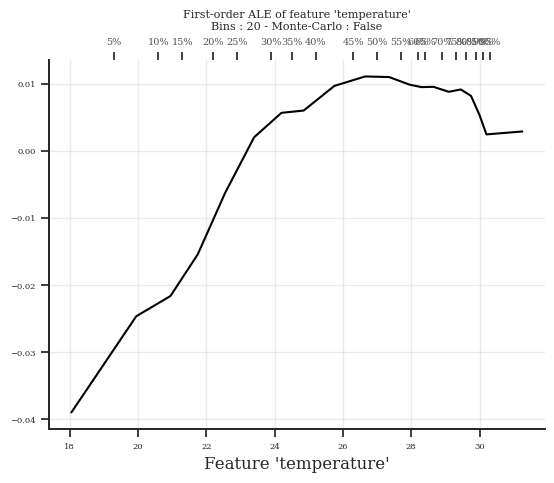

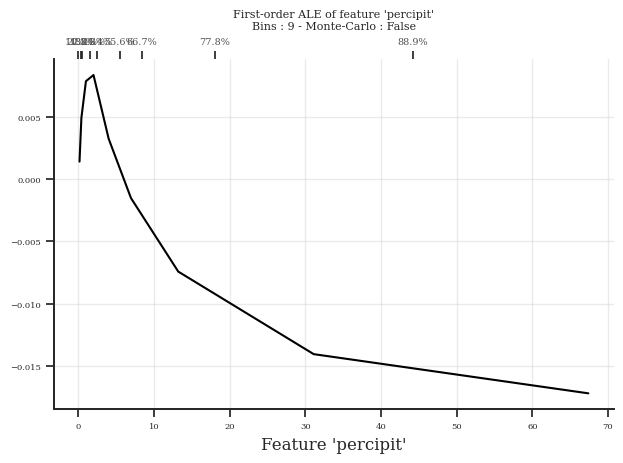

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(25, 5))  # 一行三列大图

for i, (dataset, year) in enumerate(zip([dataset19, dataset20, dataset23], ["2019", "2020", "2023"])):
    print(f"Processing {year} dataset...")
    if year != "2020":
        features_this_year = features_19
    else:
        features_this_year = features_20
        # index_to_remove = [-1,-2]
        # dataset['covariates'] = np.delete(dataset['covariates'], index_to_remove, axis=2)

    ALE_1ST, ALE_1ST_bin, feature_values = compute_ale_for_features(
        dataset, features_this_year, exp_name,
        n_sample=1000, treatment_feature_name="conformity",
    )

    ale_ds, X, y = build_ale_xarray_dataset(
        ALE_1ST, ALE_1ST_bin, feature_values, features_this_year
    )

    ale_var_result, global_fig, global_ax = ale_variance_and_plot(
        X, y, ale_ds,
        model_name='RNN_Model',
        extra_estimators=(RandomForestRegressor(),),
        save_path=False,
        show=False,
        ax=axes[i],
        show_topN = [1,11],
        figsize=(7,6)
    )

    axes[i].set_title(year, fontsize=14)

# plt.tight_layout()
# plt.show()

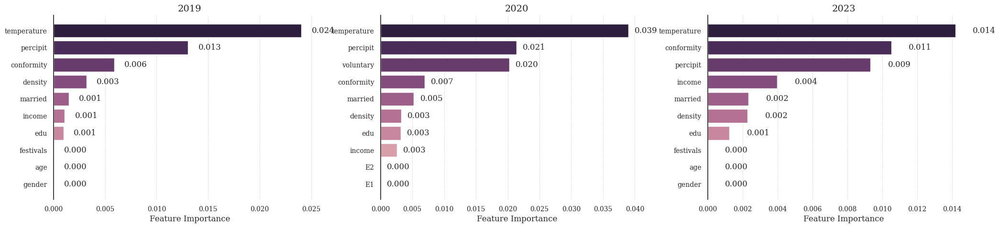

In [19]:
fig

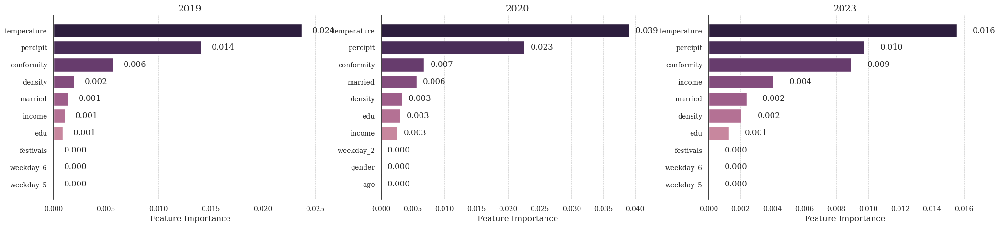

In [40]:
fig

## 1. ALE Curve in SCI750

### 2.1 总体ale曲线

data load as step 1

In [4]:
dataset = load_data("../data/sample_3w2_sci750.h5")

for key in dataset.keys():
    print(key)
    print(dataset[key].shape)
    print(dataset[key].dtype)

covariates
(96000, 161, 23)
float32
outcomes
(96000, 161, 1)
float32
sequence_length
(96000,)
int64
treatments
(96000, 161, 1)
float32


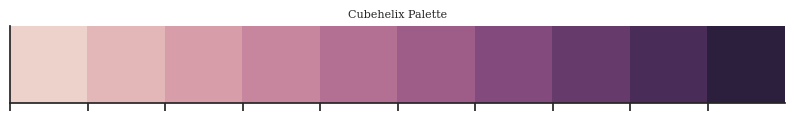

In [5]:
# 模型编号
exp_name = "base_model_sci750_sampling_v7"

# 生成 cubehelix 调色盘
cubehelix_palette = sns.cubehelix_palette(n_colors=10)
# 显示调色盘中的所有颜色
sns.palplot(cubehelix_palette)
plt.title('Cubehelix Palette')
plt.show()

the `interpolation=` argument to quantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
2025-12-16 22:25:18.239 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.18423198  3.2343502   3.659448    3.9157853   4.108908    4.2679563
  4.4051437   4.5312243   4.649741    4.7677145   4.8856883   5.003704
  5.1284943   5.2495084   5.3719454   5.510999    5.6636987   5.8452845
  6.1033616   6.528241   10.75551   ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 0it [00:00, ?it/s]2025-12-16 22:25:19.653826: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:432] Loaded cuDNN version 8600
Predicting rnn_propensity_weighted: 16it [00:01, 13.53it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.96it/s]
2025-12-16 22:25:22.470 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.18423198  3.2343502   3.659448    3.9157853   4.108908    4.2679563
  4.4051437   4.5312243   4.649741    4.7677145   4.8856883   5.003704
  5.1284943   5.2495084   5.3719454   5.510999    5.6636987   5.8452845
  6.1033616   6.528241   10.75551   ].


[1.7092911 3.446899  3.7876167 4.0123467 4.188432  4.3365498 4.468184
 4.5904827 4.708728  4.826701  4.9446964 5.066099  5.189001  5.310727
 5.441472  5.587349  5.754492  5.9743233 6.3158016 8.641876 ]


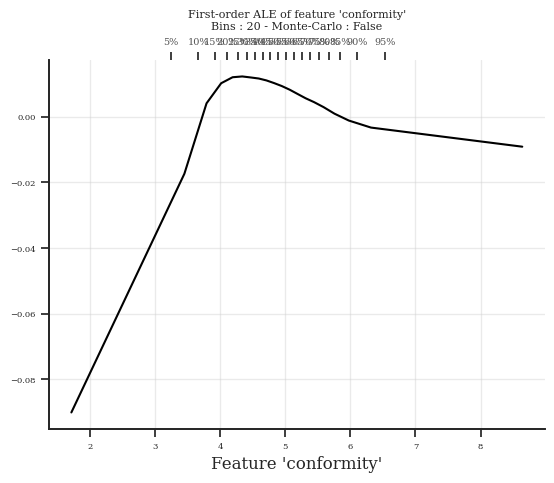

In [6]:
# 计算全局ale，转化成xarray的格式
# 似乎没有固定quantiles，需要再调整一下
bins = 20
quantiles = np.unique(
   np.quantile(
       dataset['treatments'].reshape(-1), np.linspace(0, 1, bins + 1), interpolation="lower"
   )
)
ALE_1ST = {
   'RNN_Model': [],
   }
# n_bootstrap = 30
n_bootstrap = 1

for _ in range(n_bootstrap):
    sub_dataset = dataset_sampling(dataset, 1000)
    ale_fig, ale_1st, _ = compute_ale(sub_dataset, 'rmsn_'+str(exp_name), b_use_predicted_confounders=False, features = ['conformity'], default_quantiles=quantiles)
    ALE_1ST['RNN_Model'].append(ale_1st)
    # window_ale_fig, ale, _ = compute_ale(sub_dataset, 'rmsn_' + str(exp_name), b_use_predicted_confounders=False, features=['week', 'conformity'], default_quantiles=quantiles)
    # ale_1st = np.sum(ale, axis=0)
    # ALE_1ST['RNN_Model'].append(ale_1st)

for key in ALE_1ST.keys():
    ALE_1ST[key] = np.array(ALE_1ST[key])
ale_dataset = create_ale_dataset(ALE_1ST, quantiles, dataset['treatments'], ['RNN_Model'], 'conformity')

In [7]:
#save
# ale_dataset.to_netcdf(path='figures/figure_data/fig_1b.nc')

#save bootstrap=1
ale_dataset.to_netcdf(path='figures/figure_data/fig_robustness_noCI.nc')

#read
# ale_dataset = xr.open_dataset('./figures/figure_data/fig_1b.nc')

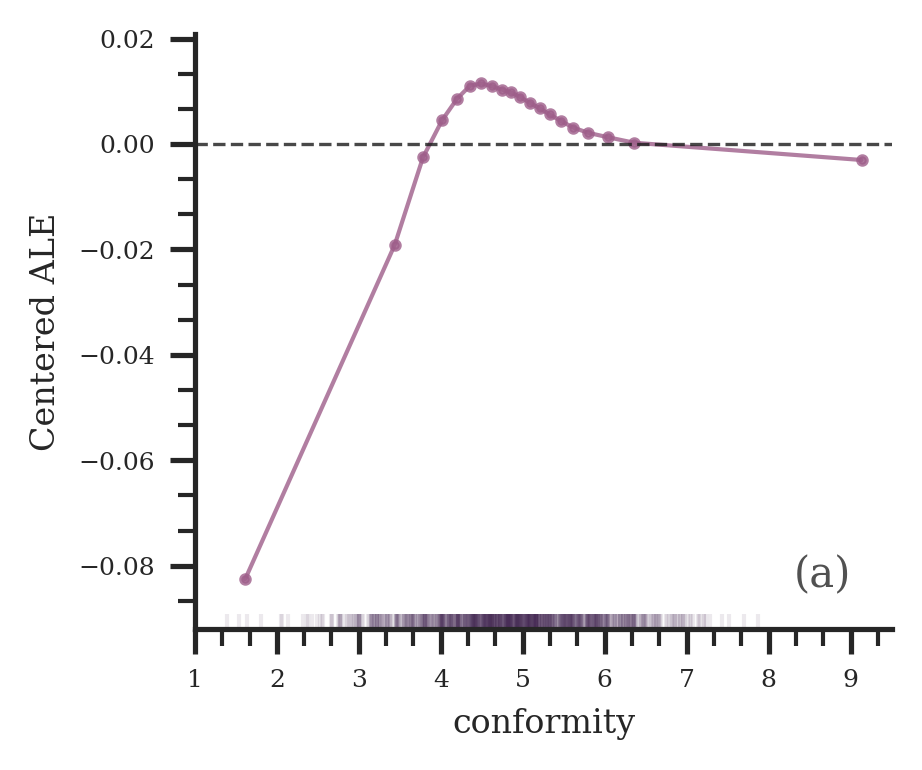

In [7]:
estimator = [('RNN_Model',RandomForestRegressor())]
explainer = skexplain.ExplainToolkit(estimator)

#修改可视化效果
#fig, ax = plt.subplots(dpi=300)
fig, ax = explainer.plot_ale(
                                   ale = ale_dataset,
                                   features='conformity',
                                   display_units=plotting_config.display_units,
                                   display_feature_names=plotting_config.display_feature_names,
                                   line_kws={'marker': 'o', 'markersize':2,'linewidth':1, 'line_colors': [cubehelix_palette[5]]},
                                   add_hist = False,
                                  )

# ax.set_xscale('log')
ax.set_ylabel('Centered ALE', fontsize = 8)
# ax.set_xlim(right = 1000)
ax.set_xlim(left=1)

# ax.set_xticks(conformity_bin_values_original)
# ax.set_xticklabels([f'{val:.2f}' for val in conformity_bin_values_original])

data = ale_dataset['conformity'].values
if len(data) > 1000:
    data_sample = np.random.choice(data, size=1000, replace=False)
else:
    data_sample = data
sns.rugplot(data_sample, ax=ax, color=cubehelix_palette[-2], alpha=0.1)

# plt.savefig('./figures/fig_1b_SCI_ale_1st_log_log.png',  dpi=300)

plt.show()

In [8]:
# 还原SCI的log值
conformity_bin_values_log = ale_dataset['conformity__bin_values'].values
conformity_bin_values_original = np.exp(conformity_bin_values_log)-1
ale_dataset['conformity__bin_values'] = (('n_bins__conformity'), conformity_bin_values_original)

conformity_log = ale_dataset['conformity'].values
conformity_original = np.exp(conformity_log)-1
ale_dataset['conformity'] = (('n_X'), conformity_original)

ale_dataset

<xarray.Dataset>
Dimensions:                     (n_bootstrap: 1, n_bins__conformity: 20,
                                 n_X: 15456000)
Dimensions without coordinates: n_bootstrap, n_bins__conformity, n_X
Data variables:
    conformity__RNN_Model__ale  (n_bootstrap, n_bins__conformity) float64 -0....
    conformity__bin_values      (n_bins__conformity) float32 4.02 ... 9.254e+03
    conformity                  (n_X) float32 273.6 292.0 330.7 ... 342.5 302.2
Attributes:
    estimator_output:  raw
    estimators used:   ['RNN_Model']
    method:            ale
    dimension:         1D
    features used:     ['conformity']

In [9]:
# 将ALE值转换为倍数
ale_values = ale_dataset['conformity__RNN_Model__ale'].values
ale_values_original = np.exp(ale_values)
ale_dataset['conformity__RNN_Model__ale'] = ([('n_bootstrap'),('n_bins__conformity')], ale_values_original)

倍数y轴

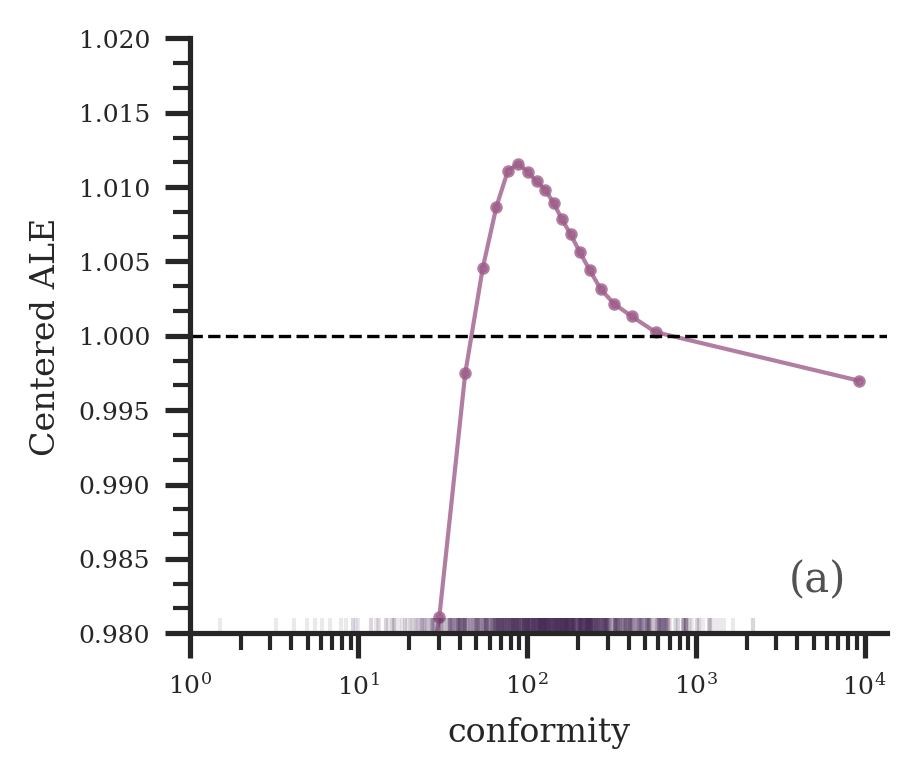

In [10]:
estimator = [('RNN_Model',RandomForestRegressor())]
explainer = skexplain.ExplainToolkit(estimator)

#修改可视化效果
#fig, ax = plt.subplots(dpi=300)
fig, ax = explainer.plot_ale(
                                   ale = ale_dataset,
                                   features='conformity',
                                   display_units=plotting_config.display_units,
                                   display_feature_names=plotting_config.display_feature_names,
                                   line_kws={'marker': 'o', 'markersize':2,'linewidth':1, 'line_colors': [cubehelix_palette[5]]},
                                   add_hist = False,
                                  )
ax.axhline(y=1, color='black', ls='--', lw=0.8)

ax.set_xscale('log')
ax.set_ylabel('Centered ALE', fontsize = 8)
# ax.set_xlim(right = 1000)
ax.set_xlim(left=1)
ax.set_ylim(bottom = 0.98, top = 1.02)


# ax.set_xticks(conformity_bin_values_original)
# ax.set_xticklabels([f'{val:.2f}' for val in conformity_bin_values_original])

data = ale_dataset['conformity'].values
if len(data) > 1000:
    data_sample = np.random.choice(data, size=1000, replace=False)
else:
    data_sample = data
sns.rugplot(data_sample, ax=ax, color=cubehelix_palette[-2], alpha=0.1)

# plt.savefig('./figures/fig_1b_SCI_ale_1st_SCI_log.png',  dpi=300)

plt.show()

倍数y轴 + 整数x轴 + cut 95%

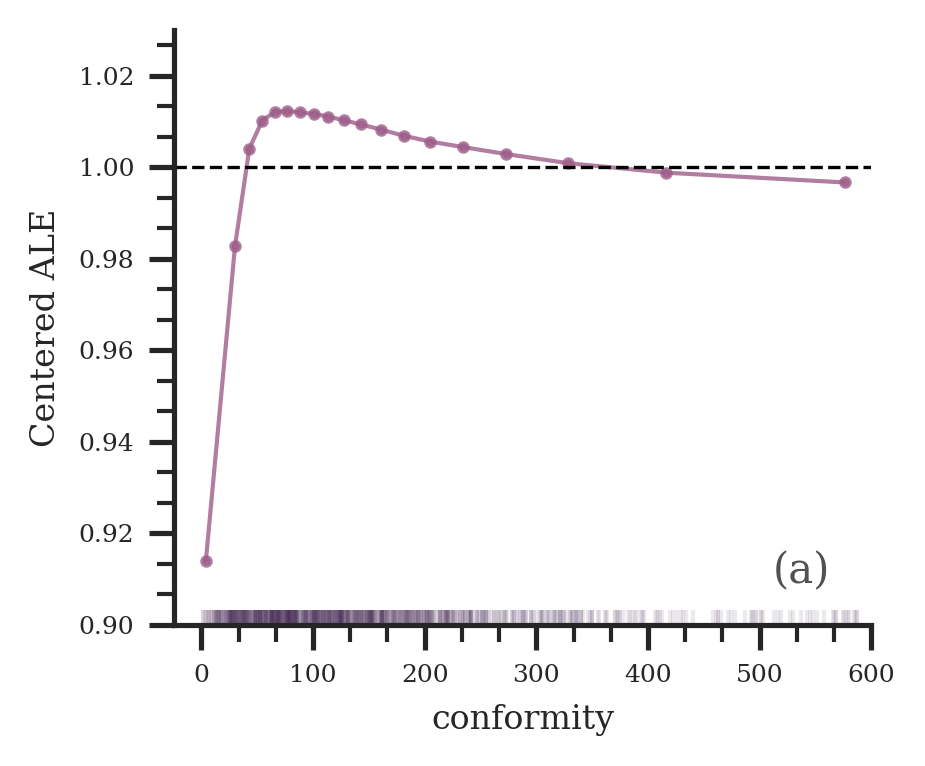

In [11]:
bins_to_keep = ale_dataset['n_bins__conformity'] != ale_dataset['n_bins__conformity'].loc[-1]
ale_dataset_select = ale_dataset.sel(n_bins__conformity=bins_to_keep)

estimator = [('RNN_Model',RandomForestRegressor())]
explainer = skexplain.ExplainToolkit(estimator)

#修改可视化效果
#fig, ax = plt.subplots(dpi=300)
fig, ax = explainer.plot_ale(
                                   ale = ale_dataset_select,
                                   features='conformity',
                                   display_units=plotting_config.display_units,
                                   display_feature_names=plotting_config.display_feature_names,
                                   line_kws={'marker': 'o', 'markersize':2,'linewidth':1, 'line_colors': [cubehelix_palette[5]]},
                                   add_hist = False,
                                  )
ax.axhline(y=1, color='black', ls='--', lw=0.8)

# ax.set_xscale('log')
ax.set_ylabel('Centered ALE', fontsize = 8)
ax.set_xlim(right = 600)
# ax.set_xlim(left=1)
ax.set_ylim(bottom = 0.9, top = 1.03)


# ax.set_xticks(conformity_bin_values_original)
# ax.set_xticklabels([f'{val:.2f}' for val in conformity_bin_values_original])

data = ale_dataset['conformity'].values
if len(data) > 1000:
    data_sample = np.random.choice(data, size=1000, replace=False)
else:
    data_sample = data
sns.rugplot(data_sample, ax=ax, color=cubehelix_palette[-2], alpha=0.1)

plt.savefig('./figures/fig_robustness_SCI_ale_1st_raw-1.png',  dpi=300)

plt.show()


### 2.2 三年的曲线画一起

In [12]:
column_2019 = 12  # index of year 2019 indicator
column_2020 = 13  # index of year 2020 indicator
column_2023 = 14  # index of year 2023 indicator

#dataset19 = obtain_dataset(dataset, column_2019)['treatments'][:,:,0]
#dataset20 = obtain_dataset(dataset, column_2020)['treatments'][:,:,0]
#dataset23 = obtain_dataset(dataset, column_2023)['treatments'][:,:,0]

dataset19 = obtain_dataset(dataset, column_2019)
dataset20 = obtain_dataset(dataset, column_2020)
dataset23 = obtain_dataset(dataset, column_2023)

the `interpolation=` argument to quantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
2025-12-16 22:27:07.189 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.06374489  3.4183338   3.8186083   4.0574393   4.2399025   4.3910723
  4.524144    4.645284    4.757015    4.867179    4.9738526   5.0806184
  5.1829066   5.2924204   5.419296    5.5638776   5.7383723   5.9500823
  6.2435193   6.6023808  11.210075  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.88it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.32it/s]
2025-12-16 22:27:11.023 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.06374489  3.4183338   3.8186083   4.0574393   4.2399025   4.3910723
  4.524144    4.645284    4.757015    4.867179    4.9738526   5.0806184
  5.1829066   5.2924204   5.419296    5.5638776   5.7383723   5.9500823
  6.2435193   6.6023808  11.210075  ].


[1.7410393 3.6184711 3.9380238 4.148671  4.3154874 4.457608  4.584714
 4.70115   4.812097  4.920516  5.0272355 5.1317625 5.2376633 5.355858
 5.4915867 5.651125  5.8442273 6.096801  6.42295   8.906228 ]


2025-12-16 22:27:12.139 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.06316826  3.4343688   3.826254    4.062307    4.244911    4.40036
  4.536144    4.660963    4.782085    4.89505     5.0009866   5.110033
  5.22112     5.3412704   5.4713235   5.624803    5.817056    6.039301
  6.3081527   6.6523366  11.717669  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 18.16it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 18.07it/s]
2025-12-16 22:27:15.883 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.06316826  3.4343688   3.826254    4.062307    4.244911    4.40036
  4.536144    4.660963    4.782085    4.89505     5.0009866   5.110033
  5.22112     5.3412704   5.4713235   5.624803    5.817056    6.039301
  6.3081527   6.6523366  11.717669  ].


[1.7487686 3.6303115 3.9442804 4.1536093 4.3226357 4.468252  4.5985537
 4.7215242 4.8385677 4.948018  5.0555096 5.1655765 5.281195  5.4062967
 5.5480633 5.7209296 5.928179  6.173727  6.4802446 9.185002 ]


2025-12-16 22:27:16.978 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.05997513  3.4016986   3.7881815   4.029642    4.216323    4.3698373
  4.5018654   4.6262317   4.745767    4.86257     4.9789343   5.0945807
  5.2075343   5.324569    5.4576583   5.6096697   5.79405     6.032815
  6.309386    6.6458173  11.1375675 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.90it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.97it/s]
2025-12-16 22:27:20.817 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.05997513  3.4016986   3.7881815   4.029642    4.216323    4.3698373
  4.5018654   4.6262317   4.745767    4.86257     4.9789343   5.0945807
  5.2075343   5.324569    5.4576583   5.6096697   5.79405     6.032815
  6.309386    6.6458173  11.1375675 ].


[1.7308369 3.5949402 3.9089117 4.1229825 4.2930803 4.435851  4.564049
 4.6859994 4.8041687 4.920752  5.0367575 5.1510572 5.266052  5.3911138
 5.5336637 5.70186   5.9134326 6.1711006 6.4776015 8.891692 ]


2025-12-16 22:27:21.930 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.1809979  3.4275699  3.8232317  4.0590053  4.243255   4.3896017
  4.519597   4.6394267  4.7567987  4.867178   4.976878   5.0851817
  5.193505   5.3140464  5.4442983  5.593438   5.763039   5.9841404
  6.2780843  6.676005  11.190896 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 18.27it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 14.87it/s]
2025-12-16 22:27:25.891 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.1809979  3.4275699  3.8232317  4.0590053  4.243255   4.3896017
  4.519597   4.6394267  4.7567987  4.867178   4.976878   5.0851817
  5.193505   5.3140464  5.4442983  5.593438   5.763039   5.9841404
  6.2780843  6.676005  11.190896 ].


[1.8042839 3.6254008 3.9411185 4.15113   4.316428  4.4545994 4.5795116
 4.6981125 4.8119884 4.922028  5.0310297 5.1393433 5.2537756 5.3791723
 5.5188684 5.678239  5.8735895 6.131112  6.4770446 8.933451 ]


2025-12-16 22:27:27.015 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.0164275  3.427443   3.8393426  4.090583   4.2785044  4.4288383
  4.5602036  4.6805677  4.795222   4.9054804  5.0204287  5.1278787
  5.2442775  5.3675876  5.5027094  5.6590986  5.8353243  6.0685587
  6.3263597  6.6758723 11.138537 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.18it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.31it/s]
2025-12-16 22:27:30.935 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.0164275  3.427443   3.8393426  4.090583   4.2785044  4.4288383
  4.5602036  4.6805677  4.795222   4.9054804  5.0204287  5.1278787
  5.2442775  5.3675876  5.5027094  5.6590986  5.8353243  6.0685587
  6.3263597  6.6758723 11.138537 ].


[1.7219353 3.6333928 3.9649627 4.1845436 4.353671  4.494521  4.6203856
 4.737895  4.8503513 4.9629545 5.074154  5.186078  5.3059325 5.4351482
 5.580904  5.7472115 5.9519415 6.197459  6.501116  8.907205 ]


2025-12-16 22:27:32.060 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.03650039  3.4195125   3.797345    4.039028    4.222451    4.383506
  4.517739    4.6434917   4.763969    4.8787327   4.9911222   5.0979943
  5.206333    5.3271475   5.462866    5.62157     5.8030515   6.0225525
  6.3199115   6.6794705  10.879135  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.89it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.74it/s]
2025-12-16 22:27:35.940 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.03650039  3.4195125   3.797345    4.039028    4.222451    4.383506
  4.517739    4.6434917   4.763969    4.8787327   4.9911222   5.0979943
  5.206333    5.3271475   5.462866    5.62157     5.8030515   6.0225525
  6.3199115   6.6794705  10.879135  ].


[1.7280065 3.6084287 3.9181867 4.1307397 4.3029785 4.4506226 4.580615
 4.7037306 4.821351  4.9349275 5.0445585 5.1521635 5.2667403 5.3950067
 5.542218  5.712311  5.9128017 6.171232  6.499691  8.779303 ]


2025-12-16 22:27:37.119 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.11247801  3.466438    3.8429582   4.073924    4.2509146   4.3994904
  4.5288305   4.64917     4.768014    4.8789034   4.9855514   5.090416
  5.196443    5.311551    5.444852    5.5913916   5.774781    5.987488
  6.2438145   6.611267   11.171904  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.80it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.92it/s]
2025-12-16 22:27:41.088 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.11247801  3.466438    3.8429582   4.073924    4.2509146   4.3994904
  4.5288305   4.64917     4.768014    4.8789034   4.9855514   5.090416
  5.196443    5.311551    5.444852    5.5913916   5.774781    5.987488
  6.2438145   6.611267   11.171904  ].


[1.789458  3.6546981 3.9584413 4.1624193 4.3252025 4.4641604 4.589
 4.708592  4.8234587 4.932227  5.037984  5.1434298 5.253997  5.3782015
 5.5181217 5.6830864 5.8811345 6.115651  6.427541  8.891585 ]


2025-12-16 22:27:42.313 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.03098145  3.4683876   3.8514662   4.0784206   4.2524877   4.3948503
  4.531943    4.6544385   4.7738047   4.885652    4.99013     5.100623
  5.2102003   5.3243833   5.44981     5.5958166   5.778799    6.009807
  6.278187    6.6477776  11.171904  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.72it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.45it/s]
2025-12-16 22:27:46.565 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.03098145  3.4683876   3.8514662   4.0784206   4.2524877   4.3948503
  4.531943    4.6544385   4.7738047   4.885652    4.99013     5.100623
  5.2102003   5.3243833   5.44981     5.5958166   5.778799    6.009807
  6.278187    6.6477776  11.171904  ].


[1.7496846 3.659927  3.9649434 4.165454  4.323669  4.4633965 4.5931907
 4.714122  4.829728  4.937891  5.045377  5.1554117 5.267292  5.3870964
 5.5228133 5.687308  5.8943033 6.143997  6.462982  8.909841 ]


2025-12-16 22:27:47.830 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.12554583  3.4135277   3.803556    4.044196    4.2283893   4.387675
  4.5247693   4.654281    4.77856     4.894997    5.004092    5.11267
  5.223903    5.344422    5.474516    5.6306095   5.8135705   6.0379114
  6.3117685   6.680053   10.875106  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.04it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.39it/s]
2025-12-16 22:27:52.199 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.12554583  3.4135277   3.803556    4.044196    4.2283893   4.387675
  4.5247693   4.654281    4.77856     4.894997    5.004092    5.11267
  5.223903    5.344422    5.474516    5.6306095   5.8135705   6.0379114
  6.3117685   6.680053   10.875106  ].


[1.7695367 3.608542  3.923876  4.1362925 4.308032  4.456222  4.589525
 4.7164207 4.8367786 4.949545  5.058381  5.1682863 5.2841625 5.4094687
 5.5525627 5.72209   5.925741  6.17484   6.4959106 8.777579 ]


2025-12-16 22:27:53.488 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.08742285  3.3612154   3.7614894   4.007006    4.190936    4.3461704
  4.478963    4.6044774   4.7229257   4.839475    4.953477    5.0650487
  5.1794086   5.2956805   5.4273367   5.5626636   5.7362514   5.947869
  6.2117248   6.577962   11.164681  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.13it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.90it/s]
2025-12-16 22:27:57.891 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.08742285  3.3612154   3.7614894   4.007006    4.190936    4.3461704
  4.478963    4.6044774   4.7229257   4.839475    4.953477    5.0650487
  5.1794086   5.2956805   5.4273367   5.5626636   5.7362514   5.947869
  6.2117248   6.577962   11.164681  ].


[1.7243191 3.5613523 3.8842478 4.0989714 4.2685533 4.4125667 4.5417204
 4.6637015 4.7812004 4.896476  5.009263  5.1222286 5.2375445 5.3615084
 5.495     5.6494575 5.84206   6.079797  6.394843  8.871322 ]


2025-12-16 22:27:59.193 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.03650039  3.4669516   3.8487127   4.086757    4.2678676   4.416439
  4.5421233   4.664521    4.7740755   4.8851614   4.998866    5.114037
  5.2302265   5.3477874   5.484797    5.637835    5.822508    6.0490546
  6.3208213   6.666135   10.819331  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.02it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.25it/s]
2025-12-16 22:28:03.585 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.03650039  3.4669516   3.8487127   4.086757    4.2678676   4.416439
  4.5421233   4.664521    4.7740755   4.8851614   4.998866    5.114037
  5.2302265   5.3477874   5.484797    5.637835    5.822508    6.0490546
  6.3208213   6.666135   10.819331  ].


[1.751726  3.6578321 3.9677348 4.1773124 4.3421535 4.4792814 4.603322
 4.7192984 4.8296185 4.9420137 5.056452  5.1721315 5.289007  5.416292
 5.561316  5.730171  5.9357815 6.184938  6.493478  8.742733 ]


2025-12-16 22:28:04.883 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.18959022  3.3468623   3.771663    4.023279    4.208829    4.3639245
  4.502975    4.6290884   4.74792     4.863417    4.97766     5.08675
  5.2018356   5.3163447   5.448156    5.606888    5.803026    6.0459924
  6.3137774   6.6633396  11.122512  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.35it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.77it/s]
2025-12-16 22:28:09.226 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.18959022  3.3468623   3.771663    4.023279    4.208829    4.3639245
  4.502975    4.6290884   4.74792     4.863417    4.97766     5.08675
  5.2018356   5.3163447   5.448156    5.606888    5.803026    6.0459924
  6.3137774   6.6633396  11.122512  ].


[1.7682263 3.5592628 3.897471  4.116054  4.286377  4.4334497 4.5660315
 4.688504  4.805669  4.920539  5.032205  5.144293  5.2590904 5.3822503
 5.527522  5.704957  5.924509  6.179885  6.488559  8.892925 ]


2025-12-16 22:28:10.458 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.03098145  3.4427392   3.8299212   4.062582    4.2418036   4.39293
  4.5264645   4.648819    4.767679    4.8800764   4.987848    5.1006083
  5.215827    5.337028    5.4619303   5.6091275   5.779441    6.0033183
  6.281953    6.640915   11.660492  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.54it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.82it/s]
2025-12-16 22:28:14.859 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.03098145  3.4427392   3.8299212   4.062582    4.2418036   4.39293
  4.5264645   4.648819    4.767679    4.8800764   4.987848    5.1006083
  5.215827    5.337028    5.4619303   5.6091275   5.779441    6.0033183
  6.281953    6.640915   11.660492  ].


[1.7368604 3.6363301 3.9462516 4.152193  4.3173666 4.4596972 4.5876417
 4.708249  4.823878  4.933962  5.044228  5.1582174 5.2764273 5.399479
 5.535529  5.6942844 5.8913794 6.1426353 6.461434  9.150703 ]


2025-12-16 22:28:16.057 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.05737157  3.413851    3.809418    4.0518785   4.235455    4.387479
  4.5197496   4.641088    4.7554054   4.8670564   4.979776    5.0913033
  5.2059827   5.329348    5.4622855   5.625057    5.8108644   6.031472
  6.290492    6.6511173  10.912801  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.46it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.83it/s]
2025-12-16 22:28:20.226 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.05737157  3.413851    3.809418    4.0518785   4.235455    4.387479
  4.5197496   4.641088    4.7554054   4.8670564   4.979776    5.0913033
  5.2059827   5.329348    5.4622855   5.625057    5.8108644   6.031472
  6.290492    6.6511173  10.912801  ].


[1.7356113 3.6116345 3.9306483 4.1436667 4.311467  4.453614  4.5804186
 4.698247  4.8112307 4.923416  5.0355396 5.148643  5.2676654 5.395817
 5.5436716 5.717961  5.9211683 6.160982  6.4708047 8.78196  ]


2025-12-16 22:28:21.409 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4595044  3.836536   4.061826   4.2417283  4.3883486
  4.517704   4.636913   4.748948   4.859378   4.9705443  5.080905
  5.1893167  5.314588   5.447969   5.6031394  5.7833652  6.015854
  6.273226   6.639142  11.190896 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.38it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.49it/s]
2025-12-16 22:28:25.673 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4595044  3.836536   4.061826   4.2417283  4.3883486
  4.517704   4.636913   4.748948   4.859378   4.9705443  5.080905
  5.1893167  5.314588   5.447969   5.6031394  5.7833652  6.015854
  6.273226   6.639142  11.190896 ].


[1.7297522 3.6480203 3.949181  4.1517773 4.3150387 4.4530263 4.5773087
 4.69293   4.804163  4.914961  5.0257244 5.135111  5.251952  5.3812785
 5.525554  5.6932526 5.8996096 6.14454   6.456184  8.915019 ]


2025-12-16 22:28:26.901 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.02779883  3.4456172   3.8180592   4.0569186   4.2447624   4.395015
  4.528573    4.652766    4.775649    4.89296     5.0011992   5.1119876
  5.2283206   5.3395963   5.465568    5.610849    5.7723336   5.98721
  6.2640386   6.627282   11.253304  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.77it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.39it/s]
2025-12-16 22:28:31.175 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.02779883  3.4456172   3.8180592   4.0569186   4.2447624   4.395015
  4.528573    4.652766    4.775649    4.89296     5.0011992   5.1119876
  5.2283206   5.3395963   5.465568    5.610849    5.7723336   5.98721
  6.2640386   6.627282   11.253304  ].


[1.736708  3.6318383 3.937489  4.1508408 4.3198886 4.461794  4.5906696
 4.7142076 4.834305  4.9470797 5.0565934 5.170154  5.2839584 5.402582
 5.5382085 5.6915913 5.8797717 6.125624  6.4456606 8.940292 ]


2025-12-16 22:28:32.343 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3910096  3.788868   4.034223   4.21834    4.367018
  4.501163   4.6256313  4.7385707  4.851053   4.9640236  5.0774417
  5.1944485  5.316472   5.445638   5.608222   5.7921476  6.0341353
  6.2988043  6.650063  11.073505 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.02it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.97it/s]
2025-12-16 22:28:36.575 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3910096  3.788868   4.034223   4.21834    4.367018
  4.501163   4.6256313  4.7385707  4.851053   4.9640236  5.0774417
  5.1944485  5.316472   5.445638   5.608222   5.7921476  6.0341353
  6.2988043  6.650063  11.073505 ].


[1.6955048 3.5899386 3.9115455 4.1262817 4.292679  4.4340906 4.5633974
 4.6821012 4.794812  4.9075384 5.020733  5.1359453 5.2554603 5.381055
 5.52693   5.700185  5.9131413 6.1664696 6.474434  8.861784 ]


2025-12-16 22:28:37.922 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3663213  3.7696722  4.018716   4.2079096  4.3581285
  4.49281    4.625005   4.739506   4.8545437  4.967975   5.0811753
  5.192079   5.314987   5.4494324  5.6014605  5.7774057  6.0035625
  6.2814503  6.6371484 11.641503 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.07it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.16it/s]
2025-12-16 22:28:42.190 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3663213  3.7696722  4.018716   4.2079096  4.3581285
  4.49281    4.625005   4.739506   4.8545437  4.967975   5.0811753
  5.192079   5.314987   5.4494324  5.6014605  5.7774057  6.0035625
  6.2814503  6.6371484 11.641503 ].


[1.6831607 3.5679967 3.8941941 4.1133127 4.283019  4.4254694 4.5589075
 4.6822553 4.7970247 4.9112597 5.024575  5.136627  5.2535334 5.38221
 5.5254464 5.689433  5.890484  6.1425066 6.459299  9.139326 ]


2025-12-16 22:28:43.411 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.06448649  3.3924344   3.7795339   4.02116     4.204945    4.3669515
  4.5093784   4.6367364   4.7606363   4.879939    4.9960318   5.108807
  5.219696    5.3379774   5.4727006   5.622895    5.7960663   6.007819
  6.2719507   6.639959   11.080721  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.42it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.35it/s]
2025-12-16 22:28:47.678 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.06448649  3.3924344   3.7795339   4.02116     4.204945    4.3669515
  4.5093784   4.6367364   4.7606363   4.879939    4.9960318   5.108807
  5.219696    5.3379774   5.4727006   5.622895    5.7960663   6.007819
  6.2719507   6.639959   11.080721  ].


[1.7284604 3.5859842 3.900347  4.1130524 4.2859483 4.4381647 4.573057
 4.6986866 4.8202877 4.9379854 5.0524197 5.1642513 5.2788367 5.4053392
 5.5477977 5.7094803 5.9019427 6.139885  6.4559546 8.86034  ]


2025-12-16 22:28:48.889 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [4.1528423e-03 3.3879790e+00 3.7812452e+00 4.0312862e+00 4.2109866e+00
 4.3564086e+00 4.4860868e+00 4.6093550e+00 4.7290020e+00 4.8494630e+00
 4.9665031e+00 5.0777521e+00 5.1956348e+00 5.3172560e+00 5.4524479e+00
 5.6120667e+00 5.7988091e+00 6.0186934e+00 6.2875919e+00 6.6459169e+00
 1.1674968e+01].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.99it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.73it/s]
2025-12-16 22:28:53.213 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [4.1528423e-03 3.3879790e+00 3.7812452e+00 4.0312862e+00 4.2109866e+00
 4.3564086e+00 4.4860868e+00 4.6093550e+00 4.7290020e+00 4.8494630e+00
 4.9665031e+00 5.0777521e+00 5.1956348e+00 5.3172560e+00 5.4524479e+00
 5.6120667e+00 5.7988091e+00 6.0186934e+00 6.2875919e+00 6.6459169e+00
 1.1674968e+01].


[1.6960659 3.5846121 3.9062657 4.1211367 4.2836976 4.4212475 4.547721
 4.6691785 4.7892323 4.907983  5.0221276 5.1366935 5.2564454 5.384852
 5.532257  5.7054377 5.9087515 6.153143  6.4667544 9.160442 ]


More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
2025-12-16 22:28:54.215 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.423632   3.8140426  4.06657    4.2491255  4.401579
  4.532837   4.6562696  4.7753134  4.8911686  5.0026803  5.1192455
  5.234581   5.350334   5.483755   5.6291103  5.8092475  6.042157
  6.3081875  6.650557  11.670963 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.61it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.07it/s]
2025-12-16 22:28:58.928 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.423632   3.8140426  4.06657    4.2491255  4.401579
  4.532837   4.6562696  4.7753134  4.8911686  5.0026803  5.1192455
  5.234581   5.350334   5.483755   5.6291103  5.8092475  6.042157
  6.3081875  6.650557  11.670963 ].


[1.711816  3.6188374 3.9403062 4.1578474 4.325352  4.467208  4.594553
 4.7157917 4.833241  4.946924  5.0609627 5.1769133 5.2924576 5.4170446
 5.5564327 5.719179  5.925702  6.1751723 6.479372  9.16076  ]


2025-12-16 22:28:59.913 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.03759846  3.47621     3.858647    4.0807095   4.257269    4.406006
  4.53956     4.6661997   4.7872467   4.9053535   5.0190153   5.1271653
  5.2377305   5.360246    5.4870443   5.633643    5.7995276   6.0125065
  6.2788467   6.6476884  11.105624  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.95it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.54it/s]
2025-12-16 22:29:04.543 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.03759846  3.47621     3.858647    4.0807095   4.257269    4.406006
  4.53956     4.6661997   4.7872467   4.9053535   5.0190153   5.1271653
  5.2377305   5.360246    5.4870443   5.633643    5.7995276   6.0125065
  6.2788467   6.6476884  11.105624  ].


[1.7569042 3.6674285 3.9696784 4.168989  4.3316374 4.472783  4.6028795
 4.726723  4.8463    4.9621844 5.0730906 5.182448  5.2989883 5.423645
 5.5603437 5.716585  5.9060173 6.1456766 6.4632673 8.876657 ]


2025-12-16 22:29:05.676 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.12749857  3.4047813   3.791488    4.037874    4.216447    4.3654413
  4.4980965   4.6251564   4.7506466   4.8668737   4.9798384   5.0936465
  5.2087693   5.3324294   5.4661136   5.6240315   5.79687     6.0194287
  6.2853      6.612992   11.618615  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.09it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.07it/s]
2025-12-16 22:29:10.416 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.12749857  3.4047813   3.791488    4.037874    4.216447    4.3654413
  4.4980965   4.6251564   4.7506466   4.8668737   4.9798384   5.0936465
  5.2087693   5.3324294   5.4661136   5.6240315   5.79687     6.0194287
  6.2853      6.612992   11.618615  ].


[1.76614   3.5981345 3.914681  4.1271605 4.290944  4.431769  4.5616264
 4.6879015 4.80876   4.923356  5.036742  5.151208  5.2705994 5.3992715
 5.5450726 5.710451  5.9081497 6.1523643 6.449146  9.115804 ]


2025-12-16 22:29:11.415 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.17873023  3.3842754   3.7591383   4.003296    4.1888833   4.34829
  4.483576    4.6071963   4.7244983   4.834718    4.9460235   5.0510426
  5.1650167   5.286582    5.4191537   5.565502    5.736438    5.9599485
  6.237306    6.6117835  11.567834  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.18it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.12it/s]
2025-12-16 22:29:16.409 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.17873023  3.3842754   3.7591383   4.003296    4.1888833   4.34829
  4.483576    4.6071963   4.7244983   4.834718    4.9460235   5.0510426
  5.1650167   5.286582    5.4191537   5.565502    5.736438    5.9599485
  6.237306    6.6117835  11.567834  ].


[1.7815028 3.5717068 3.881217  4.0960894 4.2685866 4.4159327 4.5453863
 4.6658473 4.7796082 4.890371  4.9985332 5.1080294 5.2257996 5.352868
 5.4923277 5.65097   5.848193  6.098627  6.424545  9.089808 ]


2025-12-16 22:29:17.479 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.04799382  3.422319    3.8008544   4.0409      4.222809    4.380372
  4.5179667   4.6391244   4.752053    4.855187    4.965326    5.0770288
  5.187798    5.301909    5.431745    5.5737977   5.7460814   5.958252
  6.2353683   6.607883   11.253304  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.54it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.06it/s]
2025-12-16 22:29:22.105 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.04799382  3.422319    3.8008544   4.0409      4.222809    4.380372
  4.5179667   4.6391244   4.752053    4.855187    4.965326    5.0770288
  5.187798    5.301909    5.431745    5.5737977   5.7460814   5.958252
  6.2353683   6.607883   11.253304  ].


[1.7351564 3.6115866 3.9208775 4.1318545 4.3015904 4.449169  4.5785456
 4.6955886 4.80362   4.9102564 5.0211773 5.1324134 5.2448535 5.366827
 5.5027714 5.65994   5.8521667 6.0968103 6.4216256 8.9305935]


2025-12-16 22:29:23.103 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.0361485  3.450712   3.8409834  4.0785103  4.2609153  4.411525
  4.542168   4.6611137  4.7776937  4.8885837  4.993123   5.1002984
  5.2080092  5.3195276  5.4453154  5.5892086  5.7783136  6.0108514
  6.274605   6.646365  11.670963 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.36it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.27it/s]
2025-12-16 22:29:27.767 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.0361485  3.450712   3.8409834  4.0785103  4.2609153  4.411525
  4.542168   4.6611137  4.7776937  4.8885837  4.993123   5.1002984
  5.2080092  5.3195276  5.4453154  5.5892086  5.7783136  6.0108514
  6.274605   6.646365  11.670963 ].


[1.7434303 3.6458478 3.9597468 4.169713  4.33622   4.4768467 4.6016407
 4.7194037 4.8331385 4.940853  5.046711  5.154154  5.263768  5.3824215
 5.517262  5.683761  5.8945827 6.142728  6.460485  9.158665 ]


2025-12-16 22:29:28.726 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.15367591  3.503219    3.886179    4.115225    4.288559    4.434419
  4.5662837   4.6813283   4.793942    4.9012914   5.0096617   5.1183662
  5.231655    5.3465137   5.4773426   5.624983    5.794247    6.022845
  6.27605     6.642176   10.894347  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.45it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.04it/s]
2025-12-16 22:29:33.261 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.15367591  3.503219    3.886179    4.115225    4.288559    4.434419
  4.5662837   4.6813283   4.793942    4.9012914   5.0096617   5.1183662
  5.231655    5.3465137   5.4773426   5.624983    5.794247    6.022845
  6.27605     6.642176   10.894347  ].


[1.8284473 3.6946988 4.000702  4.201892  4.3614893 4.5003514 4.623806
 4.737635  4.8476167 4.9554768 5.064014  5.1750107 5.2890844 5.411928
 5.5511627 5.7096148 5.908546  6.1494474 6.459113  8.768262 ]


2025-12-16 22:29:34.228 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.03164819  3.4248645   3.81316     4.0622067   4.248969    4.3963466
  4.5306277   4.6491985   4.759993    4.870895    4.9803658   5.088202
  5.198732    5.316832    5.446138    5.5984106   5.7662816   5.9858174
  6.2566957   6.636566   11.717669  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.46it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.81it/s]
2025-12-16 22:29:38.814 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.03164819  3.4248645   3.81316     4.0622067   4.248969    4.3963466
  4.5306277   4.6491985   4.759993    4.870895    4.9803658   5.088202
  5.198732    5.316832    5.446138    5.5984106   5.7662816   5.9858174
  6.2566957   6.636566   11.717669  ].


[1.7282563 3.6190124 3.9376833 4.155588  4.3226576 4.463487  4.5899134
 4.7045956 4.815444  4.9256306 5.0342836 5.143467  5.257782  5.381485
 5.522274  5.6823463 5.8760495 6.121257  6.446631  9.177117 ]


2025-12-16 22:29:39.792 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.05172924  3.3875482   3.7925587   4.035316    4.2272334   4.387045
  4.533922    4.6672263   4.7909493   4.9072886   5.019804    5.1311445
  5.246439    5.366802    5.506178    5.660305    5.8434224   6.0717745
  6.3454657   6.693076   11.325161  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.41it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 14.64it/s]
2025-12-16 22:29:44.279 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.05172924  3.3875482   3.7925587   4.035316    4.2272334   4.387045
  4.533922    4.6672263   4.7909493   4.9072886   5.019804    5.1311445
  5.246439    5.366802    5.506178    5.660305    5.8434224   6.0717745
  6.3454657   6.693076   11.325161  ].


[1.7196387 3.5900536 3.9139373 4.1312747 4.3071394 4.4604836 4.6005745
 4.729088  4.849119  4.9635463 5.0754743 5.1887918 5.3066206 5.43649
 5.5832415 5.7518635 5.9575987 6.20862   6.519271  9.009119 ]


2025-12-16 22:29:45.244 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.02736686  3.4339871   3.8267298   4.0544095   4.2284594   4.372316
  4.5032673   4.6249504   4.737094    4.847164    4.954457    5.0664163
  5.178134    5.2985997   5.4285913   5.5869474   5.756286    5.9823847
  6.253185    6.611617   11.670963  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.30it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.04it/s]
2025-12-16 22:29:49.722 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.02736686  3.4339871   3.8267298   4.0544095   4.2284594   4.372316
  4.5032673   4.6249504   4.737094    4.847164    4.954457    5.0664163
  5.178134    5.2985997   5.4285913   5.5869474   5.756286    5.9823847
  6.253185    6.611617   11.670963  ].


[1.730677  3.6303585 3.9405696 4.1414347 4.3003874 4.437792  4.564109
 4.681022  4.792129  4.9008102 5.0104365 5.1222754 5.238367  5.3635955
 5.5077696 5.6716166 5.869335  6.1177845 6.4324007 9.141291 ]


2025-12-16 22:29:50.677 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.13159558 2.819903   3.2110248  3.465091   3.6656296  3.8309965
 3.9774735  4.1113586  4.234366   4.352355   4.4701657  4.588378
 4.7118063  4.8400216  4.972984   5.1223345  5.302939   5.5405135
 5.865313   6.317979   9.771916  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.52it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.22it/s]
2025-12-16 22:29:55.179 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.13159558 2.819903   3.2110248  3.465091   3.6656296  3.8309965
 3.9774735  4.1113586  4.234366   4.352355   4.4701657  4.588378
 4.7118063  4.8400216  4.972984   5.1223345  5.302939   5.5405135
 5.865313   6.317979   9.771916  ].


[1.4757493 3.0154638 3.338058  3.5653603 3.748313  3.904235  4.044416
 4.172862  4.2933607 4.4112606 4.529272  4.650092  4.775914  4.9065027
 5.047659  5.212637  5.421726  5.7029133 6.091646  8.044948 ]


2025-12-16 22:29:56.145 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [3.0564994e-03 2.7907953e+00 3.1628039e+00 3.4243555e+00 3.6216836e+00
 3.7879028e+00 3.9281719e+00 4.0586023e+00 4.1810675e+00 4.2992492e+00
 4.4219484e+00 4.5463424e+00 4.6735549e+00 4.8032994e+00 4.9461064e+00
 5.0945511e+00 5.2625651e+00 5.4716544e+00 5.7474418e+00 6.1729131e+00
 9.8497877e+00].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.07it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.15it/s]
2025-12-16 22:30:00.739 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [3.0564994e-03 2.7907953e+00 3.1628039e+00 3.4243555e+00 3.6216836e+00
 3.7879028e+00 3.9281719e+00 4.0586023e+00 4.1810675e+00 4.2992492e+00
 4.4219484e+00 4.5463424e+00 4.6735549e+00 4.8032994e+00 4.9461064e+00
 5.0945511e+00 5.2625651e+00 5.4716544e+00 5.7474418e+00 6.1729131e+00
 9.8497877e+00].


[1.3969259 2.9767995 3.2935796 3.5230196 3.7047932 3.8580375 3.9933872
 4.119835  4.240158  4.3605986 4.484145  4.6099486 4.738427  4.874703
 5.0203285 5.1785583 5.36711   5.609548  5.9601774 8.011351 ]


2025-12-16 22:30:01.723 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [7.5585563e-03 2.8022926e+00 3.1887608e+00 3.4506559e+00 3.6552391e+00
 3.8141704e+00 3.9582760e+00 4.0849705e+00 4.2072897e+00 4.3296480e+00
 4.4511166e+00 4.5722899e+00 4.6953673e+00 4.8274508e+00 4.9674892e+00
 5.1263547e+00 5.3055434e+00 5.5248165e+00 5.8334436e+00 6.2679172e+00
 9.5659847e+00].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.58it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.99it/s]
2025-12-16 22:30:06.173 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [7.5585563e-03 2.8022926e+00 3.1887608e+00 3.4506559e+00 3.6552391e+00
 3.8141704e+00 3.9582760e+00 4.0849705e+00 4.2072897e+00 4.3296480e+00
 4.4511166e+00 4.5722899e+00 4.6953673e+00 4.8274508e+00 4.9674892e+00
 5.1263547e+00 5.3055434e+00 5.5248165e+00 5.8334436e+00 6.2679172e+00
 9.5659847e+00].


[1.4049256 2.9955268 3.3197083 3.5529475 3.7347047 3.8862233 4.021623
 4.14613   4.268469  4.3903823 4.5117035 4.6338286 4.761409  4.89747
 5.0469217 5.215949  5.41518   5.67913   6.05068   7.916951 ]


2025-12-16 22:30:07.131 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.01957492  2.8996716   3.2730746   3.5181992   3.7232144   3.8944974
  4.0420637   4.170469    4.2882776   4.3982763   4.5072746   4.6194654
  4.7326546   4.850747    4.979121    5.1277637   5.29904     5.5194087
  5.813363    6.2415185  11.0123415 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.42it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.93it/s]
2025-12-16 22:30:11.637 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.01957492  2.8996716   3.2730746   3.5181992   3.7232144   3.8944974
  4.0420637   4.170469    4.2882776   4.3982763   4.5072746   4.6194654
  4.7326546   4.850747    4.979121    5.1277637   5.29904     5.5194087
  5.813363    6.2415185  11.0123415 ].


[1.4596232 3.086373  3.395637  3.6207068 3.808856  3.9682806 4.106266
 4.229373  4.343277  4.4527755 4.5633698 4.6760597 4.791701  4.914934
 5.0534425 5.213402  5.4092245 5.6663857 6.027441  8.62693  ]


2025-12-16 22:30:12.610 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.14531407  2.8270864   3.2053812   3.4615622   3.6561618   3.8238926
  3.9854164   4.1325116   4.2663937   4.3937206   4.5183096   4.6324296
  4.749457    4.869431    4.9994836   5.1446676   5.3202333   5.5346904
  5.8123274   6.2207856  10.230787  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.80it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.10it/s]
2025-12-16 22:30:17.072 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.14531407  2.8270864   3.2053812   3.4615622   3.6561618   3.8238926
  3.9854164   4.1325116   4.2663937   4.3937206   4.5183096   4.6324296
  4.749457    4.869431    4.9994836   5.1446676   5.3202333   5.5346904
  5.8123274   6.2207856  10.230787  ].


[1.4862002 3.016234  3.3334718 3.558862  3.7400272 3.9046545 4.058964
 4.1994524 4.330057  4.456015  4.57537   4.6909432 4.809444  4.9344573
 5.072076  5.2324505 5.4274616 5.6735086 6.0165567 8.225786 ]


2025-12-16 22:30:18.039 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.01539913 2.8214989  3.2164907  3.472112   3.6735647  3.8427749
 3.9872181  4.117769   4.2394557  4.353511   4.4706917  4.59022
 4.7088213  4.836019   4.967532   5.1070204  5.274308   5.4774003
 5.767647   6.1856885  9.842906  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.58it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.85it/s]
2025-12-16 22:30:22.508 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.01539913 2.8214989  3.2164907  3.472112   3.6735647  3.8427749
 3.9872181  4.117769   4.2394557  4.353511   4.4706917  4.59022
 4.7088213  4.836019   4.967532   5.1070204  5.274308   5.4774003
 5.767647   6.1856885  9.842906  ].


[1.418449  3.0189948 3.3443012 3.5728383 3.7581697 3.9149966 4.0524936
 4.178612  4.296483  4.4121013 4.5304556 4.649521  4.77242   4.9017754
 5.0372763 5.1906643 5.3758545 5.6225233 5.9766674 8.0142975]


2025-12-16 22:30:23.462 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [7.4682799e-03 2.8647528e+00 3.2414622e+00 3.4965799e+00 3.6894405e+00
 3.8523831e+00 3.9940493e+00 4.1199980e+00 4.2398033e+00 4.3579793e+00
 4.4748898e+00 4.5939102e+00 4.7183676e+00 4.8441715e+00 4.9783711e+00
 5.1325698e+00 5.3058448e+00 5.5263166e+00 5.8323188e+00 6.2317839e+00
 9.6452131e+00].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.93it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.89it/s]
2025-12-16 22:30:28.061 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [7.4682799e-03 2.8647528e+00 3.2414622e+00 3.4965799e+00 3.6894405e+00
 3.8523831e+00 3.9940493e+00 4.1199980e+00 4.2398033e+00 4.3579793e+00
 4.4748898e+00 4.5939102e+00 4.7183676e+00 4.8441715e+00 4.9783711e+00
 5.1325698e+00 5.3058448e+00 5.5263166e+00 5.8323188e+00 6.2317839e+00
 9.6452131e+00].


[1.4361105 3.0531075 3.369021  3.5930102 3.7709117 3.9232163 4.0570235
 4.1799006 4.298891  4.4164343 4.5344    4.656139  4.7812696 4.911271
 5.0554705 5.2192073 5.4160805 5.6793175 6.032051  7.9384985]


2025-12-16 22:30:29.051 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.04280256 2.8624008  3.2422285  3.4938867  3.6957102  3.866589
 4.016809   4.148842   4.270139   4.3880243  4.504793   4.6193066
 4.7475796  4.8727255  5.005141   5.159107   5.337817   5.5649657
 5.871833   6.304377   9.21144   ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.61it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.18it/s]
2025-12-16 22:30:33.657 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.04280256 2.8624008  3.2422285  3.4938867  3.6957102  3.866589
 4.016809   4.148842   4.270139   4.3880243  4.504793   4.6193066
 4.7475796  4.8727255  5.005141   5.159107   5.337817   5.5649657
 5.871833   6.304377   9.21144   ].


[1.4526017 3.0523148 3.3680577 3.5947986 3.7811496 3.941699  4.0828257
 4.209491  4.3290815 4.4464087 4.56205   4.683443  4.8101525 4.9389334
 5.0821238 5.248462  5.451391  5.718399  6.088105  7.757909 ]


2025-12-16 22:30:34.646 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [4.9813683e-03 2.7591279e+00 3.1349592e+00 3.4007785e+00 3.6074524e+00
 3.7749379e+00 3.9221759e+00 4.0563493e+00 4.1824827e+00 4.3056693e+00
 4.4210691e+00 4.5396476e+00 4.6593690e+00 4.7906761e+00 4.9241204e+00
 5.0694265e+00 5.2433472e+00 5.4732537e+00 5.7969069e+00 6.2782030e+00
 9.8703270e+00].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.21it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.73it/s]
2025-12-16 22:30:39.132 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [4.9813683e-03 2.7591279e+00 3.1349592e+00 3.4007785e+00 3.6074524e+00
 3.7749379e+00 3.9221759e+00 4.0563493e+00 4.1824827e+00 4.3056693e+00
 4.4210691e+00 4.5396476e+00 4.6593690e+00 4.7906761e+00 4.9241204e+00
 5.0694265e+00 5.2433472e+00 5.4732537e+00 5.7969069e+00 6.2782030e+00
 9.8703270e+00].


[1.3820546 2.9470434 3.267869  3.5041156 3.691195  3.848557  3.9892626
 4.119416  4.244076  4.363369  4.480358  4.5995083 4.7250223 4.857398
 4.9967737 5.156387  5.3583    5.6350803 6.0375547 8.074265 ]


2025-12-16 22:30:40.080 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.04280256 2.8520617  3.2419608  3.4959314  3.6863523  3.8465436
 3.9872723  4.1155577  4.2427106  4.3645015  4.4774675  4.5947685
 4.717959   4.848559   4.9899116  5.1490216  5.319258   5.5394506
 5.8327637  6.2612734  9.940028  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 18.33it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.22it/s]
2025-12-16 22:30:44.334 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.04280256 2.8520617  3.2419608  3.4959314  3.6863523  3.8465436
 3.9872723  4.1155577  4.2427106  4.3645015  4.4774675  4.5947685
 4.717959   4.848559   4.9899116  5.1490216  5.319258   5.5394506
 5.8327637  6.2612734  9.940028  ].


[1.4474322 3.0470114 3.368946  3.5911417 3.766448  3.9169078 4.051415
 4.1791344 4.303606  4.4209843 4.536118  4.6563635 4.783259  4.919235
 5.0694666 5.23414   5.4293547 5.686107  6.0470185 8.100651 ]


2025-12-16 22:30:45.294 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.06385148 2.7819707  3.1840777  3.4370615  3.6379106  3.7958906
 3.9355617  4.067703   4.188242   4.307002   4.4266653  4.544739
 4.669572   4.789604   4.9208407  5.0676827  5.2288146  5.4390454
 5.7340026  6.180301   9.881293  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.19it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.95it/s]
2025-12-16 22:30:49.655 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.06385148 2.7819707  3.1840777  3.4370615  3.6379106  3.7958906
 3.9355617  4.067703   4.188242   4.307002   4.4266653  4.544739
 4.669572   4.789604   4.9208407  5.0676827  5.2288146  5.4390454
 5.7340026  6.180301   9.881293  ].


[1.4229112 2.9830241 3.3105698 3.537486  3.7169006 3.865726  4.001632
 4.1279726 4.247622  4.3668337 4.485702  4.6071553 4.729588  4.8552227
 4.9942617 5.1482487 5.33393   5.586524  5.957152  8.030797 ]


2025-12-16 22:30:50.709 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.29838318  2.7972636   3.1694663   3.4190195   3.6156878   3.788168
  3.9313993   4.0627923   4.1914415   4.3109326   4.430315    4.549265
  4.671546    4.791007    4.9181123   5.058593    5.232058    5.454739
  5.7598915   6.2222414  10.61499   ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.82it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.98it/s]
2025-12-16 22:30:55.291 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.29838318  2.7972636   3.1694663   3.4190195   3.6156878   3.788168
  3.9313993   4.0627923   4.1914415   4.3109326   4.430315    4.549265
  4.671546    4.791007    4.9181123   5.058593    5.232058    5.454739
  5.7598915   6.2222414  10.61499   ].


[1.5478234 2.983365  3.2942429 3.5173535 3.701928  3.8597836 3.9970958
 4.127117  4.2511873 4.3706236 4.48979   4.6104054 4.7312765 4.85456
 4.988353  5.1453257 5.3433986 5.607315  5.9910665 8.418615 ]


2025-12-16 22:30:56.256 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.12062803 2.8417165  3.217619   3.4755907  3.6767695  3.8455198
 3.9909928  4.121252   4.2471395  4.367185   4.488066   4.607405
 4.7304564  4.858226   4.9902496  5.1385055  5.307085   5.5061235
 5.789053   6.2189107  9.932772  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.69it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.28it/s]
2025-12-16 22:31:01.103 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.12062803 2.8417165  3.217619   3.4755907  3.6767695  3.8455198
 3.9909928  4.121252   4.2471395  4.367185   4.488066   4.607405
 4.7304564  4.858226   4.9902496  5.1385055  5.307085   5.5061235
 5.789053   6.2189107  9.932772  ].


[1.4811723 3.0296679 3.3466048 3.57618   3.7611446 3.9182563 4.0561223
 4.1841955 4.3071623 4.4276257 4.5477357 4.668931  4.794341  4.9242377
 5.064378  5.2227955 5.4066043 5.6475883 6.0039816 8.075841 ]


2025-12-16 22:31:02.140 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.31418723 2.8306913  3.1980982  3.447483   3.6442568  3.8094516
 3.9575884  4.0928054  4.2196083  4.3415823  4.4614773  4.5825205
 4.707692   4.836272   4.9735475  5.125713   5.29766    5.517035
 5.820882   6.236545   9.881293  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.18it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.93it/s]
2025-12-16 22:31:07.209 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.31418723 2.8306913  3.1980982  3.447483   3.6442568  3.8094516
 3.9575884  4.0928054  4.2196083  4.3415823  4.4614773  4.5825205
 4.707692   4.836272   4.9735475  5.125713   5.29766    5.517035
 5.820882   6.236545   9.881293  ].


[1.5724393 3.0143948 3.3227906 3.5458698 3.7268543 3.8835201 4.025197
 4.156207  4.2805953 4.40153   4.521999  4.6451063 4.771982  4.9049096
 5.04963   5.211686  5.4073477 5.6689587 6.028713  8.058919 ]


2025-12-16 22:31:08.188 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.05724021 2.8520467  3.2286747  3.4696968  3.6546843  3.8245032
 3.9783654  4.1151686  4.2404475  4.3586574  4.4756293  4.5940804
 4.7116146  4.831863   4.961725   5.1068916  5.2856874  5.513133
 5.797758   6.2054305  9.885629  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.24it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.98it/s]
2025-12-16 22:31:12.937 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.05724021 2.8520467  3.2286747  3.4696968  3.6546843  3.8245032
 3.9783654  4.1151686  4.2404475  4.3586574  4.4756293  4.5940804
 4.7116146  4.831863   4.961725   5.1068916  5.2856874  5.513133
 5.797758   6.2054305  9.885629  ].


[1.4546435 3.0403607 3.3491857 3.5621905 3.7395937 3.9014344 4.046767
 4.177808  4.2995524 4.4171433 4.534855  4.6528473 4.771739  4.8967943
 5.0343084 5.1962895 5.3994102 5.6554456 6.0015945 8.045529 ]


2025-12-16 22:31:13.921 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.16771783 2.8539217  3.2238808  3.4848425  3.6879356  3.8496373
 3.9907398  4.114191   4.2303085  4.349565   4.466773   4.5866
 4.710259   4.8394074  4.9762683  5.1339703  5.316138   5.5322814
 5.8380265  6.2575455  9.746502  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.17it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.36it/s]
2025-12-16 22:31:18.773 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.16771783 2.8539217  3.2238808  3.4848425  3.6879356  3.8496373
 3.9907398  4.114191   4.2303085  4.349565   4.466773   4.5866
 4.710259   4.8394074  4.9762683  5.1339703  5.316138   5.5322814
 5.8380265  6.2575455  9.746502  ].


[1.5108198 3.0389013 3.3543615 3.586389  3.7687864 3.9201884 4.0524654
 4.17225   4.289937  4.408169  4.5266867 4.6484294 4.774833  4.907838
 5.0551195 5.225054  5.4242096 5.685154  6.0477858 8.002024 ]


2025-12-16 22:31:19.755 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.18826742  2.8129423   3.1721985   3.4206715   3.619933    3.7911355
  3.9425378   4.072908    4.197708    4.322331    4.441444    4.5630975
  4.6903358   4.823721    4.9577274   5.1084666   5.2735124   5.4977903
  5.8278933   6.285903   10.086545  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.12it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.53it/s]
2025-12-16 22:31:24.723 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.18826742  2.8129423   3.1721985   3.4206715   3.619933    3.7911355
  3.9425378   4.072908    4.197708    4.322331    4.441444    4.5630975
  4.6903358   4.823721    4.9577274   5.1084666   5.2735124   5.4977903
  5.8278933   6.285903   10.086545  ].


[1.5006049 2.9925704 3.2964349 3.5203023 3.7055342 3.8668365 4.007723
 4.1353083 4.2600193 4.3818874 4.5022707 4.6267166 4.7570286 4.890724
 5.0330973 5.1909895 5.3856516 5.662842  6.056898  8.186224 ]


2025-12-16 22:31:25.724 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.04647193  2.8061752   3.1692877   3.4208276   3.6249423   3.801628
  3.9582598   4.0921483   4.213855    4.3309665   4.4461093   4.567276
  4.687675    4.8120046   4.9441276   5.0901446   5.265229    5.4831724
  5.791253    6.2406144  10.873212  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.23it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.16it/s]
2025-12-16 22:31:30.694 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.04647193  2.8061752   3.1692877   3.4208276   3.6249423   3.801628
  3.9582598   4.0921483   4.213855    4.3309665   4.4461093   4.567276
  4.687675    4.8120046   4.9441276   5.0901446   5.265229    5.4831724
  5.791253    6.2406144  10.873212  ].


[1.4263235 2.9877315 3.2950578 3.5228848 3.7132852 3.8799438 4.025204
 4.153002  4.2724104 4.388538  4.506693  4.6274757 4.74984   4.878066
 5.017136  5.1776867 5.374201  5.6372128 6.015934  8.556913 ]


2025-12-16 22:31:31.677 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.06385148 2.7911797  3.1680691  3.4305553  3.6352332  3.8044207
 3.9459     4.077857   4.2044888  4.323505   4.437556   4.5493135
 4.6646156  4.7903795  4.923095   5.0711937  5.257514   5.5072703
 5.818712   6.25211    9.648875  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.56it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.19it/s]
2025-12-16 22:31:36.731 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.06385148 2.7911797  3.1680691  3.4305553  3.6352332  3.8044207
 3.9459     4.077857   4.2044888  4.323505   4.437556   4.5493135
 4.6646156  4.7903795  4.923095   5.0711937  5.257514   5.5072703
 5.818712   6.25211    9.648875  ].


[1.4275155 2.9796243 3.299312  3.5328941 3.719827  3.8751602 4.0118785
 4.141173  4.263997  4.3805304 4.493435  4.6069646 4.7274976 4.856737
 4.9971447 5.164354  5.382392  5.6629915 6.035411  7.950493 ]


2025-12-16 22:31:37.708 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [7.4682799e-03 2.8456495e+00 3.2105589e+00 3.4617598e+00 3.6628790e+00
 3.8267326e+00 3.9702621e+00 4.0999651e+00 4.2202296e+00 4.3359680e+00
 4.4521761e+00 4.5656352e+00 4.6801615e+00 4.7980142e+00 4.9270720e+00
 5.0688686e+00 5.2348719e+00 5.4498029e+00 5.7542825e+00 6.2058339e+00
 1.0087238e+01].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.67it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.83it/s]
2025-12-16 22:31:42.503 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [7.4682799e-03 2.8456495e+00 3.2105589e+00 3.4617598e+00 3.6628790e+00
 3.8267326e+00 3.9702621e+00 4.0999651e+00 4.2202296e+00 4.3359680e+00
 4.4521761e+00 4.5656352e+00 4.6801615e+00 4.7980142e+00 4.9270720e+00
 5.0688686e+00 5.2348719e+00 5.4498029e+00 5.7542825e+00 6.2058339e+00
 1.0087238e+01].


[1.4265589 3.0281043 3.3361592 3.5623193 3.7448058 3.8984973 4.0351133
 4.160097  4.278099  4.394072  4.5089054 4.622898  4.739088  4.862543
 4.9979706 5.1518703 5.3423376 5.6020427 5.980058  8.146536 ]


2025-12-16 22:31:43.507 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [7.5585563e-03 2.8162427e+00 3.1953559e+00 3.4458373e+00 3.6397450e+00
 3.8028471e+00 3.9498003e+00 4.0851302e+00 4.2148585e+00 4.3351631e+00
 4.4512897e+00 4.5663371e+00 4.6861300e+00 4.8060365e+00 4.9415264e+00
 5.0950232e+00 5.2651963e+00 5.4913654e+00 5.7966337e+00 6.2141762e+00
 9.8950014e+00].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.70it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 12.50it/s]
2025-12-16 22:31:48.759 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [7.5585563e-03 2.8162427e+00 3.1953559e+00 3.4458373e+00 3.6397450e+00
 3.8028471e+00 3.9498003e+00 4.0851302e+00 4.2148585e+00 4.3351631e+00
 4.4512897e+00 4.5663371e+00 4.6861300e+00 4.8060365e+00 4.9415264e+00
 5.0950232e+00 5.2651963e+00 5.4913654e+00 5.7966337e+00 6.2141762e+00
 9.8950014e+00].


[1.4119006 3.0057993 3.3205967 3.5427911 3.721296  3.8763237 4.017465
 4.1499944 4.275011  4.3932266 4.5088134 4.6262336 4.7460833 4.873781
 5.018275  5.18011   5.3782806 5.6439996 6.005405  8.054588 ]


2025-12-16 22:31:49.775 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.01036275 2.8001754  3.1807384  3.4342287  3.6293728  3.80019
 3.9480734  4.0844994  4.211669   4.338638   4.4615316  4.585434
 4.7062926  4.829143   4.9591055  5.1061625  5.2874     5.5086217
 5.793129   6.248702   9.474831  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 14.70it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.71it/s]
2025-12-16 22:31:54.770 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.01036275 2.8001754  3.1807384  3.4342287  3.6293728  3.80019
 3.9480734  4.0844994  4.211669   4.338638   4.4615316  4.585434
 4.7062926  4.829143   4.9591055  5.1061625  5.2874     5.5086217
 5.793129   6.248702   9.474831  ].


[1.4052691 2.990457  3.3074837 3.5318007 3.7147813 3.8741317 4.0162864
 4.148084  4.275153  4.4000845 4.523483  4.6458635 4.767718  4.894124
 5.032634  5.196781  5.3980107 5.650875  6.0209155 7.8617663]


2025-12-16 22:31:55.772 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.11417493  2.7949212   3.1874657   3.4500296   3.651542    3.8221571
  3.9675639   4.1017356   4.2330074   4.3607745   4.4833074   4.606116
  4.7288404   4.85239     4.983311    5.127245    5.3060455   5.5177007
  5.8196416   6.2608657  10.873212  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.12it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.87it/s]
2025-12-16 22:32:00.628 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.11417493  2.7949212   3.1874657   3.4500296   3.651542    3.8221571
  3.9675639   4.1017356   4.2330074   4.3607745   4.4833074   4.606116
  4.7288404   4.85239     4.983311    5.127245    5.3060455   5.5177007
  5.8196416   6.2608657  10.873212  ].


[1.454548  2.9911933 3.3187475 3.5507858 3.7368495 3.8948605 4.03465
 4.1673717 4.296891  4.422041  4.5447116 4.667478  4.790615  4.9178505
 5.055278  5.2166452 5.411873  5.668671  6.0402536 8.567039 ]


2025-12-16 22:32:01.623 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.47649825 2.793239   3.1712909  3.4291298  3.6241753  3.790222
 3.936974   4.0715127  4.1930614  4.317654   4.4381237  4.5625653
 4.687952   4.813184   4.949206   5.0998607  5.270978   5.4959826
 5.815554   6.2741017  9.74279   ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 11.10it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.70it/s]
2025-12-16 22:32:06.690 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.47649825 2.793239   3.1712909  3.4291298  3.6241753  3.790222
 3.936974   4.0715127  4.1930614  4.317654   4.4381237  4.5625653
 4.687952   4.813184   4.949206   5.0998607  5.270978   5.4959826
 5.815554   6.2741017  9.74279   ].


[1.6348686 2.982265  3.3002105 3.5266526 3.7071986 3.8635979 4.0042434
 4.132287  4.2553577 4.3778887 4.5003443 4.6252584 4.750568  4.881195
 5.0245333 5.185419  5.38348   5.6557684 6.044828  8.008446 ]


2025-12-16 22:32:07.675 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.14310084 2.8766327  3.2347305  3.4723356  3.667432   3.834787
 3.9834754  4.1154532  4.234779   4.3533077  4.47366    4.5927525
 4.7126102  4.836164   4.972079   5.1183424  5.3012815  5.523997
 5.8221154  6.2279305  9.940028  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 12.16it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.48it/s]
2025-12-16 22:32:12.409 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.14310084 2.8766327  3.2347305  3.4723356  3.667432   3.834787
 3.9834754  4.1154532  4.234779   4.3533077  4.47366    4.5927525
 4.7126102  4.836164   4.972079   5.1183424  5.3012815  5.523997
 5.8221154  6.2279305  9.940028  ].


[1.5098667 3.0556817 3.353533  3.5698838 3.7511096 3.909131  4.049464
 4.175116  4.2940435 4.4134836 4.533206  4.6526814 4.7743874 4.9041214
 5.045211  5.209812  5.412639  5.673056  6.025023  8.08398  ]


2025-12-16 22:32:13.425 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [7.2886515e-03 2.8064435e+00 3.1683087e+00 3.4378746e+00 3.6412754e+00
 3.8112938e+00 3.9558544e+00 4.0851860e+00 4.2056193e+00 4.3216920e+00
 4.4309020e+00 4.5402002e+00 4.6604829e+00 4.7887068e+00 4.9289403e+00
 5.0795393e+00 5.2702832e+00 5.4952002e+00 5.8125911e+00 6.2482543e+00
 9.0769234e+00].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 11.34it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.74it/s]
2025-12-16 22:32:18.239 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [7.2886515e-03 2.8064435e+00 3.1683087e+00 3.4378746e+00 3.6412754e+00
 3.8112938e+00 3.9558544e+00 4.0851860e+00 4.2056193e+00 4.3216920e+00
 4.4309020e+00 4.5402002e+00 4.6604829e+00 4.7887068e+00 4.9289403e+00
 5.0795393e+00 5.2702832e+00 5.4952002e+00 5.8125911e+00 6.2482543e+00
 9.0769234e+00].


[1.4068661 2.9873762 3.3030915 3.539575  3.7262845 3.883574  4.02052
 4.145403  4.2636557 4.376297  4.485551  4.600342  4.724595  4.858824
 5.00424   5.1749115 5.382742  5.6538954 6.0304227 7.662589 ]


2025-12-16 22:32:19.208 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.01888381  2.8365555   3.2086816   3.452527    3.650487    3.8123348
  3.95123     4.081147    4.2038016   4.323939    4.4403663   4.563628
  4.6848936   4.814088    4.953574    5.1104136   5.2952576   5.532984
  5.837274    6.2868085  10.550006  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 11.54it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.89it/s]
2025-12-16 22:32:24.056 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.01888381  2.8365555   3.2086816   3.452527    3.650487    3.8123348
  3.95123     4.081147    4.2038016   4.323939    4.4403663   4.563628
  4.6848936   4.814088    4.953574    5.1104136   5.2952576   5.532984
  5.837274    6.2868085  10.550006  ].


[1.4277196 3.0226185 3.3306043 3.551507  3.731411  3.8817825 4.0161886
 4.142474  4.2638702 4.3821526 4.501997  4.624261  4.7494907 4.883831
 5.031994  5.2028356 5.4141207 5.685129  6.0620413 8.418407 ]


2025-12-16 22:32:25.035 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.05718459  2.8339875   3.1957319   3.4531631   3.6569326   3.8265142
  3.9761953   4.109719    4.2306666   4.349117    4.4658403   4.58503
  4.7090354   4.8333955   4.971309    5.1212316   5.287928    5.5038357
  5.797472    6.212383   10.101286  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 12.03it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.10it/s]
2025-12-16 22:32:29.901 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.05718459  2.8339875   3.1957319   3.4531631   3.6569326   3.8265142
  3.9761953   4.109719    4.2306666   4.349117    4.4658403   4.58503
  4.7090354   4.8333955   4.971309    5.1212316   5.287928    5.5038357
  5.797472    6.212383   10.101286  ].


[1.4455861 3.0148597 3.3244476 3.555048  3.7417235 3.9013548 4.0429573
 4.1701927 4.2898917 4.4074783 4.5254354 4.6470327 4.7712154 4.9023523
 5.0462704 5.20458   5.3958817 5.650654  6.0049276 8.156835 ]


2025-12-16 22:32:30.861 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.01907587 2.7897422  3.1748652  3.436483   3.6402924  3.8191626
 3.971942   4.1065516  4.2321324  4.356456   4.4777346  4.602136
 4.7283697  4.85465    4.989367   5.141046   5.320856   5.53243
 5.837816   6.250287   9.854175  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.79it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.26it/s]
2025-12-16 22:32:35.382 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.01907587 2.7897422  3.1748652  3.436483   3.6402924  3.8191626
 3.971942   4.1065516  4.2321324  4.356456   4.4777346  4.602136
 4.7283697  4.85465    4.989367   5.141046   5.320856   5.53243
 5.837816   6.250287   9.854175  ].


[1.404409  2.9823036 3.305674  3.5383878 3.7297275 3.8955522 4.0392466
 4.169342  4.2942944 4.417095  4.539935  4.6652527 4.7915096 4.9220085
 5.0652065 5.2309513 5.4266434 5.6851234 6.0440516 8.052231 ]


2025-12-16 22:32:36.410 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.02692855 2.8245168  3.2188954  3.4744208  3.6643074  3.835426
 3.9792874  4.111606   4.241271   4.3665705  4.485599   4.6077695
 4.7275753  4.850397   4.983065   5.1312833  5.3033233  5.526491
 5.8256536  6.2442255  9.318986  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.73it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.63it/s]
2025-12-16 22:32:41.041 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.02692855 2.8245168  3.2188954  3.4744208  3.6643074  3.835426
 3.9792874  4.111606   4.241271   4.3665705  4.485599   4.6077695
 4.7275753  4.850397   4.983065   5.1312833  5.3033233  5.526491
 5.8256536  6.2442255  9.318986  ].


[1.4257227 3.021706  3.3466582 3.569364  3.7498667 3.9073567 4.045447
 4.1764383 4.3039207 4.4260845 4.5466843 4.667672  4.788986  4.916731
 5.057174  5.2173033 5.4149075 5.676072  6.03494   7.7816057]


2025-12-16 22:32:42.032 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.2121379  3.886349   4.210514   4.4060884  4.550847   4.675845
  4.7869434  4.8950276  4.9966254  5.0978174  5.193707   5.2855954
  5.3800383  5.476447   5.5787106  5.691252   5.835342   6.013438
  6.2611966  6.6150813 10.476564 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.43it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.11it/s]
2025-12-16 22:32:46.772 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.2121379  3.886349   4.210514   4.4060884  4.550847   4.675845
  4.7869434  4.8950276  4.9966254  5.0978174  5.193707   5.2855954
  5.3800383  5.476447   5.5787106  5.691252   5.835342   6.013438
  6.2611966  6.6150813 10.476564 ].


[2.0492435 4.0484314 4.308301  4.478468  4.613346  4.7313943 4.8409853
 4.9458265 5.047221  5.1457624 5.239651  5.332817  5.4282427 5.527579
 5.634981  5.763297  5.92439   6.1373177 6.438139  8.545823 ]


2025-12-16 22:32:47.784 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.11219726  3.9606326   4.304884    4.500331    4.6560745   4.783661
  4.892334    4.9907446   5.0839176   5.172759    5.263959    5.3563304
  5.4524064   5.54834     5.656748    5.7822075   5.9308834   6.1161795
  6.3585253   6.7160387  11.232916  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.83it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.40it/s]
2025-12-16 22:32:52.309 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.11219726  3.9606326   4.304884    4.500331    4.6560745   4.783661
  4.892334    4.9907446   5.0839176   5.172759    5.263959    5.3563304
  5.4524064   5.54834     5.656748    5.7822075   5.9308834   6.1161795
  6.3585253   6.7160387  11.232916  ].


[2.0364149 4.132758  4.4026074 4.5782027 4.7198677 4.8379974 4.9415393
 5.037331  5.1283383 5.218359  5.3101444 5.4043684 5.500373  5.602544
 5.7194777 5.8565454 6.0235314 6.2373524 6.537282  8.974478 ]


2025-12-16 22:32:53.269 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.36101335  3.9350996   4.2148957   4.4093404   4.55841     4.6850386
  4.801707    4.9120445   5.0160546   5.1169953   5.2146745   5.31061
  5.407072    5.5117707   5.621243    5.743445    5.892506    6.075983
  6.2968974   6.684741   11.035766  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.23it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.55it/s]
2025-12-16 22:32:57.652 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.36101335  3.9350996   4.2148957   4.4093404   4.55841     4.6850386
  4.801707    4.9120445   5.0160546   5.1169953   5.2146745   5.31061
  5.407072    5.5117707   5.621243    5.743445    5.892506    6.075983
  6.2968974   6.684741   11.035766  ].


[2.1480565 4.074998  4.312118  4.4838753 4.621724  4.743373  4.8568754
 4.9640493 5.066525  5.165835  5.262642  5.358841  5.459421  5.566507
 5.682344  5.8179755 5.9842443 6.1864405 6.490819  8.860253 ]


2025-12-16 22:32:58.611 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.25934747  3.897113    4.2116446   4.4142733   4.5717497   4.70438
  4.8276086   4.93853     5.0394197   5.1389585   5.2323585   5.326276
  5.421152    5.5230336   5.628953    5.753013    5.91067     6.1079307
  6.346401    6.6907163  10.181663  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.55it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.56it/s]
2025-12-16 22:33:03.113 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.25934747  3.897113    4.2116446   4.4142733   4.5717497   4.70438
  4.8276086   4.93853     5.0394197   5.1389585   5.2323585   5.326276
  5.421152    5.5230336   5.628953    5.753013    5.91067     6.1079307
  6.346401    6.6907163  10.181663  ].


[2.0782304 4.054379  4.3129587 4.4930115 4.638065  4.765994  4.883069
 4.9889746 5.089189  5.1856585 5.279317  5.373714  5.4720926 5.5759935
 5.690983  5.8318415 6.0093    6.227166  6.5185585 8.43619  ]


2025-12-16 22:33:04.097 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.26354143  3.9645264   4.2938623   4.4833784   4.6232834   4.7464886
  4.8528605   4.952975    5.0424333   5.1319723   5.217391    5.30177
  5.3919215   5.4893966   5.595305    5.7130694   5.8551717   6.0414104
  6.2935057   6.67188    10.677815  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.34it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.08it/s]
2025-12-16 22:33:08.611 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.26354143  3.9645264   4.2938623   4.4833784   4.6232834   4.7464886
  4.8528605   4.952975    5.0424333   5.1319723   5.217391    5.30177
  5.3919215   5.4893966   5.595305    5.7130694   5.8551717   6.0414104
  6.2935057   6.67188    10.677815  ].


[2.114034  4.1291943 4.3886204 4.553331  4.684886  4.7996745 4.902918
 4.997704  5.087203  5.1746817 5.2595806 5.3468456 5.440659  5.542351
 5.654187  5.7841206 5.948291  6.167458  6.4826927 8.674848 ]


2025-12-16 22:33:09.592 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.04701221 3.9588501  4.236724   4.420953   4.5612407  4.6818504
 4.7875404  4.8870296  4.9829597  5.079598   5.1785216  5.2828317
 5.3882384  5.4905276  5.608259   5.7309275  5.8827667  6.076244
 6.316129   6.669812   9.997933  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.79it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.86it/s]
2025-12-16 22:33:14.023 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.04701221 3.9588501  4.236724   4.420953   4.5612407  4.6818504
 4.7875404  4.8870296  4.9829597  5.079598   5.1785216  5.2828317
 5.3882384  5.4905276  5.608259   5.7309275  5.8827667  6.076244
 6.316129   6.669812   9.997933  ].


[2.002931  4.097787  4.3288383 4.4910965 4.621546  4.7346954 4.837285
 4.9349947 5.0312786 5.12906   5.2306767 5.335535  5.439383  5.5493937
 5.6695933 5.806847  5.9795055 6.1961865 6.4929705 8.333873 ]


2025-12-16 22:33:15.013 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.04701221  3.8709676   4.2128606   4.4116716   4.5608077   4.689164
  4.801387    4.898857    4.993344    5.083446    5.1782227   5.271841
  5.3639913   5.4569345   5.5542054   5.674419    5.8170404   6.0057864
  6.2620993   6.6582174  11.407131  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.50it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.16it/s]
2025-12-16 22:33:19.553 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.04701221  3.8709676   4.2128606   4.4116716   4.5608077   4.689164
  4.801387    4.898857    4.993344    5.083446    5.1782227   5.271841
  5.3639913   5.4569345   5.5542054   5.674419    5.8170404   6.0057864
  6.2620993   6.6582174  11.407131  ].


[1.9589899 4.041914  4.3122663 4.4862394 4.6249857 4.7452755 4.850122
 4.9461    5.038395  5.1308346 5.225032  5.317916  5.410463  5.50557
 5.614312  5.7457294 5.911413  6.1339426 6.4601583 9.032675 ]


2025-12-16 22:33:20.564 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.05106873  3.9676054   4.275256    4.4680223   4.619045    4.7449446
  4.850998    4.946355    5.0420933   5.1399226   5.23741     5.3292956
  5.420012    5.5145555   5.609455    5.715784    5.856224    6.0434675
  6.2991242   6.661819   10.902421  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.11it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.20it/s]
2025-12-16 22:33:25.154 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.05106873  3.9676054   4.275256    4.4680223   4.619045    4.7449446
  4.850998    4.946355    5.0420933   5.1399226   5.23741     5.3292956
  5.420012    5.5145555   5.609455    5.715784    5.856224    6.0434675
  6.2991242   6.661819   10.902421  ].


[2.009337  4.121431  4.3716393 4.5435333 4.6819944 4.7979712 4.8986764
 4.994224  5.091008  5.1886663 5.283353  5.374654  5.4672837 5.562005
 5.6626196 5.786004  5.949846  6.171296  6.4804716 8.78212  ]


2025-12-16 22:33:26.126 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.15342154 3.908728   4.2058234  4.4103456  4.558338   4.6810317
 4.7905836  4.892731   4.9920683  5.0874596  5.18131    5.277291
 5.3754926  5.4746423  5.5768056  5.6941276  5.836182   6.013084
 6.2574673  6.6113744  9.884356  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.87it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.44it/s]
2025-12-16 22:33:30.645 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.15342154 3.908728   4.2058234  4.4103456  4.558338   4.6810317
 4.7905836  4.892731   4.9920683  5.0874596  5.18131    5.277291
 5.3754926  5.4746423  5.5768056  5.6941276  5.836182   6.013084
 6.2574673  6.6113744  9.884356  ].


[2.0310748 4.057276  4.3080845 4.4843416 4.619685  4.7358074 4.8416576
 4.9424    5.039764  5.134385  5.2293005 5.3263917 5.4250674 5.525724
 5.6354666 5.765155  5.924633  6.135276  6.4344206 8.247865 ]


2025-12-16 22:33:31.640 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.09352611  3.9313784   4.247556    4.446878    4.5979943   4.724289
  4.837603    4.940892    5.0375576   5.1344547   5.227121    5.320595
  5.410954    5.508088    5.612609    5.7362065   5.8971777   6.103542
  6.3650413   6.6856594  10.292631  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.73it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.29it/s]
2025-12-16 22:33:36.219 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.09352611  3.9313784   4.247556    4.446878    4.5979943   4.724289
  4.837603    4.940892    5.0375576   5.1344547   5.227121    5.320595
  5.410954    5.508088    5.612609    5.7362065   5.8971777   6.103542
  6.3650413   6.6856594  10.292631  ].


[2.0124521 4.089467  4.347217  4.522436  4.6611414 4.780946  4.889248
 4.989225  5.086006  5.180788  5.273858  5.365774  5.4595213 5.5603485
 5.674408  5.8166924 6.0003595 6.2342916 6.5253506 8.489145 ]


2025-12-16 22:33:37.203 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.1391128  3.883195   4.204693   4.3931756  4.543783   4.6769595
  4.79016    4.889607   4.9862995  5.0809155  5.1760616  5.2721515
  5.3704023  5.470214   5.5751266  5.6894994  5.831098   6.0162296
  6.263016   6.641364  10.6642   ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.66it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.93it/s]
2025-12-16 22:33:41.832 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.1391128  3.883195   4.204693   4.3931756  4.543783   4.6769595
  4.79016    4.889607   4.9862995  5.0809155  5.1760616  5.2721515
  5.3704023  5.470214   5.5751266  5.6894994  5.831098   6.0162296
  6.263016   6.641364  10.6642   ].


[2.011154  4.043944  4.298934  4.468479  4.6103716 4.7335596 4.839884
 4.937953  5.0336075 5.1284885 5.224107  5.3212767 5.420308  5.5226703
 5.632313  5.7602987 5.923664  6.1396227 6.4521904 8.652782 ]


2025-12-16 22:33:42.800 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.1391128  3.9698777  4.2643995  4.4564953  4.600168   4.724068
  4.829537   4.925262   5.019972   5.1165776  5.210233   5.300673
  5.3953567  5.492786   5.603018   5.722569   5.86793    6.0532026
  6.2920833  6.673286  10.615154 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 14.48it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.88it/s]
2025-12-16 22:33:47.454 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.1391128  3.9698777  4.2643995  4.4564953  4.600168   4.724068
  4.829537   4.925262   5.019972   5.1165776  5.210233   5.300673
  5.3953567  5.492786   5.603018   5.722569   5.86793    6.0532026
  6.2920833  6.673286  10.615154 ].


[2.0544953 4.117139  4.3604474 4.5283318 4.662118  4.7768025 4.8773994
 4.972617  5.0682745 5.1634054 5.255453  5.348015  5.4440713 5.547902
 5.662793  5.7952495 5.9605665 6.1726427 6.4826846 8.64422  ]


2025-12-16 22:33:48.443 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.29055622  3.911309    4.218757    4.4182787   4.572966    4.7001066
  4.8135324   4.915377    5.0111775   5.1068177   5.1995325   5.2914324
  5.3839335   5.4765744   5.582837    5.703412    5.8505564   6.0305314
  6.2694316   6.6503987  10.331834  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.79it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.04it/s]
2025-12-16 22:33:52.998 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.29055622  3.911309    4.218757    4.4182787   4.572966    4.7001066
  4.8135324   4.915377    5.0111775   5.1068177   5.1995325   5.2914324
  5.3839335   5.4765744   5.582837    5.703412    5.8505564   6.0305314
  6.2694316   6.6503987  10.331834  ].


[2.1009326 4.065033  4.3185177 4.4956226 4.6365366 4.7568197 4.8644547
 4.9632773 5.0589976 5.1531754 5.2454824 5.3376827 5.430254  5.529706
 5.6431246 5.776984  5.940544  6.1499815 6.459915  8.491117 ]


2025-12-16 22:33:53.972 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.23862596  4.0079484   4.3036866   4.4761376   4.617534    4.7371964
  4.848637    4.9570932   5.0586576   5.153131    5.244387    5.3334317
  5.424632    5.5155134   5.6205754   5.743261    5.889283    6.0926023
  6.3385262   6.69942    10.371698  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.85it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.22it/s]
2025-12-16 22:33:58.522 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.23862596  4.0079484   4.3036866   4.4761376   4.617534    4.7371964
  4.848637    4.9570932   5.0586576   5.153131    5.244387    5.3334317
  5.424632    5.5155134   5.6205754   5.743261    5.889283    6.0926023
  6.3385262   6.69942    10.371698  ].


[2.1232872 4.1558175 4.389912  4.546836  4.6773653 4.792917  4.9028654
 5.0078754 5.105894  5.198759  5.2889094 5.379032  5.4700727 5.5680447
 5.681918  5.816272  5.990943  6.2155643 6.5189734 8.535559 ]


2025-12-16 22:33:59.524 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.1958514  3.8602839  4.2015567  4.401179   4.5573683  4.6898866
  4.8064804  4.907248   5.0044775  5.1004233  5.194273   5.2866855
  5.3807745  5.4785542  5.5847487  5.7034636  5.8536277  6.049348
  6.301021   6.658692  10.745938 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.58it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.13it/s]
2025-12-16 22:34:03.991 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.1958514  3.8602839  4.2015567  4.401179   4.5573683  4.6898866
  4.8064804  4.907248   5.0044775  5.1004233  5.194273   5.2866855
  5.3807745  5.4785542  5.5847487  5.7034636  5.8536277  6.049348
  6.301021   6.658692  10.745938 ].


[2.0280676 4.03092   4.3013678 4.479274  4.6236277 4.7481833 4.856864
 4.955863  5.05245   5.1473484 5.2404795 5.3337297 5.4296646 5.5316515
 5.644106  5.7785454 5.9514875 6.1751842 6.4798565 8.702315 ]


2025-12-16 22:34:04.983 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.13534132  3.9117203   4.213955    4.4075      4.552057    4.674457
  4.7922816   4.900187    5.0009427   5.1035748   5.2012944   5.296783
  5.394455    5.49996     5.613139    5.731203    5.8783746   6.070359
  6.3199935   6.6919403  10.301738  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.29it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.33it/s]
2025-12-16 22:34:09.661 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.13534132  3.9117203   4.213955    4.4075      4.552057    4.674457
  4.7922816   4.900187    5.0009427   5.1035748   5.2012944   5.296783
  5.394455    5.49996     5.613139    5.731203    5.8783746   6.070359
  6.3199935   6.6919403  10.301738  ].


[2.0235307 4.0628376 4.310727  4.4797783 4.613257  4.7333694 4.8462343
 4.950565  5.0522585 5.1524343 5.2490387 5.345619  5.4472075 5.5565495
 5.672171  5.8047886 5.974367  6.195176  6.505967  8.49684  ]


2025-12-16 22:34:10.637 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.15906473  4.020154    4.2813287   4.4608145   4.6088614   4.736915
  4.8508544   4.957885    5.0580344   5.149925    5.2421565   5.3329215
  5.4238133   5.5159135   5.6170235   5.732389    5.873406    6.04535
  6.28069     6.6468883  10.925056  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.79it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.88it/s]
2025-12-16 22:34:15.103 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.15906473  4.020154    4.2813287   4.4608145   4.6088614   4.736915
  4.8508544   4.957885    5.0580344   5.149925    5.2421565   5.3329215
  5.4238133   5.5159135   5.6170235   5.732389    5.873406    6.04535
  6.28069     6.6468883  10.925056  ].


[2.0896094 4.1507416 4.371072  4.5348377 4.6728883 4.7938848 4.9043694
 5.0079594 5.10398   5.196041  5.287539  5.3783674 5.4698634 5.5664682
 5.6747065 5.8028975 5.9593782 6.16302   6.463789  8.785973 ]


2025-12-16 22:34:16.073 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.13534132  3.961749    4.2604704   4.4465823   4.598232    4.728272
  4.840331    4.942878    5.0385685   5.1277895   5.2148137   5.3058624
  5.3967323   5.4970274   5.6008697   5.7198396   5.868556    6.0638943
  6.3085637   6.6516037  10.476564  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.81it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.16it/s]
2025-12-16 22:34:20.589 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.13534132  3.961749    4.2604704   4.4465823   4.598232    4.728272
  4.840331    4.942878    5.0385685   5.1277895   5.2148137   5.3058624
  5.3967323   5.4970274   5.6008697   5.7198396   5.868556    6.0638943
  6.3085637   6.6516037  10.476564  ].


[2.0485451 4.1111097 4.353526  4.522407  4.663252  4.7843018 4.8916044
 4.990723  5.083179  5.171302  5.260338  5.3512974 5.44688   5.5489483
 5.6603546 5.794198  5.966225  6.1862288 6.4800835 8.564084 ]


2025-12-16 22:34:21.563 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.15942776  3.8819103   4.187414    4.383708    4.5402875   4.671308
  4.787806    4.895546    4.9922795   5.093799    5.1924706   5.2901006
  5.3825374   5.4796624   5.581692    5.6906657   5.8298173   6.005974
  6.2522736   6.603445   10.511376  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.95it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.38it/s]
2025-12-16 22:34:25.981 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.15942776  3.8819103   4.187414    4.383708    4.5402875   4.671308
  4.787806    4.895546    4.9922795   5.093799    5.1924706   5.2901006
  5.3825374   5.4796624   5.581692    5.6906657   5.8298173   6.005974
  6.2522736   6.603445   10.511376  ].


[2.020669  4.0346622 4.285561  4.461998  4.605798  4.729557  4.8416758
 4.9439125 5.0430393 5.143135  5.2412853 5.336319  5.4311    5.5306773
 5.636179  5.7602415 5.9178953 6.1291237 6.4278593 8.557411 ]


2025-12-16 22:34:26.942 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.15605897  3.9331586   4.2534604   4.4550524   4.6128616   4.7444243
  4.8573375   4.9545875   5.0429106   5.1304026   5.2157135   5.3023324
  5.3911734   5.4798126   5.57345     5.680708    5.813026    5.994135
  6.2512727   6.641923   10.564912  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.04it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.73it/s]
2025-12-16 22:34:31.448 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.15605897  3.9331586   4.2534604   4.4550524   4.6128616   4.7444243
  4.8573375   4.9545875   5.0429106   5.1304026   5.2157135   5.3023324
  5.3911734   5.4798126   5.57345     5.680708    5.813026    5.994135
  6.2512727   6.641923   10.564912  ].


[2.0446088 4.0933094 4.3542566 4.533957  4.678643  4.800881  4.9059625
 4.998749  5.0866566 5.173058  5.2590227 5.346753  5.435493  5.5266314
 5.627079  5.746867  5.9035807 6.1227036 6.446598  8.603417 ]


2025-12-16 22:34:32.425 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.4251796  3.9627519  4.258677   4.4469337  4.5902205  4.7131896
  4.8219466  4.920395   5.014031   5.1035748  5.199003   5.2885337
  5.378453   5.473013   5.5730805  5.6848764  5.8221855  6.008517
  6.2730484  6.653362  10.449516 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.41it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.70it/s]
2025-12-16 22:34:36.949 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.4251796  3.9627519  4.258677   4.4469337  4.5902205  4.7131896
  4.8219466  4.920395   5.014031   5.1035748  5.199003   5.2885337
  5.378453   5.473013   5.5730805  5.6848764  5.8221855  6.008517
  6.2730484  6.653362  10.449516 ].


[2.1939657 4.1107144 4.352805  4.518577  4.651705  4.767568  4.871171
 4.9672127 5.0588026 5.151289  5.2437687 5.333493  5.4257326 5.5230465
 5.6289787 5.753531  5.915351  6.1407824 6.4632053 8.551439 ]


2025-12-16 22:34:37.943 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.17859024  3.992289    4.314515    4.5049405   4.6468773   4.7685843
  4.8731785   4.9713      5.0643654   5.1536136   5.241352    5.327305
  5.4147396   5.5092597   5.614387    5.7386665   5.8883495   6.078096
  6.302394    6.6453967  10.257227  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.04it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.30it/s]
2025-12-16 22:34:42.743 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.17859024  3.992289    4.314515    4.5049405   4.6468773   4.7685843
  4.8731785   4.9713      5.0643654   5.1536136   5.241352    5.327305
  5.4147396   5.5092597   5.614387    5.7386665   5.8883495   6.078096
  6.302394    6.6453967  10.257227  ].


[2.0854397 4.1534023 4.409728  4.5759087 4.707731  4.8208814 4.9222393
 5.0178328 5.1089897 5.197483  5.2843285 5.371022  5.462     5.5618234
 5.676527  5.813508  5.983223  6.1902447 6.473895  8.451312 ]


2025-12-16 22:34:43.755 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.18771505  3.946444    4.265052    4.463083    4.6229105   4.7497845
  4.85953     4.960569    5.0574145   5.1502504   5.2421455   5.335969
  5.429255    5.528178    5.6312566   5.7533536   5.9017086   6.07521
  6.3040886   6.644802   10.1507    ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.74it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.06it/s]
2025-12-16 22:34:48.549 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.18771505  3.946444    4.265052    4.463083    4.6229105   4.7497845
  4.85953     4.960569    5.0574145   5.1502504   5.2421455   5.335969
  5.429255    5.528178    5.6312566   5.7533536   5.9017086   6.07521
  6.3040886   6.644802   10.1507    ].


[2.0670795 4.105748  4.364067  4.5429964 4.6863475 4.804657  4.9100494
 5.0089917 5.1038322 5.196198  5.2890573 5.382612  5.478717  5.5797176
 5.692305  5.827531  5.9884596 6.1896496 6.4744453 8.397751 ]


2025-12-16 22:34:49.566 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.2582116 3.9389641 4.262881  4.456537  4.6011925 4.7226205 4.83319
 4.9374037 5.036027  5.132924  5.2258244 5.3132434 5.4029217 5.495926
 5.598464  5.709102  5.849764  6.0443172 6.3050466 6.6757894 9.960387 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.79it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 16.00it/s]
2025-12-16 22:34:54.452 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.2582116 3.9389641 4.262881  4.456537  4.6011925 4.7226205 4.83319
 4.9374037 5.036027  5.132924  5.2258244 5.3132434 5.4029217 5.495926
 5.598464  5.709102  5.849764  6.0443172 6.3050466 6.6757894 9.960387 ].


[2.098588  4.1009226 4.359709  4.528865  4.6619062 4.7779055 4.885297
 4.9867153 5.0844755 5.179374  5.269534  5.358083  5.449424  5.547195
 5.653783  5.7794333 5.9470406 6.1746817 6.490418  8.318089 ]


2025-12-16 22:34:55.422 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.10664592  3.8859563   4.2239475   4.4238157   4.581918    4.710716
  4.825577    4.9277062   5.0263014   5.1202683   5.214442    5.3055
  5.3995366   5.49649     5.5994697   5.7113442   5.8538356   6.04362
  6.3101087   6.6799335  10.5834055 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.20it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.81it/s]
2025-12-16 22:35:00.089 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.10664592  3.8859563   4.2239475   4.4238157   4.581918    4.710716
  4.825577    4.9277062   5.0263014   5.1202683   5.214442    5.3055
  5.3995366   5.49649     5.5994697   5.7113442   5.8538356   6.04362
  6.3101087   6.6799335  10.5834055 ].


[1.996301  4.0549517 4.3238816 4.5028667 4.6463165 4.7681465 4.8766413
 4.977004  5.073285  5.167355  5.2599707 5.352518  5.4480133 5.54798
 5.655407  5.78259   5.9487276 6.1768646 6.495021  8.63167  ]


2025-12-16 22:35:01.071 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.2582116  3.911831   4.238669   4.435607   4.580688   4.703444
  4.815984   4.9233007  5.025099   5.1285186  5.2274003  5.3197756
  5.4164443  5.517358   5.6285105  5.752597   5.892069   6.070528
  6.3158154  6.664776  10.331834 ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.40it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.74it/s]
2025-12-16 22:35:05.786 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.2582116  3.911831   4.238669   4.435607   4.580688   4.703444
  4.815984   4.9233007  5.025099   5.1285186  5.2274003  5.3197756
  5.4164443  5.517358   5.6285105  5.752597   5.892069   6.070528
  6.3158154  6.664776  10.331834 ].


[2.0850213 4.0752497 4.337138  4.5081472 4.642066  4.759714  4.8696423
 4.9742    5.076809  5.1779594 5.273588  5.3681097 5.466901  5.572934
 5.6905537 5.822333  5.9812984 6.1931715 6.4902954 8.498304 ]


2025-12-16 22:35:06.761 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.02809177  3.9053013   4.2405295   4.4336743   4.5772514   4.7050705
  4.81964     4.920326    5.0157785   5.1121573   5.20623     5.297706
  5.3949957   5.494457    5.6032414   5.7295656   5.875408    6.0714207
  6.31443     6.665076   10.821264  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.57it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.84it/s]
2025-12-16 22:35:11.341 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.02809177  3.9053013   4.2405295   4.4336743   4.5772514   4.7050705
  4.81964     4.920326    5.0157785   5.1121573   5.20623     5.297706
  5.3949957   5.494457    5.6032414   5.7295656   5.875408    6.0714207
  6.31443     6.665076   10.821264  ].


[1.9666965 4.0729156 4.337102  4.5054626 4.641161  4.7623553 4.869983
 4.9680524 5.0639677 5.159194  5.2519684 5.3463507 5.444726  5.548849
 5.666404  5.802487  5.9734144 6.1929255 6.489753  8.74317  ]


2025-12-16 22:35:12.306 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.15605897  3.9369493   4.2584615   4.4614987   4.6136937   4.737211
  4.846687    4.950652    5.0445952   5.1362143   5.2280073   5.318478
  5.4083524   5.496464    5.6005635   5.719898    5.8683147   6.0739927
  6.3216033   6.678706   10.563104  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.93it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.51it/s]
2025-12-16 22:35:17.145 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.15605897  3.9369493   4.2584615   4.4614987   4.6136937   4.737211
  4.846687    4.950652    5.0445952   5.1362143   5.2280073   5.318478
  5.4083524   5.496464    5.6005635   5.719898    5.8683147   6.0739927
  6.3216033   6.678706   10.563104  ].


[2.046504  4.0977054 4.35998   4.537596  4.675452  4.7919493 4.8986692
 4.9976234 5.0904045 5.182111  5.273243  5.3634152 5.452408  5.5485134
 5.6602306 5.7941065 5.9711537 6.197798  6.5001545 8.620905 ]


2025-12-16 22:35:18.125 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.15906473  3.9093823   4.2375207   4.4334555   4.58156     4.702088
  4.805491    4.902751    4.9970965   5.090984    5.1832337   5.2728696
  5.36656     5.463361    5.5690465   5.6866636   5.8349614   6.0237927
  6.291426    6.71014    10.271747  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.46it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.50it/s]
2025-12-16 22:35:22.708 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.15906473  3.9093823   4.2375207   4.4334555   4.58156     4.702088
  4.805491    4.902751    4.9970965   5.090984    5.1832337   5.2728696
  5.36656     5.463361    5.5690465   5.6866636   5.8349614   6.0237927
  6.291426    6.71014    10.271747  ].


[2.0342236 4.0734515 4.3354883 4.507508  4.641824  4.7537894 4.854121
 4.9499235 5.04404   5.137109  5.2280517 5.3197145 5.4149604 5.516204
 5.6278553 5.7608128 5.929377  6.1576095 6.500783  8.490944 ]


2025-12-16 22:35:23.677 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.15342154  3.9009564   4.2300053   4.434225    4.5891523   4.719326
  4.835681    4.939127    5.0304747   5.1238713   5.2148714   5.303477
  5.3958826   5.493307    5.602301    5.720682    5.8663483   6.0490937
  6.281949    6.63961    11.407131  ].


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.29it/s]


results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_sci750_sampling_v7_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_100_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.01it/s]
2025-12-16 22:35:28.562 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.15342154  3.9009564   4.2300053   4.434225    4.5891523   4.719326
  4.835681    4.939127    5.0304747   5.1238713   5.2148714   5.303477
  5.3958826   5.493307    5.602301    5.720682    5.8663483   6.0490937
  6.281949    6.63961    11.407131  ].


[2.027189  4.0654807 4.332115  4.5116887 4.654239  4.7775035 4.887404
 4.984801  5.077173  5.1693716 5.2591743 5.34968   5.444595  5.547804
 5.6614914 5.793515  5.9577208 6.1655216 6.460779  9.023371 ]


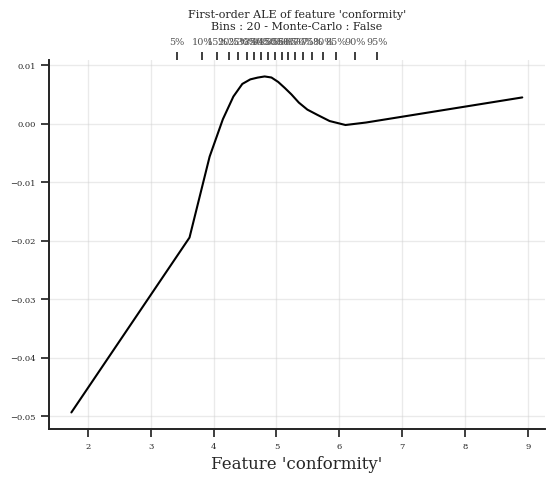

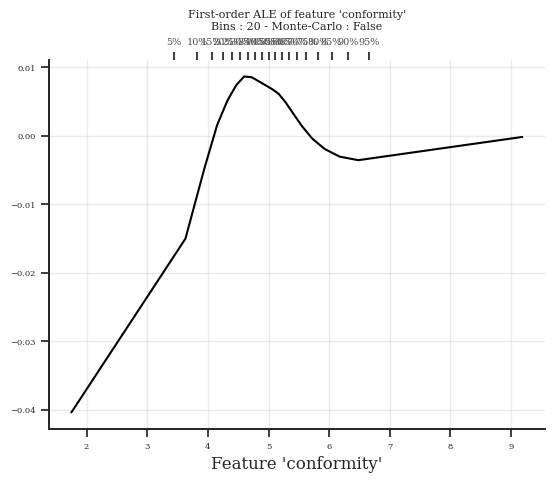

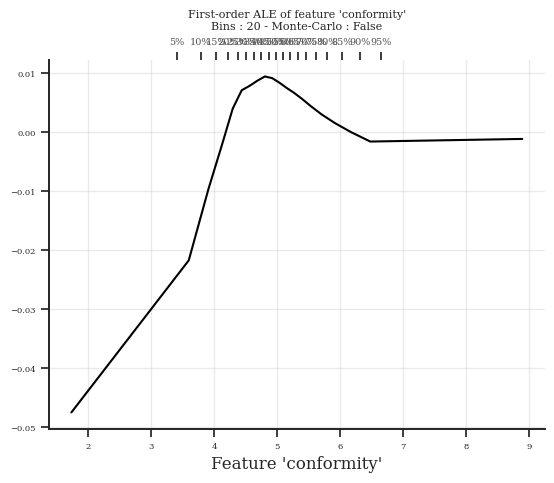

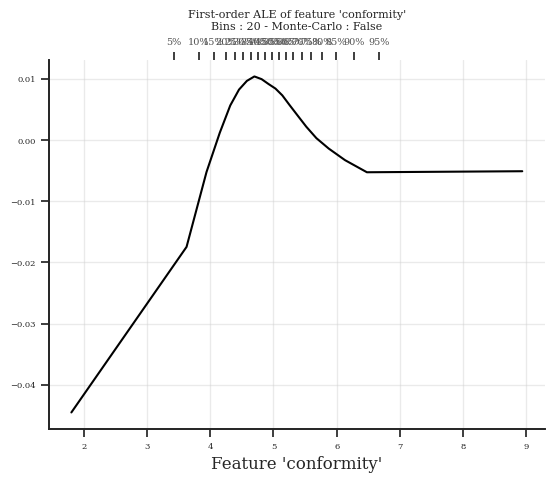

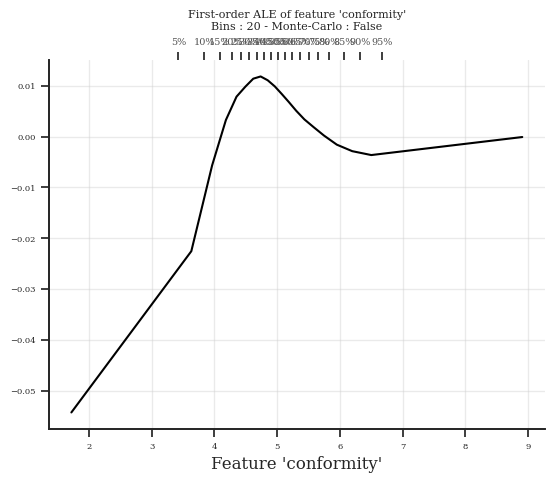

...

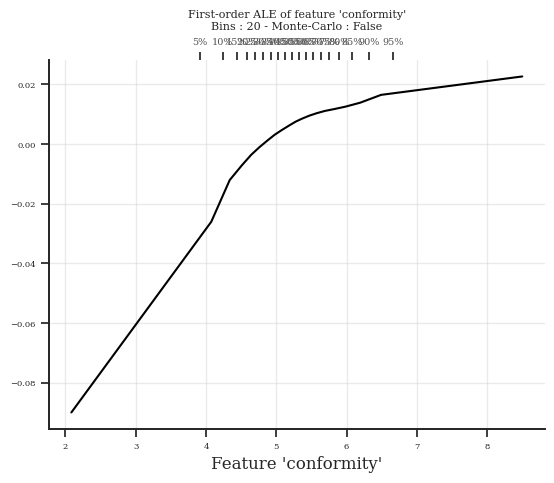

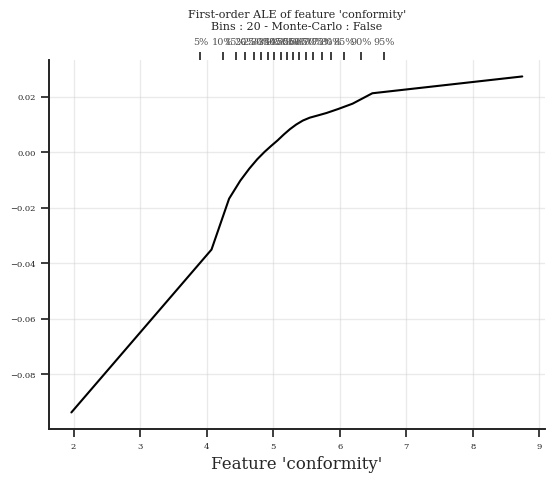

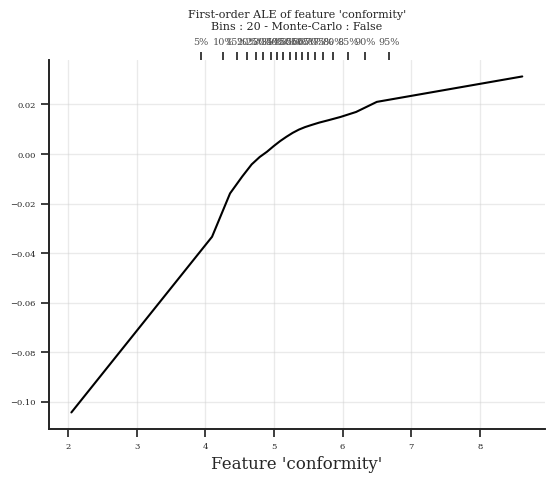

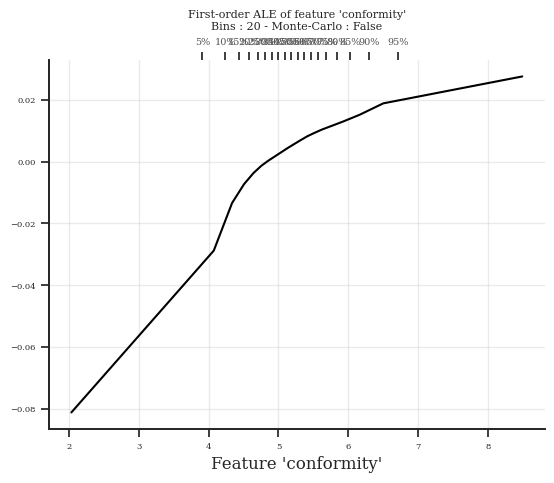

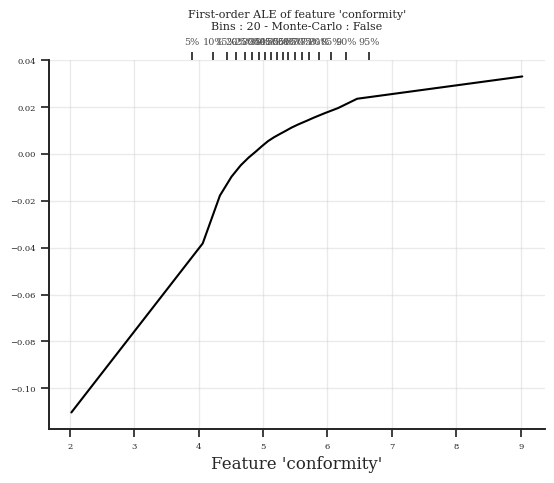

In [13]:
# 计算全局ale，转化成xarray的格式
bins = 20
quantiles = np.unique(
   np.quantile(
       dataset['treatments'].reshape(-1), np.linspace(0, 1, bins + 1), interpolation="lower"
   )
)

bins = (quantiles[1:] + quantiles[:-1]) / 2

data_vars = {}
n_bootstrap = 30


for i in [0,1,2]:
    dataset_year = [dataset19, dataset20, dataset23][i]
    year = [2019, 2020, 2023][i]
    ale = []
    
    for _ in range(n_bootstrap):
        sub_dataset = dataset_sampling(dataset_year, 1000)
        ale_fig, ale_1st, _ = compute_ale(sub_dataset, 'rmsn_'+str(exp_name), b_use_predicted_confounders=False, features = ['conformity'], default_quantiles=quantiles)
        ale.append(ale_1st)
    data_vars[f"conformity__RNN_Model_{year}__ale"] = (["n_bootstrap", f"n_bins__conformity"], ale)

data_vars[f"conformity__bin_values"] = (["n_bins__conformity"], bins)

data_vars[f"conformity"] = (["n_X"],dataset['treatments'][:,:,0].flatten())
    
ale_dataset = xr.Dataset(
    data_vars=data_vars,
    #coords={
    #    "n_bootstrap": np.arange(ale.shape[0]), 
    #    f"n_bins__{feature_name}": np.arange(quantiles.shape[0]),  
    #    "n_X": np.arange(flattened_values.shape[0]),  
    #},
    attrs={
        "estimator_output": "raw",
        "estimators used": ['RNN_Model_2019', 'RNN_Model_2020', 'RNN_Model_2023'],
        "method": "ale",
        "dimension": "1D",
        "features used": "conformity",
    }
)


In [15]:
# save
ale_dataset.to_netcdf(path='figures/figure_data/fig_robustness_3year_noCI.nc')

# read
# ale_dataset = xr.open_dataset('./figures/figure_data/fig_1c.nc')
# ale_dataset

In [16]:
# 还原SCI的log值
conformity_bin_values_log = ale_dataset['conformity__bin_values'].values
conformity_bin_values_original = np.exp(conformity_bin_values_log)-1
ale_dataset['conformity__bin_values'] = (('n_bins__conformity'), conformity_bin_values_original)

conformity_log = ale_dataset['conformity'].values
conformity_original = np.exp(conformity_log)-1
ale_dataset['conformity'] = (('n_X'), conformity_original)

# 将ALE值转换为倍数
ale_values = ale_dataset['conformity__RNN_Model_2019__ale'].values
ale_values_original = np.exp(ale_values)
ale_dataset['conformity__RNN_Model_2019__ale'] = ([('n_bootstrap'),('n_bins__conformity')], ale_values_original)

ale_values = ale_dataset['conformity__RNN_Model_2020__ale'].values
ale_values_original = np.exp(ale_values)
ale_dataset['conformity__RNN_Model_2020__ale'] = ([('n_bootstrap'),('n_bins__conformity')], ale_values_original)

ale_values = ale_dataset['conformity__RNN_Model_2023__ale'].values
ale_values_original = np.exp(ale_values)
ale_dataset['conformity__RNN_Model_2023__ale'] = ([('n_bootstrap'),('n_bins__conformity')], ale_values_original)

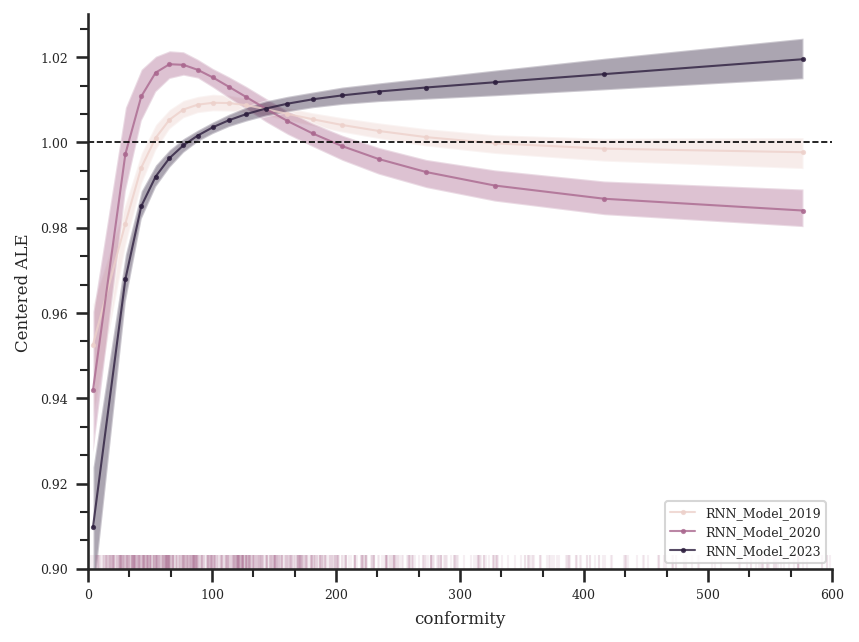

In [18]:
bins_to_keep = ale_dataset['n_bins__conformity'] != ale_dataset['n_bins__conformity'].loc[-1]
ale_dataset_select = ale_dataset.sel(n_bins__conformity=bins_to_keep)

estimator = [('RNN_Model_2019',RandomForestRegressor()),
            ('RNN_Model_2020',RandomForestRegressor()),
            ('RNN_Model_2023',RandomForestRegressor())]

explainer = skexplain.ExplainToolkit(estimator)

# 生成 cubehelix 调色盘
cubehelix_palette = sns.cubehelix_palette(n_colors=3)

fig, ax = plt.subplots(dpi=150)
fig, ax = explainer.plot_ale(
                                   ale = ale_dataset_select,
                                   features='conformity',
                                   display_units=plotting_config.display_units,
                                   display_feature_names=plotting_config.display_feature_names,
                                   line_kws={'marker': 'o', 'markersize':1.5,'linewidth':1, 'line_colors': cubehelix_palette},
hist_color = 'white', 
    edge_color= 'white', ax=ax

                                  )

# ax.set_xscale('log')
ax.set_xlim(left = 0, right = 600)
# ax.set_xlim(left=1, right = 10 ** 5)
# ax.set_xlim(left=1, right = 11)
ax.set_ylim(bottom = 0.9, top = 1.03)

ax.axhline(y=1, color='black', ls='--', lw=0.8)

# ax.tick_params(axis='y', right=False, labelright=False)
# ax.tick_params(axis='y', tick1On=False, tick2On=False)
# ax.spines['bottom'].set_visible(False)
# ax.set_xticks(conformity_bin_values_original)
# ax.set_xticklabels([f'{val:.2f}' for val in conformity_bin_values_original])
ax.set_ylabel('Centered ALE', fontsize = 8)
ax.legend()

# fig.axes[3].remove()
# fig.axes[2].remove()
fig.axes[1].remove()



data = ale_dataset['conformity'].values
if len(data) > 1000:
    data_sample = np.random.choice(data, size=1000, replace=False)
else:
    data_sample = data
sns.rugplot(data_sample, ax=ax, color=cubehelix_palette[-2], alpha=0.1)

# plt.savefig('./figures/fig_1c_yearly_SCI_ale_1st_log_log.png',  dpi=300)
# plt.savefig('./figures/fig_1c_yearly_SCI_ale_1st_SCI_log.png',  dpi=300)
plt.savefig('./figures/fig_1c_yearly_SCI_ale_1st_SCI750.png',  dpi=300)
plt.show()

### 2.3 将figB和figC整合到一张图

In [55]:
ale_dataset_select = xr.open_dataset('figures/figure_data/fig_1b_noCI.nc')
ale_dataset_yearly = xr.open_dataset('figures/figure_data/fig_1c.nc')

数值还原

In [56]:
# 还原SCI的log值
conformity_bin_values_log = ale_dataset_select['conformity__bin_values'].values
conformity_bin_values_original = np.exp(conformity_bin_values_log)-1
ale_dataset_select['conformity__bin_values'] = (('n_bins__conformity'), conformity_bin_values_original)

conformity_log = ale_dataset_select['conformity'].values
conformity_original = np.exp(conformity_log)-1
ale_dataset_select['conformity'] = (('n_X'), conformity_original)

# 将ALE值转换为倍数
ale_values = ale_dataset_select['conformity__RNN_Model__ale'].values
ale_values_original = np.exp(ale_values)
ale_dataset_select['conformity__RNN_Model__ale'] = ([('n_bootstrap'),('n_bins__conformity')], ale_values_original)

In [57]:
# 还原SCI的log值
conformity_bin_values_log = ale_dataset_yearly['conformity__bin_values'].values
conformity_bin_values_original = np.exp(conformity_bin_values_log)-1
ale_dataset_yearly['conformity__bin_values'] = (('n_bins__conformity'), conformity_bin_values_original)

conformity_log = ale_dataset_yearly['conformity'].values
conformity_original = np.exp(conformity_log)-1
ale_dataset_yearly['conformity'] = (('n_X'), conformity_original)

# 将ALE值转换为倍数
ale_values = ale_dataset_yearly['conformity__RNN_Model_2019__ale'].values
ale_values_original = np.exp(ale_values)
ale_dataset_yearly['conformity__RNN_Model_2019__ale'] = ([('n_bootstrap'),('n_bins__conformity')], ale_values_original)

ale_values = ale_dataset_yearly['conformity__RNN_Model_2020__ale'].values
ale_values_original = np.exp(ale_values)
ale_dataset_yearly['conformity__RNN_Model_2020__ale'] = ([('n_bootstrap'),('n_bins__conformity')], ale_values_original)

ale_values = ale_dataset_yearly['conformity__RNN_Model_2023__ale'].values
ale_values_original = np.exp(ale_values)
ale_dataset_yearly['conformity__RNN_Model_2023__ale'] = ([('n_bootstrap'),('n_bins__conformity')], ale_values_original)

In [58]:
# === 1) 预处理（保持不变）===
last_val_overall = ale_dataset_select['n_bins__conformity'].isel(n_bins__conformity=-1)
mask_overall = ale_dataset_select['n_bins__conformity'] != last_val_overall
ale_dataset_select_trim = ale_dataset_select.isel(n_bins__conformity=mask_overall)

last_val_yearly = ale_dataset_yearly['n_bins__conformity'].isel(n_bins__conformity=-1)
mask_yearly = ale_dataset_yearly['n_bins__conformity'] != last_val_yearly
ale_dataset_yearly_trim = ale_dataset_yearly.isel(n_bins__conformity=mask_yearly)

In [59]:
ale_dataset_select_trim

<xarray.Dataset>
Dimensions:                     (n_bootstrap: 1, n_bins__conformity: 19,
                                 n_X: 15456000)
Dimensions without coordinates: n_bootstrap, n_bins__conformity, n_X
Data variables:
    conformity__RNN_Model__ale  (n_bootstrap, n_bins__conformity) float64 0.9...
    conformity__bin_values      (n_bins__conformity) float32 4.005 ... 866.1
    conformity                  (n_X) float32 126.1 119.3 81.13 ... 235.4 100.5
Attributes:
    estimator_output:  raw
    estimators used:   RNN_Model
    method:            ale
    dimension:         1D
    features used:     conformity

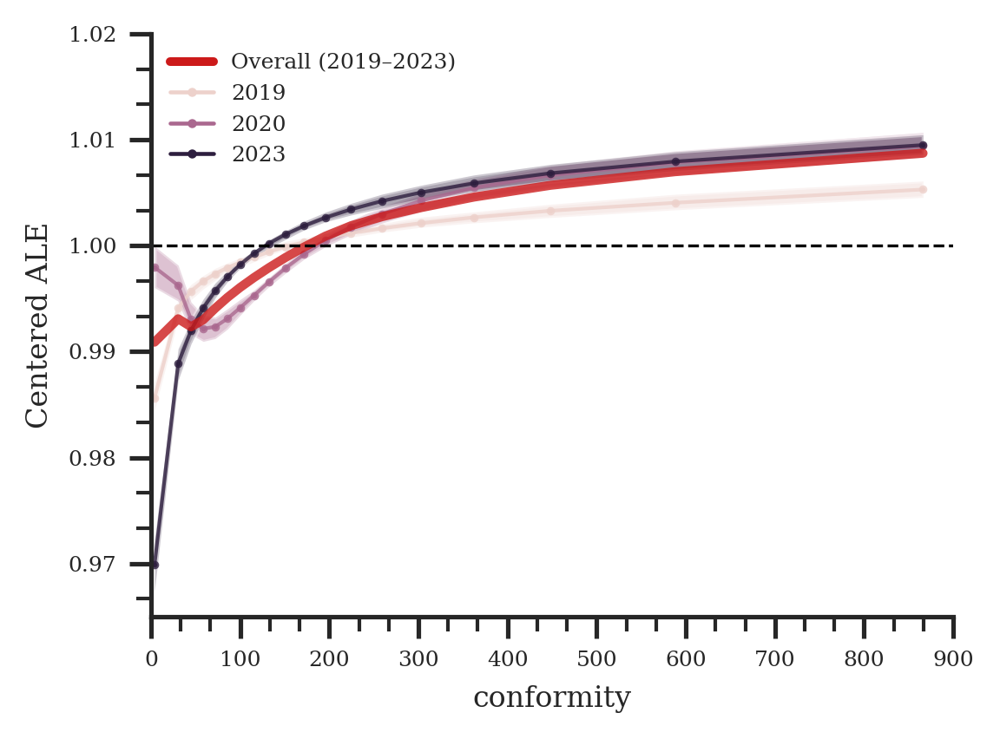

In [77]:
# 绘图
# === 2) explainer（保持不变）===
estimator_overall = [('RNN_Model', RandomForestRegressor())]
explainer_overall = skexplain.ExplainToolkit(estimator_overall)

estimator_yearly = [
    ('RNN_Model_2019', RandomForestRegressor()),
    ('RNN_Model_2020', RandomForestRegressor()),
    ('RNN_Model_2023', RandomForestRegressor()),
]
explainer_yearly = skexplain.ExplainToolkit(estimator_yearly)

# === 3) 调色盘 ===
cubehelix_palette = sns.cubehelix_palette(n_colors=3)

# === 4) 绘图 ===
fig, ax = plt.subplots(figsize=(4,3), dpi=300)

# 1. 分年度三条 ALE —— 仍然用 line_colors=cubehelix_palette
explainer_yearly.plot_ale(
    ale=ale_dataset_yearly_trim,
    features='conformity',
    display_units=plotting_config.display_units,
    display_feature_names=plotting_config.display_feature_names,
    line_kws={'marker': 'o', 'markersize': 1.3, 'linewidth': 1, 'line_colors': cubehelix_palette},
    add_hist=False,
    ax=ax
)

# 2. 整体三年 ALE —— 关键改动：用 line_colors=['black']，不要用 color='black'
explainer_overall.plot_ale(
    ale=ale_dataset_select_trim,
    features='conformity',
    display_units=plotting_config.display_units,
    display_feature_names=plotting_config.display_feature_names,
    line_kws={'linewidth':2.5, 'line_colors':[[0.8, 0.1, 0.1]] },
    add_hist=False,
    plot_confidence=False,
    ax=ax
)

# === 5) 统一外观 ===
ax.axhline(y=1, color='black', ls='--', lw=0.8)
ax.set_xlim(left=0, right=900)
ax.set_ylim(bottom=0.965, top=1.02)
ax.set_ylabel('Centered ALE', fontsize=8)

# === 6) 图例（手工）===
from matplotlib.lines import Line2D
legend_lines = [
    Line2D([0], [0], linewidth=2.4, color=[0.8, 0.1, 0.1], markersize=2, label='Overall (2019–2023)'),
    Line2D([0], [0], marker='o', linewidth=1.1, color=cubehelix_palette[0], markersize=1.5, label='2019'),
    Line2D([0], [0], marker='o', linewidth=1.1, color=cubehelix_palette[1], markersize=1.5, label='2020'),
    Line2D([0], [0], marker='o', linewidth=1.1, color=cubehelix_palette[2], markersize=1.5, label='2023'),
]
ax.legend(handles=legend_lines, loc='best', frameon=False)

plt.tight_layout()
plt.savefig('./figures/fig_1b_global_and_yearly_SCI_ale_1st_SCI_log.png',  dpi=300)
plt.show()


## 2. ALE Curve using equal-width bins

### 2.1 global ALE

In [4]:
dataset = load_data("../data/sample_3w2.h5")

for key in dataset.keys():
    print(key)
    print(dataset[key].shape)
    print(dataset[key].dtype)

covariates
(96000, 161, 23)
float32
outcomes
(96000, 161, 1)
float32
sequence_length
(96000,)
int64
treatments
(96000, 161, 1)
float32


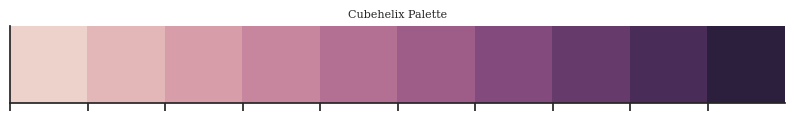

In [5]:
# 模型编号
exp_name = "base_model_optimal_v2"

# 生成 cubehelix 调色盘
cubehelix_palette = sns.cubehelix_palette(n_colors=10)
# 显示调色盘中的所有颜色
sns.palplot(cubehelix_palette)
plt.title('Cubehelix Palette')
plt.show()

2025-12-26 07:24:09.344 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.02084853  3.2383313   3.6754603   3.9642065   4.1898465   4.376632
  4.531341    4.6776385   4.81539     4.9441376   5.072078    5.198497
  5.3370624   5.4807677   5.6375556   5.8073707   5.9994097   6.234129
  6.5337887   6.9853506  11.971748  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 0it [00:00, ?it/s]2025-12-26 07:24:10.784759: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:432] Loaded cuDNN version 8600
Predicting rnn_propensity_weighted: 16it [00:01, 13.00it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.70it/s]
2025-12-26 07:24:13.784 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.02084853  3.2383313   3.6754603   3.9642065   4.1898465   4.376632
  4.531341    4.6776385   4.81539     4.9441376   5.072078    5.198497
  5.3370624   5.4807677   5.6375556   5.8073707   5.9994097   6.234129
  6.5337887   6.9853506  11.971748  ].


[1.6295899 3.4568958 3.8198333 4.0770264 4.2832394 4.4539866 4.60449
 4.7465143 4.8797636 5.008108  5.1352873 5.2677794 5.408915  5.5591617
 5.722463  5.90339   6.1167693 6.383959  6.7595696 9.47855  ]


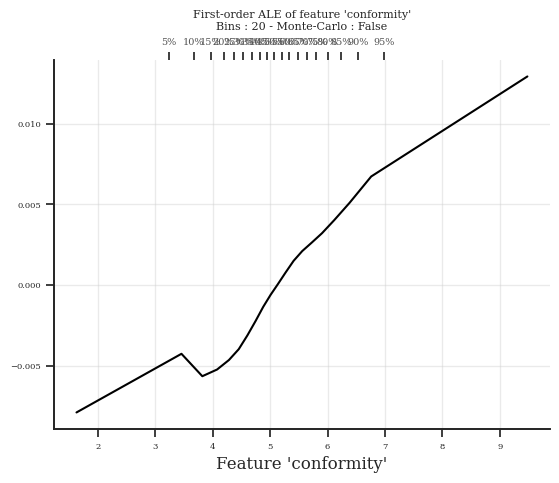

In [6]:
# 计算全局ale，转化成xarray的格式
# 似乎没有固定quantiles，需要再调整一下
bins = 20

t_min = np.min(dataset['treatments'].reshape(-1))
t_max = np.max(dataset['treatments'].reshape(-1))

# 等宽边界（包含左右端点）
quantiles = np.unique(np.linspace(t_min, t_max, bins + 1))

ALE_1ST = {
   'RNN_Model': [],
   }
# n_bootstrap = 30
n_bootstrap = 1

for _ in range(n_bootstrap):
    sub_dataset = dataset_sampling(dataset, 1000)
    ale_fig, ale_1st, _ = compute_ale(sub_dataset, 'rmsn_'+str(exp_name), b_use_predicted_confounders=False, features = ['conformity'], default_quantiles=quantiles)
    ALE_1ST['RNN_Model'].append(ale_1st)
    # window_ale_fig, ale, _ = compute_ale(sub_dataset, 'rmsn_' + str(exp_name), b_use_predicted_confounders=False, features=['week', 'conformity'], default_quantiles=quantiles)
    # ale_1st = np.sum(ale, axis=0)
    # ALE_1ST['RNN_Model'].append(ale_1st)

for key in ALE_1ST.keys():
    ALE_1ST[key] = np.array(ALE_1ST[key])
ale_dataset = create_ale_dataset(ALE_1ST, quantiles, dataset['treatments'], ['RNN_Model'], 'conformity')

the `interpolation=` argument to quantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
2025-12-26 07:08:35.637 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.2244623  3.6816664  3.9753695  4.1907682  4.373972
  4.5397425  4.6893973  4.8328137  4.9733434  5.1059456  5.2447915
  5.384995   5.5309114  5.6897492  5.8634267  6.0619545  6.329471
  6.659968   7.109527  13.562077 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 0it [00:00, ?it/s]2025-12-26 07:08:37.088192: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:432] Loaded cuDNN version 8600
Predicting rnn_propensity_weighted: 16it [00:01, 12.92it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.27it/s]
2025-12-26 07:08:40.038 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.2244623  3.6816664  3.9753695  4.1907682  4.373972
  4.5397425  4.6893973  4.8328137  4.9733434  5.1059456  5.2447915
  5.384995   5.5309114  5.6897492  5.8634267  6.0619545  6.329471
  6.659968   7.109527  13.562077 ].


[ 1.6122311  3.4530644  3.828518   4.083069   4.28237    4.456857
  4.6145697  4.7611055  4.9030786  5.0396442  5.1753683  5.3148932
  5.4579535  5.6103306  5.776588   5.9626904  6.195713   6.4947195
  6.8847475 10.335802 ]


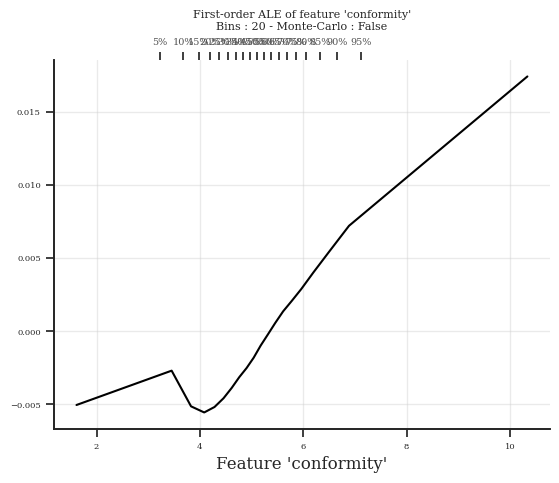

In [6]:
# 计算全局ale，转化成xarray的格式
# 似乎没有固定quantiles，需要再调整一下
bins = 20
quantiles = np.unique(
   np.quantile(
       dataset['treatments'].reshape(-1), np.linspace(0, 1, bins + 1), interpolation="linear"
   )
)
ALE_1ST = {
   'RNN_Model': [],
   }
# n_bootstrap = 30
n_bootstrap = 1

for _ in range(n_bootstrap):
    sub_dataset = dataset_sampling(dataset, 1000)
    ale_fig, ale_1st, _ = compute_ale(sub_dataset, 'rmsn_'+str(exp_name), b_use_predicted_confounders=False, features = ['conformity'], default_quantiles=quantiles)
    ALE_1ST['RNN_Model'].append(ale_1st)
    # window_ale_fig, ale, _ = compute_ale(sub_dataset, 'rmsn_' + str(exp_name), b_use_predicted_confounders=False, features=['week', 'conformity'], default_quantiles=quantiles)
    # ale_1st = np.sum(ale, axis=0)
    # ALE_1ST['RNN_Model'].append(ale_1st)

for key in ALE_1ST.keys():
    ALE_1ST[key] = np.array(ALE_1ST[key])
ale_dataset = create_ale_dataset(ALE_1ST, quantiles, dataset['treatments'], ['RNN_Model'], 'conformity')

In [7]:
# 还原SCI的log值
conformity_bin_values_log = ale_dataset['conformity__bin_values'].values
conformity_bin_values_original = np.exp(conformity_bin_values_log)-1
ale_dataset['conformity__bin_values'] = (('n_bins__conformity'), conformity_bin_values_original)

conformity_log = ale_dataset['conformity'].values
conformity_original = np.exp(conformity_log)-1
ale_dataset['conformity'] = (('n_X'), conformity_original)

ale_dataset

<xarray.Dataset>
Dimensions:                     (n_bootstrap: 1, n_bins__conformity: 20,
                                 n_X: 15456000)
Dimensions without coordinates: n_bootstrap, n_bins__conformity, n_X
Data variables:
    conformity__RNN_Model__ale  (n_bootstrap, n_bins__conformity) float64 -0....
    conformity__bin_values      (n_bins__conformity) float64 0.411 ... 6.781e+05
    conformity                  (n_X) float32 126.1 119.3 81.13 ... 235.4 100.5
Attributes:
    estimator_output:  raw
    estimators used:   ['RNN_Model']
    method:            ale
    dimension:         1D
    features used:     ['conformity']

In [8]:
# 将ALE值转换为倍数
ale_values = ale_dataset['conformity__RNN_Model__ale'].values
ale_values_original = np.exp(ale_values)
ale_dataset['conformity__RNN_Model__ale'] = ([('n_bootstrap'),('n_bins__conformity')], ale_values_original)

倍数y轴 + 整数x轴 + cut 95%

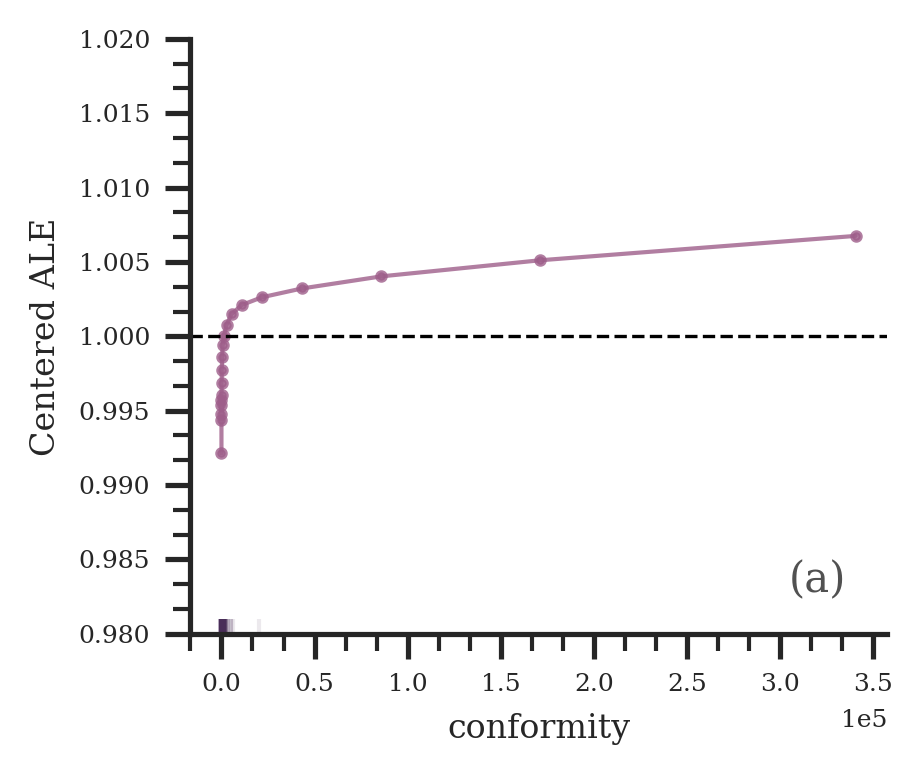

In [10]:
bins_to_keep = ale_dataset['n_bins__conformity'] != ale_dataset['n_bins__conformity'].loc[-1]
ale_dataset_select = ale_dataset.sel(n_bins__conformity=bins_to_keep)

estimator = [('RNN_Model',RandomForestRegressor())]
explainer = skexplain.ExplainToolkit(estimator)

#修改可视化效果
#fig, ax = plt.subplots(dpi=300)
fig, ax = explainer.plot_ale(
                                   ale = ale_dataset_select,
                                   features='conformity',
                                   display_units=plotting_config.display_units,
                                   display_feature_names=plotting_config.display_feature_names,
                                   line_kws={'marker': 'o', 'markersize':2,'linewidth':1, 'line_colors': [cubehelix_palette[5]]},
                                   add_hist = False,
                                  )
ax.axhline(y=1, color='black', ls='--', lw=0.8)

# ax.set_xscale('log')
ax.set_ylabel('Centered ALE', fontsize = 8)
# ax.set_xlim(right = 1000)
# ax.set_xlim(left=1)
ax.set_ylim(bottom = 0.98, top = 1.02)
ax.ticklabel_format(axis='x', style='sci', scilimits=(0, 0))


# ax.set_xticks(conformity_bin_values_original)
# ax.set_xticklabels([f'{val:.2f}' for val in conformity_bin_values_original])

data = ale_dataset['conformity'].values
if len(data) > 1000:
    data_sample = np.random.choice(data, size=1000, replace=False)
else:
    data_sample = data
sns.rugplot(data_sample, ax=ax, color=cubehelix_palette[-2], alpha=0.1)

# plt.savefig('./figures/fig_1b_SCI_ale_1st_raw-1.png',  dpi=300)

plt.show()


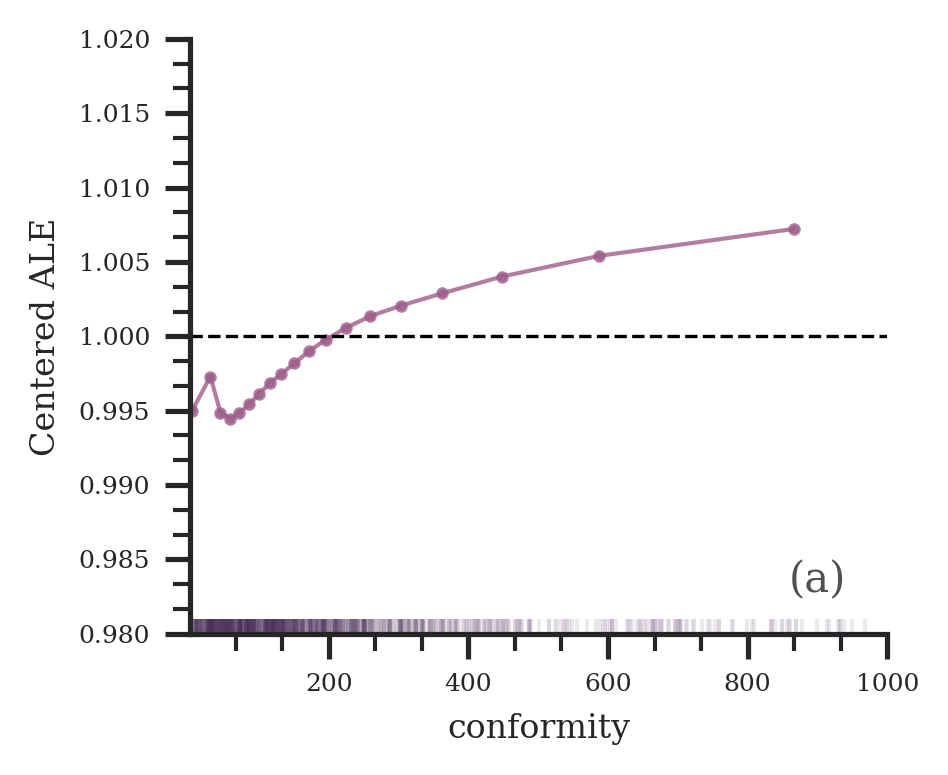

In [10]:
bins_to_keep = ale_dataset['n_bins__conformity'] != ale_dataset['n_bins__conformity'].loc[-1]
ale_dataset_select = ale_dataset.sel(n_bins__conformity=bins_to_keep)

estimator = [('RNN_Model',RandomForestRegressor())]
explainer = skexplain.ExplainToolkit(estimator)

#修改可视化效果
#fig, ax = plt.subplots(dpi=300)
fig, ax = explainer.plot_ale(
                                   ale = ale_dataset_select,
                                   features='conformity',
                                   display_units=plotting_config.display_units,
                                   display_feature_names=plotting_config.display_feature_names,
                                   line_kws={'marker': 'o', 'markersize':2,'linewidth':1, 'line_colors': [cubehelix_palette[5]]},
                                   add_hist = False,
                                  )
ax.axhline(y=1, color='black', ls='--', lw=0.8)

# ax.set_xscale('log')
ax.set_ylabel('Centered ALE', fontsize = 8)
ax.set_xlim(right = 1000)
ax.set_xlim(left=1)
ax.set_ylim(bottom = 0.98, top = 1.02)


# ax.set_xticks(conformity_bin_values_original)
# ax.set_xticklabels([f'{val:.2f}' for val in conformity_bin_values_original])

data = ale_dataset['conformity'].values
if len(data) > 1000:
    data_sample = np.random.choice(data, size=1000, replace=False)
else:
    data_sample = data
sns.rugplot(data_sample, ax=ax, color=cubehelix_palette[-2], alpha=0.1)

# plt.savefig('./figures/fig_1b_SCI_ale_1st_raw-1.png',  dpi=300)

plt.show()


### 2.2 yearly ALE

In [11]:
column_2019 = 12  # index of year 2019 indicator
column_2020 = 13  # index of year 2020 indicator
column_2023 = 14  # index of year 2023 indicator

#dataset19 = obtain_dataset(dataset, column_2019)['treatments'][:,:,0]
#dataset20 = obtain_dataset(dataset, column_2020)['treatments'][:,:,0]
#dataset23 = obtain_dataset(dataset, column_2023)['treatments'][:,:,0]

dataset19 = obtain_dataset(dataset, column_2019)
dataset20 = obtain_dataset(dataset, column_2020)
dataset23 = obtain_dataset(dataset, column_2023)

the `interpolation=` argument to quantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
2025-12-26 07:12:29.048 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4224112  3.8513455  4.1186795  4.3203893  4.485843
  4.6275277  4.764645   4.8949227  5.021556   5.143106   5.2619114
  5.3925605  5.5276804  5.6782017  5.8518257  6.058163   6.3015356
  6.610696   7.077353  13.235176 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.20it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.91it/s]
2025-12-26 07:12:33.058 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4224112  3.8513455  4.1186795  4.3203893  4.485843
  4.6275277  4.764645   4.8949227  5.021556   5.143106   5.2619114
  5.3925605  5.5276804  5.6782017  5.8518257  6.058163   6.3015356
  6.610696   7.077353  13.235176 ].


[ 1.7112056  3.6368785  3.9850125  4.2195344  4.403116   4.5566854
  4.6960864  4.829784   4.9582396  5.0823307  5.202509   5.327236
  5.46012    5.602941   5.7650137  5.954994   6.1798496  6.4561157
  6.8440247 10.156264 ]


2025-12-26 07:12:34.257 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3764894  3.8110273  4.076868   4.2753572  4.44461
  4.5911965  4.725112   4.850208   4.973861   5.099502   5.2290225
  5.3626113  5.4939637  5.6479797  5.8284693  6.0297565  6.2801886
  6.603522   7.09091   11.986616 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.02it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.70it/s]
2025-12-26 07:12:38.336 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3764894  3.8110273  4.076868   4.2753572  4.44461
  4.5911965  4.725112   4.850208   4.973861   5.099502   5.2290225
  5.3626113  5.4939637  5.6479797  5.8284693  6.0297565  6.2801886
  6.603522   7.09091   11.986616 ].


[1.6882447 3.5937583 3.9439478 4.1761127 4.3599834 4.5179033 4.6581545
 4.7876596 4.9120345 5.0366817 5.1642623 5.295817  5.4282875 5.5709715
 5.7382245 5.929113  6.1549726 6.4418554 6.8472157 9.538763 ]


2025-12-26 07:12:39.545 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4244206  3.841787   4.0962167  4.2869873  4.450515
  4.6001015  4.7298627  4.851666   4.9718466  5.0914993  5.2130156
  5.341414   5.4728184  5.626407   5.802407   6.0007505  6.237712
  6.5503197  6.998171  13.1681795].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.34it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.31it/s]
2025-12-26 07:12:43.472 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4244206  3.841787   4.0962167  4.2869873  4.450515
  4.6001015  4.7298627  4.851666   4.9718466  5.0914993  5.2130156
  5.341414   5.4728184  5.626407   5.802407   6.0007505  6.237712
  6.5503197  6.998171  13.1681795].


[ 1.7122103  3.6331038  3.9690018  4.1916018  4.368751   4.525308
  4.664982   4.7907643  4.9117565  5.031673   5.1522574  5.277215
  5.407116   5.549613   5.714407   5.901579   6.119231   6.394016
  6.7742453 10.083176 ]


2025-12-26 07:12:44.623 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3862264  3.8228817  4.0871763  4.2867813  4.4528375
  4.5918493  4.7226367  4.850509   4.9691744  5.088428   5.213789
  5.3450594  5.481067   5.6319213  5.8010216  6.010352   6.2638354
  6.5933685  7.0347304 13.507668 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.26it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.09it/s]
2025-12-26 07:12:48.652 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3862264  3.8228817  4.0871763  4.2867813  4.4528375
  4.5918493  4.7226367  4.850509   4.9691744  5.088428   5.213789
  5.3450594  5.481067   5.6319213  5.8010216  6.010352   6.2638354
  6.5933685  7.0347304 13.507668 ].


[ 1.6931132  3.6045542  3.955029   4.186979   4.369809   4.5223436
  4.657243   4.786573   4.9098415  5.028801   5.1511087  5.279424
  5.413063   5.556494   5.7164717  5.905687   6.1370935  6.428602
  6.8140497 10.271199 ]


2025-12-26 07:12:49.835 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.351968   3.791587   4.067339   4.2669744  4.4347773
  4.5862207  4.7238493  4.854978   4.984139   5.110214   5.2322965
  5.358499   5.5029025  5.659295   5.8363075  6.0495863  6.2934194
  6.630997   7.1094975 12.654121 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.47it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.51it/s]
2025-12-26 07:12:53.851 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.351968   3.791587   4.067339   4.2669744  4.4347773
  4.5862207  4.7238493  4.854978   4.984139   5.110214   5.2322965
  5.358499   5.5029025  5.659295   5.8363075  6.0495863  6.2934194
  6.630997   7.1094975 12.654121 ].


[1.675984  3.5717776 3.929463  4.1671567 4.350876  4.510499  4.655035
 4.7894135 4.9195585 5.0471764 5.171255  5.2953978 5.430701  5.5810986
 5.7478013 5.942947  6.171503  6.4622083 6.8702474 9.881809 ]


2025-12-26 07:12:55.012 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4007807  3.8139012  4.0705643  4.2668753  4.4374533
  4.5833154  4.717076   4.8463387  4.9736514  5.0975757  5.225057
  5.3528605  5.499112   5.654478   5.8313437  6.03753    6.280766
  6.6062374  7.076366  13.214926 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.75it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.67it/s]
2025-12-26 07:12:59.036 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4007807  3.8139012  4.0705643  4.2668753  4.4374533
  4.5833154  4.717076   4.8463387  4.9736514  5.0975757  5.225057
  5.3528605  5.499112   5.654478   5.8313437  6.03753    6.280766
  6.6062374  7.076366  13.214926 ].


[ 1.7003903  3.6073408  3.9422326  4.16872    4.3521643  4.5103846
  4.6501956  4.7817073  4.909995   5.0356135  5.1613164  5.2889585
  5.4259863  5.576795   5.742911   5.934437   6.159148   6.4435015
  6.841302  10.145646 ]


2025-12-26 07:13:00.214 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4439657  3.8456583  4.1006203  4.3059163  4.4705167
  4.6174254  4.745374   4.8726535  4.9985094  5.117499   5.243626
  5.3745546  5.516824   5.664723   5.8419952  6.048262   6.284809
  6.6044273  7.0520277 13.488506 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.21it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.78it/s]
2025-12-26 07:13:04.220 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4439657  3.8456583  4.1006203  4.3059163  4.4705167
  4.6174254  4.745374   4.8726535  4.9985094  5.117499   5.243626
  5.3745546  5.516824   5.664723   5.8419952  6.048262   6.284809
  6.6044273  7.0520277 13.488506 ].


[ 1.7219828  3.644812   3.9731393  4.203268   4.3882165  4.543971
  4.6814     4.809014   4.935581   5.0580044  5.1805625  5.3090906
  5.445689   5.5907736  5.753359   5.9451284  6.1665354  6.444618
  6.8282275 10.2702675]


2025-12-26 07:13:05.400 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3328567  3.7841897  4.065727   4.2840395  4.4577465
  4.6108556  4.7455053  4.875645   5.0039315  5.1271873  5.2530146
  5.381623   5.523669   5.6766396  5.859216   6.0677567  6.314722
  6.61583    7.062826  12.430499 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.01it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.05it/s]
2025-12-26 07:13:09.448 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3328567  3.7841897  4.065727   4.2840395  4.4577465
  4.6108556  4.7455053  4.875645   5.0039315  5.1271873  5.2530146
  5.381623   5.523669   5.6766396  5.859216   6.0677567  6.314722
  6.61583    7.062826  12.430499 ].


[1.6664283 3.5585232 3.9249585 4.1748834 4.370893  4.534301  4.6781807
 4.8105755 4.9397883 5.0655594 5.1901007 5.317319  5.452646  5.600154
 5.767928  5.9634867 6.1912394 6.465276  6.839328  9.746662 ]


2025-12-26 07:13:10.637 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.473659   3.879429   4.1298633  4.3213434  4.485758
  4.6327214  4.765809   4.891224   5.0132093  5.140071   5.26269
  5.3858013  5.5218797  5.6836877  5.849948   6.052564   6.2936735
  6.593508   7.081678  13.562077 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.67it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.06it/s]
2025-12-26 07:13:14.693 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.473659   3.879429   4.1298633  4.3213434  4.485758
  4.6327214  4.765809   4.891224   5.0132093  5.140071   5.26269
  5.3858013  5.5218797  5.6836877  5.849948   6.052564   6.2936735
  6.593508   7.081678  13.562077 ].


[ 1.7368295  3.6765442  4.0046463  4.225603   4.4035506  4.5592394
  4.6992655  4.8285165  4.9522166  5.07664    5.2013807  5.3242455
  5.4538403  5.6027837  5.766818   5.951256   6.1731186  6.4435906
  6.837593  10.3218775]


2025-12-26 07:13:15.867 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4138844  3.822904   4.0723085  4.2679086  4.433234
  4.576404   4.7053537  4.831988   4.9540563  5.073063   5.199436
  5.332533   5.473084   5.6203556  5.794645   5.9889503  6.234408
  6.56038    7.0902467 13.21733  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.46it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.70it/s]
2025-12-26 07:13:19.904 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4138844  3.822904   4.0723085  4.2679086  4.433234
  4.576404   4.7053537  4.831988   4.9540563  5.073063   5.199436
  5.332533   5.473084   5.6203556  5.794645   5.9889503  6.234408
  6.56038    7.0902467 13.21733  ].


[ 1.7069422  3.6183944  3.9476063  4.170109   4.3505716  4.504819
  4.6408787  4.768671   4.893022   5.0135593  5.1362495  5.2659845
  5.402808   5.5467196  5.7075005  5.8917975  6.111679   6.397394
  6.8253136 10.153789 ]


2025-12-26 07:13:21.087 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.38813    3.817099   4.092122   4.282776   4.450534
  4.5963783  4.724271   4.847938   4.969933   5.091439   5.2101464
  5.3460116  5.4840627  5.6434255  5.8245955  6.042633   6.298102
  6.620553   7.117409  13.214926 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.51it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.29it/s]
2025-12-26 07:13:25.209 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.38813    3.817099   4.092122   4.282776   4.450534
  4.5963783  4.724271   4.847938   4.969933   5.091439   5.2101464
  5.3460116  5.4840627  5.6434255  5.8245955  6.042633   6.298102
  6.620553   7.117409  13.214926 ].


[ 1.694065   3.6026144  3.9546106  4.187449   4.366655   4.523456
  4.6603246  4.786104   4.9089355  5.030686   5.1507926  5.278079
  5.415037   5.563744   5.7340107  5.9336143  6.1703672  6.4593277
  6.8689814 10.166167 ]


2025-12-26 07:13:26.416 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3294055  3.7712862  4.0470724  4.253492   4.4310937
  4.58707    4.723497   4.8527117  4.98073    5.104939   5.235408
  5.3674126  5.506079   5.6651406  5.8392863  6.0421205  6.285797
  6.61545    7.123673  13.345301 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.64it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.16it/s]
2025-12-26 07:13:30.624 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3294055  3.7712862  4.0470724  4.253492   4.4310937
  4.58707    4.723497   4.8527117  4.98073    5.104939   5.235408
  5.3674126  5.506079   5.6651406  5.8392863  6.0421205  6.285797
  6.61545    7.123673  13.345301 ].


[ 1.6647028  3.550346   3.9091792  4.150282   4.342293   4.509082
  4.6552835  4.788104   4.916721   5.0428343  5.1701736  5.30141
  5.4367456  5.58561    5.7522135  5.9407034  6.1639585  6.4506235
  6.869561  10.234487 ]


2025-12-26 07:13:31.828 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3464382  3.7786946  4.058785   4.2644305  4.4365325
  4.5892715  4.7307568  4.8616114  4.9881573  5.114506   5.238947
  5.36971    5.5034223  5.65593    5.8275757  6.022842   6.252045
  6.545632   7.0426335 13.214926 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.38it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.68it/s]
2025-12-26 07:13:35.922 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3464382  3.7786946  4.058785   4.2644305  4.4365325
  4.5892715  4.7307568  4.8616114  4.9881573  5.114506   5.238947
  5.36971    5.5034223  5.65593    5.8275757  6.022842   6.252045
  6.545632   7.0426335 13.214926 ].


[ 1.6732191  3.5625663  3.9187398  4.1616077  4.3504815  4.5129023
  4.660014   4.796184   4.9248843  5.0513315  5.1767263  5.3043284
  5.4365664  5.579676   5.7417526  5.925209   6.1374435  6.3988385
  6.7941327 10.128779 ]


2025-12-26 07:13:37.082 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3445504  3.7922516  4.065497   4.280947   4.452584
  4.601539   4.731803   4.859447   4.982724   5.1056466  5.2266984
  5.3572245  5.493444   5.6457973  5.8152924  6.0148916  6.257876
  6.573448   7.05289   13.246157 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.73it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.82it/s]
2025-12-26 07:13:41.055 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3445504  3.7922516  4.065497   4.280947   4.452584
  4.601539   4.731803   4.859447   4.982724   5.1056466  5.2266984
  5.3572245  5.493444   5.6457973  5.8152924  6.0148916  6.257876
  6.573448   7.05289   13.246157 ].


[ 1.6722752  3.5684009  3.9288743  4.173222   4.3667655  4.5270615
  4.666671   4.7956247  4.9210854  5.0441856  5.1661725  5.2919617
  5.425334   5.5696206  5.730545   5.915092   6.136384   6.415662
  6.813169  10.149523 ]


2025-12-26 07:13:42.249 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4250896  3.840106   4.095626   4.290162   4.4524145
  4.5921693  4.7195144  4.8442516  4.971051   5.0906672  5.212092
  5.3392634  5.4811883  5.6304584  5.795671   6.00603    6.255599
  6.593729   7.09259   13.3260565].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.75it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.46it/s]
2025-12-26 07:13:46.229 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4250896  3.840106   4.095626   4.290162   4.4524145
  4.5921693  4.7195144  4.8442516  4.971051   5.0906672  5.212092
  5.3392634  5.4811883  5.6304584  5.795671   6.00603    6.255599
  6.593729   7.09259   13.3260565].


[ 1.7125448  3.632598   3.967866   4.192894   4.3712883  4.522292
  4.655842   4.7818832  4.9076514  5.030859   5.1513796  5.2756777
  5.410226   5.5558233  5.7130647  5.9008503  6.1308146  6.424664
  6.8431597 10.209323 ]


2025-12-26 07:13:47.419 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3423254  3.8124073  4.0976386  4.3068585  4.4766264
  4.62441    4.761884   4.889582   5.007516   5.1248918  5.247203
  5.3713746  5.5139456  5.66335    5.8343472  6.038423   6.2919283
  6.6051154  7.052721  12.700376 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.80it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.73it/s]
2025-12-26 07:13:51.535 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3423254  3.8124073  4.0976386  4.3068585  4.4766264
  4.62441    4.761884   4.889582   5.007516   5.1248918  5.247203
  5.3713746  5.5139456  5.66335    5.8343472  6.038423   6.2919283
  6.6051154  7.052721  12.700376 ].


[1.6711627 3.5773664 3.9550228 4.2022486 4.3917427 4.550518  4.693147
 4.825733  4.9485493 5.066204  5.1860476 5.309289  5.4426603 5.588648
 5.748849  5.936385  6.1651754 6.4485216 6.8289185 9.876549 ]


2025-12-26 07:13:52.734 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.407106   3.8534155  4.114452   4.315828   4.487886
  4.634366   4.761874   4.882695   5.000138   5.1167874  5.23753
  5.3596587  5.4961553  5.6416793  5.812902   6.0091     6.2607846
  6.574106   7.0535073 12.488357 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.92it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.59it/s]
2025-12-26 07:13:56.779 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.407106   3.8534155  4.114452   4.315828   4.487886
  4.634366   4.761874   4.882695   5.000138   5.1167874  5.23753
  5.3596587  5.4961553  5.6416793  5.812902   6.0091     6.2607846
  6.574106   7.0535073 12.488357 ].


[1.703553  3.6302607 3.9839337 4.21514   4.401857  4.5611258 4.69812
 4.8222847 4.9414167 5.0584626 5.177159  5.2985945 5.427907  5.5689173
 5.7272906 5.911001  6.134942  6.417445  6.8138065 9.770932 ]


2025-12-26 07:13:57.990 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3934045  3.82511    4.089184   4.2836623  4.443745
  4.585801   4.718012   4.8478613  4.971431   5.0918155  5.216872
  5.3455577  5.479512   5.625074   5.792662   6.0035496  6.2570367
  6.551341   7.0273294 12.484162 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.61it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.36it/s]
2025-12-26 07:14:02.109 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3934045  3.82511    4.089184   4.2836623  4.443745
  4.585801   4.718012   4.8478613  4.971431   5.0918155  5.216872
  5.3455577  5.479512   5.625074   5.792662   6.0035496  6.2570367
  6.551341   7.0273294 12.484162 ].


[1.6967022 3.6092572 3.957147  4.1864233 4.3637037 4.5147734 4.6519065
 4.7829366 4.909646  5.031623  5.1543436 5.2812147 5.4125347 5.552293
 5.708868  5.8981056 6.130293  6.404189  6.7893353 9.755746 ]


2025-12-26 07:14:03.315 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4504354  3.870514   4.125017   4.3144507  4.470021
  4.60671    4.736927   4.863042   4.9856787  5.1028957  5.227349
  5.3532844  5.4865713  5.6347733  5.8079934  6.0200124  6.2711186
  6.5875216  7.100169  13.564123 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.76it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.48it/s]
2025-12-26 07:14:07.400 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4504354  3.870514   4.125017   4.3144507  4.470021
  4.60671    4.736927   4.863042   4.9856787  5.1028957  5.227349
  5.3532844  5.4865713  5.6347733  5.8079934  6.0200124  6.2711186
  6.5875216  7.100169  13.564123 ].


[ 1.7252177  3.6604748  3.9977655  4.219734   4.3922358  4.5383654
  4.6718187  4.7999845  4.9243603  5.044287   5.165122   5.2903166
  5.4199276  5.5606723  5.721383   5.914003   6.1455655  6.4293203
  6.8438454 10.332146 ]


2025-12-26 07:14:08.635 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4212396  3.8286414  4.0786695  4.27211    4.4381356
  4.5828476  4.713453   4.8395977  4.9633446  5.0825706  5.205003
  5.3348994  5.467949   5.6162667  5.7764072  5.9690795  6.2131987
  6.5158024  7.025772  13.265998 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.45it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.74it/s]
2025-12-26 07:14:12.964 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4212396  3.8286414  4.0786695  4.27211    4.4381356
  4.5828476  4.713453   4.8395977  4.9633446  5.0825706  5.205003
  5.3348994  5.467949   5.6162667  5.7764072  5.9690795  6.2131987
  6.5158024  7.025772  13.265998 ].


[ 1.7106198  3.6249404  3.9536555  4.17539    4.3551226  4.5104914
  4.6481504  4.7765255  4.901471   5.022958   5.1437864  5.269951
  5.4014244  5.5421076  5.6963367  5.8727436  6.091139   6.3645005
  6.7707872 10.145885 ]


More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
2025-12-26 07:14:13.956 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4101226  3.8513942  4.118709   4.322198   4.489448
  4.636948   4.7718415  4.9023843  5.0274625  5.1522937  5.2735295
  5.4009576  5.5429034  5.6993213  5.871551   6.074958   6.3258843
  6.6158857  7.104993  12.864942 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.61it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.95it/s]
2025-12-26 07:14:18.243 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4101226  3.8513942  4.118709   4.322198   4.489448
  4.636948   4.7718415  4.9023843  5.0274625  5.1522937  5.2735295
  5.4009576  5.5429034  5.6993213  5.871551   6.074958   6.3258843
  6.6158857  7.104993  12.864942 ].


[1.7050613 3.6307583 3.9850516 4.2204533 4.4058228 4.563198  4.704395
 4.837113  4.9649234 5.089878  5.2129116 5.3372436 5.4719305 5.6211123
 5.785436  5.973254  6.2004213 6.4708853 6.8604393 9.984967 ]


2025-12-26 07:14:19.225 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.5071635  3.9161267  4.167942   4.3651514  4.525299
  4.674272   4.810322   4.941021   5.0674796  5.188692   5.3163915
  5.4544406  5.5919003  5.7365794  5.9066987  6.1022143  6.3379383
  6.645262   7.1465316 13.3242445].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.50it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.27it/s]
2025-12-26 07:14:23.509 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.5071635  3.9161267  4.167942   4.3651514  4.525299
  4.674272   4.810322   4.941021   5.0674796  5.188692   5.3163915
  5.4544406  5.5919003  5.7365794  5.9066987  6.1022143  6.3379383
  6.645262   7.1465316 13.3242445].


[ 1.7535818  3.7116451  4.042034   4.2665467  4.4452252  4.599786
  4.742297   4.8756714  5.0042505  5.128086   5.2525415  5.385416
  5.5231705  5.66424    5.821639   6.0044565  6.2200766  6.4916
  6.895897  10.235388 ]


2025-12-26 07:14:24.481 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4339871  3.8319345  4.091532   4.2942796  4.462331
  4.6064434  4.743959   4.8726735  4.9956923  5.124982   5.2455473
  5.380293   5.526544   5.685416   5.850909   6.0617437  6.305627
  6.626416   7.098082  13.562077 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.50it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.54it/s]
2025-12-26 07:14:28.631 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4339871  3.8319345  4.091532   4.2942796  4.462331
  4.6064434  4.743959   4.8726735  4.9956923  5.124982   5.2455473
  5.380293   5.526544   5.685416   5.850909   6.0617437  6.305627
  6.626416   7.098082  13.562077 ].


[ 1.7169936  3.6329608  3.9617333  4.192906   4.3783054  4.534387
  4.6752014  4.808316   4.934183   5.060337   5.1852646  5.31292
  5.4534187  5.60598    5.7681627  5.9563265  6.1836853  6.4660215
  6.8622494 10.330079 ]


2025-12-26 07:14:29.592 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4214742  3.8607073  4.125235   4.3191433  4.4778113
  4.6212897  4.751063   4.877809   5.000144   5.120264   5.2450075
  5.367417   5.509621   5.654675   5.833499   6.049336   6.287011
  6.612213   7.07073   13.374073 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.46it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.07it/s]
2025-12-26 07:14:33.880 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4214742  3.8607073  4.125235   4.3191433  4.4778113
  4.6212897  4.751063   4.877809   5.000144   5.120264   5.2450075
  5.367417   5.509621   5.654675   5.833499   6.049336   6.287011
  6.612213   7.07073   13.374073 ].


[ 1.7107371  3.6410909  3.9929712  4.222189   4.3984776  4.5495505
  4.6861763  4.814436   4.9389763  5.060204   5.182636   5.3062124
  5.438519   5.582148   5.744087   5.9414177  6.168174   6.449612
  6.8414717 10.222402 ]


2025-12-26 07:14:34.836 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3780189  3.7989783  4.065209   4.268861   4.4350867
  4.5844946  4.7160106  4.8428626  4.9685044  5.0922604  5.216733
  5.3534727  5.4980893  5.6560726  5.829436   6.0271144  6.2605925
  6.569242   7.0149226 13.270095 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.38it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.69it/s]
2025-12-26 07:14:39.016 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3780189  3.7989783  4.065209   4.268861   4.4350867
  4.5844946  4.7160106  4.8428626  4.9685044  5.0922604  5.216733
  5.3534727  5.4980893  5.6560726  5.829436   6.0271144  6.2605925
  6.569242   7.0149226 13.270095 ].


[ 1.6890094  3.5884986  3.9320936  4.167035   4.3519735  4.5097904
  4.6502523  4.7794366  4.9056835  5.030382   5.1544967  5.285103
  5.4257812  5.5770807  5.742754   5.928275   6.143853   6.414917
  6.7920823 10.1425085]


2025-12-26 07:14:40.010 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3627794  3.787278   4.050732   4.2487226  4.422736
  4.5702195  4.7051034  4.835654   4.9621296  5.081825   5.2064123
  5.335124   5.4779744  5.6301928  5.8097806  6.016097   6.270096
  6.5773025  7.0987535 12.811129 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.22it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.95it/s]
2025-12-26 07:14:44.336 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3627794  3.787278   4.050732   4.2487226  4.422736
  4.5702195  4.7051034  4.835654   4.9621296  5.081825   5.2064123
  5.335124   5.4779744  5.6301928  5.8097806  6.016097   6.270096
  6.5773025  7.0987535 12.811129 ].


[1.6813897 3.5750287 3.919005  4.1497273 4.3357296 4.496478  4.6376615
 4.7703786 4.8988914 5.0219774 5.1441183 5.270768  5.4065495 5.554084
 5.719987  5.912939  6.1430964 6.4236994 6.838028  9.954941 ]


2025-12-26 07:14:45.314 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4465308  3.867466   4.12425    4.315615   4.4784503
  4.622108   4.7534065  4.8818107  5.004846   5.130675   5.256783
  5.3795815  5.5146737  5.66177    5.8320227  6.023976   6.2606535
  6.5570855  7.0003996 13.212517 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.90it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.92it/s]
2025-12-26 07:14:49.593 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4465308  3.867466   4.12425    4.315615   4.4784503
  4.622108   4.7534065  4.8818107  5.004846   5.130675   5.256783
  5.3795815  5.5146737  5.66177    5.8320227  6.023976   6.2606535
  6.5570855  7.0003996 13.212517 ].


[ 1.7232654  3.6569984  3.995858   4.2199326  4.3970327  4.550279
  4.6877575  4.817609   4.9433284  5.0677605  5.193729   5.318182
  5.4471273  5.5882215  5.7468963  5.9279995  6.142315   6.4088697
  6.778743  10.106459 ]


2025-12-26 07:14:50.567 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4229133  3.8419533  4.0989656  4.293858   4.4577403
  4.6056604  4.742577   4.862132   4.988571   5.110105   5.230752
  5.3574133  5.493231   5.6409326  5.811273   6.007025   6.2514386
  6.5464253  7.066544  13.305985 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.68it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.53it/s]
2025-12-26 07:14:54.890 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4229133  3.8419533  4.0989656  4.293858   4.4577403
  4.6056604  4.742577   4.862132   4.988571   5.110105   5.230752
  5.3574133  5.493231   5.6409326  5.811273   6.007025   6.2514386
  6.5464253  7.066544  13.305985 ].


[ 1.7114567  3.6324334  3.9704595  4.196412   4.375799   4.5317
  4.674119   4.802355   4.9253516  5.0493383  5.1704283  5.2940826
  5.425322   5.5670815  5.726103   5.909149   6.1292315  6.398932
  6.8064847 10.186265 ]


2025-12-26 07:14:55.853 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4361842  3.8336868  4.0918884  4.2972593  4.4653077
  4.6151204  4.7420635  4.86265    4.987647   5.1104603  5.2353673
  5.3681617  5.5102844  5.659792   5.8271704  6.0189013  6.255925
  6.5611315  7.060175  13.370989 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.82it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.53it/s]
2025-12-26 07:15:00.063 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4361842  3.8336868  4.0918884  4.2972593  4.4653077
  4.6151204  4.7420635  4.86265    4.987647   5.1104603  5.2353673
  5.3681617  5.5102844  5.659792   5.8271704  6.0189013  6.255925
  6.5611315  7.060175  13.370989 ].


[ 1.7180921  3.6349354  3.9627876  4.194574   4.3812838  4.540214
  4.6785917  4.8023567  4.9251485  5.0490537  5.1729136  5.3017645
  5.4392233  5.585038   5.743481   5.9230356  6.137413   6.4085283
  6.810653  10.215582 ]


2025-12-26 07:15:01.031 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.386215   3.8237627  4.094543   4.291335   4.4617
  4.6091857  4.746277   4.8786483  5.007039   5.137369   5.2693386
  5.397771   5.525189   5.672588   5.8400307  6.0280623  6.2704916
  6.593484   7.1129456 13.509625 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.81it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.45it/s]
2025-12-26 07:15:05.318 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.386215   3.8237627  4.094543   4.291335   4.4617
  4.6091857  4.746277   4.8786483  5.007039   5.137369   5.2693386
  5.397771   5.525189   5.672588   5.8400307  6.0280623  6.2704916
  6.593484   7.1129456 13.509625 ].


[ 1.6931075  3.6049888  3.9591527  4.192939   4.3765173  4.535443
  4.6777315  4.812463   4.9428434  5.072204   5.203354   5.3335547
  5.46148    5.5988884  5.7563095  5.9340467  6.1492767  6.431988
  6.8532147 10.311285 ]


2025-12-26 07:15:06.276 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.8345494  3.253477   3.5262966  3.7418735  3.9242718
  4.089624   4.2332087  4.3666     4.500489   4.634896   4.7644258
  4.8921013  5.0257463  5.1754127  5.3473396  5.5409956  5.778638
  6.097532   6.6004553 10.47195  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.29it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.25it/s]
2025-12-26 07:15:10.544 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.8345494  3.253477   3.5262966  3.7418735  3.9242718
  4.089624   4.2332087  4.3666     4.500489   4.634896   4.7644258
  4.8921013  5.0257463  5.1754127  5.3473396  5.5409956  5.778638
  6.097532   6.6004553 10.47195  ].


[1.4172747 3.0440133 3.3898869 3.6340852 3.8330727 4.006948  4.161416
 4.2999043 4.4335446 4.5676928 4.699661  4.8282633 4.958924  5.1005793
 5.2613764 5.4441676 5.6598167 5.9380846 6.3489933 8.536202 ]


2025-12-26 07:15:11.516 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.7725887  3.1982121  3.4920163  3.7142982  3.9103599
  4.069027   4.2171535  4.3564777  4.48458    4.614401   4.7426443
  4.8720818  5.0103517  5.1656985  5.3306     5.52891    5.770783
  6.089153   6.5496144 10.396536 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.89it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.31it/s]
2025-12-26 07:15:15.716 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.7725887  3.1982121  3.4920163  3.7142982  3.9103599
  4.069027   4.2171535  4.3564777  4.48458    4.614401   4.7426443
  4.8720818  5.0103517  5.1656985  5.3306     5.52891    5.770783
  6.089153   6.5496144 10.396536 ].


[1.3862944 2.9854004 3.3451142 3.6031573 3.812329  3.9896934 4.1430902
 4.2868156 4.420529  4.5494905 4.6785226 4.807363  4.9412165 5.088025
 5.248149  5.429755  5.6498466 5.929968  6.3193836 8.473075 ]


2025-12-26 07:15:16.688 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.8427093  3.2531939  3.5307562  3.7489445  3.932456
  4.0915318  4.239875   4.379971   4.5132117  4.6457014  4.7713833
  4.9000163  5.0412154  5.18707    5.362596   5.5701556  5.8141785
  6.1377807  6.662279  10.793712 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.69it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.07it/s]
2025-12-26 07:15:21.007 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.8427093  3.2531939  3.5307562  3.7489445  3.932456
  4.0915318  4.239875   4.379971   4.5132117  4.6457014  4.7713833
  4.9000163  5.0412154  5.18707    5.362596   5.5701556  5.8141785
  6.1377807  6.662279  10.793712 ].


[1.4213547 3.0479517 3.391975  3.6398504 3.8407001 4.011994  4.1657033
 4.309923  4.4465914 4.5794563 4.7085423 4.8357    4.970616  5.1141424
 5.2748327 5.466376  5.6921673 5.97598   6.40003   8.727995 ]


2025-12-26 07:15:21.990 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.        2.831249  3.2384832 3.5130742 3.730069  3.9179134 4.0794544
 4.2194867 4.356603  4.490269  4.620774  4.753899  4.8907094 5.0388246
 5.20634   5.3885474 5.592268  5.844493  6.1802793 6.633606  9.723823 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.34it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.52it/s]
2025-12-26 07:15:26.257 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.        2.831249  3.2384832 3.5130742 3.730069  3.9179134 4.0794544
 4.2194867 4.356603  4.490269  4.620774  4.753899  4.8907094 5.0388246
 5.20634   5.3885474 5.592268  5.844493  6.1802793 6.633606  9.723823 ].


[1.4156245 3.034866  3.3757787 3.6215715 3.8239913 3.998684  4.1494703
 4.288045  4.423436  4.5555215 4.6873364 4.8223042 4.964767  5.1225824
 5.2974434 5.490408  5.7183805 6.0123863 6.4069424 8.178715 ]


2025-12-26 07:15:27.220 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.02207599 2.8053052  3.245996   3.521139   3.733488   3.9086866
 4.0590744  4.2021747  4.3364844  4.4686728  4.597209   4.7272444
 4.8581104  4.9986353  5.145027   5.313095   5.5156837  5.749327
 6.0617495  6.5732183  9.862718  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.77it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.06it/s]
2025-12-26 07:15:31.459 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.02207599 2.8053052  3.245996   3.521139   3.733488   3.9086866
 4.0590744  4.2021747  4.3364844  4.4686728  4.597209   4.7272444
 4.8581104  4.9986353  5.145027   5.313095   5.5156837  5.749327
 6.0617495  6.5732183  9.862718  ].


[1.4136906 3.0256505 3.3835673 3.6273136 3.8210874 3.9838805 4.130625
 4.2693295 4.4025784 4.532941  4.6622267 4.7926774 4.928373  5.071831
 5.229061  5.4143896 5.6325054 5.9055386 6.317484  8.217968 ]


2025-12-26 07:15:32.412 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.799655   3.2396183  3.5296035  3.7563634  3.945851
  4.1148205  4.2635484  4.4038177  4.5336647  4.6638494  4.7923036
  4.9215255  5.0574064  5.2049084  5.368975   5.562734   5.8119187
  6.1398797  6.612425  10.490468 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.54it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.38it/s]
2025-12-26 07:15:36.689 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.799655   3.2396183  3.5296035  3.7563634  3.945851
  4.1148205  4.2635484  4.4038177  4.5336647  4.6638494  4.7923036
  4.9215255  5.0574064  5.2049084  5.368975   5.562734   5.8119187
  6.1398797  6.612425  10.490468 ].


[1.3998275 3.0196366 3.384611  3.6429834 3.8511071 4.030336  4.189184
 4.333683  4.4687414 4.598757  4.7280765 4.8569145 4.9894657 5.1311574
 5.2869415 5.4658546 5.6873264 5.975899  6.376152  8.551447 ]


2025-12-26 07:15:37.654 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.7696955  3.2013316  3.4791045  3.7022324  3.8837438
  4.0456395  4.198087   4.336575   4.471491   4.6039557  4.7366166
  4.8708997  5.0151863  5.1812825  5.3607492  5.5681534  5.8326654
  6.1644382  6.6402884 11.554845 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.77it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.48it/s]
2025-12-26 07:15:41.978 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.7696955  3.2013316  3.4791045  3.7022324  3.8837438
  4.0456395  4.198087   4.336575   4.471491   4.6039557  4.7366166
  4.8708997  5.0151863  5.1812825  5.3607492  5.5681534  5.8326654
  6.1644382  6.6402884 11.554845 ].


[1.3848478 2.9855137 3.340218  3.5906684 3.792988  3.9646916 4.1218634
 4.267331  4.4040327 4.5377235 4.670286  4.803758  4.9430428 5.098234
 5.271016  5.4644513 5.7004094 5.998552  6.4023633 9.097567 ]


2025-12-26 07:15:42.942 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.        2.8075874 3.2180762 3.4945507 3.7134004 3.8991776 4.0622196
 4.2128744 4.3482566 4.479568  4.6042933 4.7280555 4.860259  4.992926
 5.1381803 5.2937126 5.477324  5.695925  6.0180345 6.4926577 9.992917 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.70it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.97it/s]
2025-12-26 07:15:47.244 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.        2.8075874 3.2180762 3.4945507 3.7134004 3.8991776 4.0622196
 4.2128744 4.3482566 4.479568  4.6042933 4.7280555 4.860259  4.992926
 5.1381803 5.2937126 5.477324  5.695925  6.0180345 6.4926577 9.992917 ].


[1.4037937 3.0128317 3.3563135 3.6039755 3.806289  3.9806986 4.137547
 4.2805653 4.4139123 4.5419307 4.6661744 4.794157  4.926593  5.065553
 5.215946  5.385518  5.5866246 5.85698   6.2553463 8.242787 ]


2025-12-26 07:15:48.249 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.7846906  3.2217567  3.507574   3.7260501  3.9071183
  4.072988   4.2260547  4.3655663  4.4988976  4.630194   4.7656527
  4.902461   5.0405993  5.1948767  5.3685846  5.567265   5.8186255
  6.1287403  6.5724716 11.776605 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.71it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.63it/s]
2025-12-26 07:15:52.531 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.7846906  3.2217567  3.507574   3.7260501  3.9071183
  4.072988   4.2260547  4.3655663  4.4988976  4.630194   4.7656527
  4.902461   5.0405993  5.1948767  5.3685846  5.567265   5.8186255
  6.1287403  6.5724716 11.776605 ].


[1.3923453 3.0032237 3.3646655 3.6168122 3.816584  3.9900532 4.1495214
 4.2958107 4.432232  4.5645456 4.6979237 4.834057  4.97153   5.117738
 5.2817307 5.467925  5.6929455 5.973683  6.350606  9.174538 ]


2025-12-26 07:15:53.493 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.7995682  3.2203538  3.4994934  3.7220182  3.912392
  4.0757713  4.2233443  4.3621755  4.4952197  4.6280956  4.7601047
  4.8928676  5.0315676  5.1787395  5.3423567  5.5471773  5.790372
  6.10212    6.5689783 10.223431 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.75it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.66it/s]
2025-12-26 07:15:57.693 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.7995682  3.2203538  3.4994934  3.7220182  3.912392
  4.0757713  4.2233443  4.3621755  4.4952197  4.6280956  4.7601047
  4.8928676  5.0315676  5.1787395  5.3423567  5.5471773  5.790372
  6.10212    6.5689783 10.223431 ].


[1.3997841 3.0099611 3.3599236 3.610756  3.817205  3.9940815 4.149558
 4.29276   4.4286976 4.561658  4.6941004 4.826486  4.9622173 5.1051536
 5.260548  5.444767  5.6687746 5.946246  6.3355494 8.396204 ]


2025-12-26 07:15:58.655 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.8057556  3.2363517  3.5136309  3.726536   3.911153
  4.0724354  4.2187862  4.354749   4.4847355  4.6144867  4.742417
  4.869947   5.014612   5.16262    5.336234   5.5397344  5.8004384
  6.1327653  6.6183796 10.793712 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.63it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.21it/s]
2025-12-26 07:16:02.891 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.8057556  3.2363517  3.5136309  3.726536   3.911153
  4.0724354  4.2187862  4.354749   4.4847355  4.6144867  4.742417
  4.869947   5.014612   5.16262    5.336234   5.5397344  5.8004384
  6.1327653  6.6183796 10.793712 ].


[1.4028778 3.0210538 3.3749914 3.6200833 3.8188446 3.991794  4.145611
 4.286768  4.4197426 4.549611  4.6784515 4.806182  4.94228   5.0886164
 5.249427  5.4379845 5.6700864 5.966602  6.375572  8.706045 ]


2025-12-26 07:16:03.881 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.8338366  3.2601273  3.537749   3.7632732  3.9572382
  4.1219535  4.2668166  4.4058323  4.5408945  4.673567   4.8027945
  4.933972   5.069415   5.2205606  5.3834195  5.5763574  5.8170567
  6.151263   6.6337137 12.062324 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.66it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.42it/s]
2025-12-26 07:16:08.182 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.8338366  3.2601273  3.537749   3.7632732  3.9572382
  4.1219535  4.2668166  4.4058323  4.5408945  4.673567   4.8027945
  4.933972   5.069415   5.2205606  5.3834195  5.5763574  5.8170567
  6.151263   6.6337137 12.062324 ].


[1.4169183 3.0469818 3.3989382 3.6505113 3.8602557 4.0395956 4.194385
 4.3363247 4.4733634 4.6072307 4.7381806 4.8683834 5.0016937 5.144988
 5.30199   5.4798884 5.696707  5.98416   6.3924885 9.348019 ]


2025-12-26 07:16:09.180 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.8126006  3.2417328  3.5176327  3.736654   3.9167447
  4.0741777  4.2166266  4.3492427  4.4745617  4.595404   4.717795
  4.8455863  4.9773574  5.117289   5.276264   5.4638     5.6898313
  6.009234   6.4842052 10.396536 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.42it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.50it/s]
2025-12-26 07:16:13.495 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.8126006  3.2417328  3.5176327  3.736654   3.9167447
  4.0741777  4.2166266  4.3492427  4.4745617  4.595404   4.717795
  4.8455863  4.9773574  5.117289   5.276264   5.4638     5.6898313
  6.009234   6.4842052 10.396536 ].


[1.4063003 3.0271668 3.3796828 3.6271434 3.8266993 3.9954612 4.145402
 4.2829347 4.4119024 4.5349827 4.6565995 4.7816906 4.911472  5.047323
 5.1967764 5.3700323 5.5768156 5.8495326 6.2467194 8.440371 ]


2025-12-26 07:16:14.475 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.        2.8068657 3.2381756 3.5164516 3.7339764 3.9203293 4.0862613
 4.234533  4.378373  4.5139847 4.640488  4.774422  4.9049864 5.0483284
 5.208876  5.391211  5.603962  5.861678  6.179959  6.635466  9.78307  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.94it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.73it/s]
2025-12-26 07:16:18.926 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.        2.8068657 3.2381756 3.5164516 3.7339764 3.9203293 4.0862613
 4.234533  4.378373  4.5139847 4.640488  4.774422  4.9049864 5.0483284
 5.208876  5.391211  5.603962  5.861678  6.179959  6.635466  9.78307  ].


[1.4034328 3.0225205 3.3773136 3.625214  3.8271527 4.0032954 4.160397
 4.3064528 4.446179  4.577236  4.707455  4.8397045 4.9766574 5.128602
 5.3000436 5.4975863 5.73282   6.0208187 6.4077125 8.209268 ]


2025-12-26 07:16:19.907 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.7682724  3.1993647  3.488848   3.7095828  3.8992088
  4.065855   4.21503    4.354468   4.4864483  4.6188884  4.749048
  4.885856   5.027779   5.182007   5.3634667  5.5768147  5.83757
  6.1651382  6.6150765 12.491744 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.64it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.28it/s]
2025-12-26 07:16:24.246 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.7682724  3.1993647  3.488848   3.7095828  3.8992088
  4.065855   4.21503    4.354468   4.4864483  4.6188884  4.749048
  4.885856   5.027779   5.182007   5.3634667  5.5768147  5.83757
  6.1651382  6.6150765 12.491744 ].


[1.3841362 2.9838185 3.3441062 3.5992155 3.8043957 3.982532  4.140443
 4.284749  4.420458  4.5526686 4.6839685 4.8174524 4.9568176 5.1048927
 5.2727365 5.4701405 5.7071924 6.001354  6.390107  9.553411 ]


2025-12-26 07:16:25.223 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.7565942  3.186336   3.4768238  3.7011373  3.892253
  4.0598207  4.206972   4.346355   4.4848723  4.61551    4.742295
  4.878984   5.02545    5.180348   5.3447347  5.5433784  5.780309
  6.118783   6.5931163 11.244667 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.99it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.00it/s]
2025-12-26 07:16:29.600 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.7565942  3.186336   3.4768238  3.7011373  3.892253
  4.0598207  4.206972   4.346355   4.4848723  4.61551    4.742295
  4.878984   5.02545    5.180348   5.3447347  5.5433784  5.780309
  6.118783   6.5931163 11.244667 ].


[1.3782971 2.971465  3.33158   3.5889807 3.7966952 3.9760368 4.133396
 4.276664  4.4156137 4.550191  4.6789026 4.8106394 4.952217  5.102899
 5.2625413 5.4440565 5.661844  5.949546  6.3559494 8.918892 ]


2025-12-26 07:16:30.610 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.7773268  3.2114801  3.4927125  3.7147806  3.9028988
  4.069181   4.2181344  4.3576417  4.49343    4.6209154  4.745044
  4.875087   5.0105987  5.158697   5.323721   5.517022   5.763703
  6.093836   6.539782  11.244667 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.65it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.54it/s]
2025-12-26 07:16:35.055 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.7773268  3.2114801  3.4927125  3.7147806  3.9028988
  4.069181   4.2181344  4.3576417  4.49343    4.6209154  4.745044
  4.875087   5.0105987  5.158697   5.323721   5.517022   5.763703
  6.093836   6.539782  11.244667 ].


[1.3886634 2.9944034 3.3520963 3.6037464 3.8088398 3.9860399 4.1436577
 4.287888  4.425536  4.557173  4.6829796 4.8100653 4.9428425 5.084648
 5.241209  5.4203715 5.6403627 5.928769  6.3168087 8.892224 ]


2025-12-26 07:16:36.034 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.8174314  3.2280643  3.5040874  3.7221158  3.9075403
  4.0746346  4.22177    4.3569794  4.4930534  4.624882   4.757095
  4.891427   5.030673   5.1845946  5.355889   5.5517764  5.795343
  6.128772   6.6181736 11.776605 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.74it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.44it/s]
2025-12-26 07:16:40.282 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.8174314  3.2280643  3.5040874  3.7221158  3.9075403
  4.0746346  4.22177    4.3569794  4.4930534  4.624882   4.757095
  4.891427   5.030673   5.1845946  5.355889   5.5517764  5.795343
  6.128772   6.6181736 11.776605 ].


[1.4087157 3.022748  3.366076  3.6131015 3.814828  3.9910874 4.148202
 4.2893744 4.4250164 4.5589676 4.6909885 4.8242607 4.96105   5.1076336
 5.2702417 5.4538326 5.6735597 5.962057  6.3734727 9.19739  ]


2025-12-26 07:16:41.275 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.8182073  3.2330241  3.500187   3.7195034  3.9072227
  4.074506   4.2281723  4.3681803  4.503331   4.627472   4.757147
  4.8961964  5.0411935  5.1946406  5.370133   5.5715036  5.8151407
  6.134095   6.6390867 10.793712 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.70it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.53it/s]
2025-12-26 07:16:45.623 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.8182073  3.2330241  3.500187   3.7195034  3.9072227
  4.074506   4.2281723  4.3681803  4.503331   4.627472   4.757147
  4.8961964  5.0411935  5.1946406  5.370133   5.5715036  5.8151407
  6.134095   6.6390867 10.793712 ].


[1.4091036 3.0256157 3.3666055 3.6098452 3.813363  3.9908643 4.151339
 4.2981763 4.4357557 4.5654016 4.6923094 4.8266716 4.9686947 5.117917
 5.282387  5.4708185 5.693322  5.974618  6.386591  8.716399 ]


2025-12-26 07:16:46.654 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.        2.7725887 3.2069852 3.489945  3.711337  3.8966374 4.0641046
 4.209652  4.347934  4.477909  4.6068354 4.7412786 4.879081  5.0144215
 5.170833  5.3389435 5.535785  5.795445  6.1186438 6.5575867 9.605823 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.11it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.98it/s]
2025-12-26 07:16:51.071 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.        2.7725887 3.2069852 3.489945  3.711337  3.8966374 4.0641046
 4.209652  4.347934  4.477909  4.6068354 4.7412786 4.879081  5.0144215
 5.170833  5.3389435 5.535785  5.795445  6.1186438 6.5575867 9.605823 ].


[1.3862944 2.989787  3.348465  3.600641  3.8039873 3.980371  4.136878
 4.278793  4.4129214 4.542372  4.674057  4.8101797 4.946751  5.0926275
 5.2548885 5.4373646 5.665615  5.9570446 6.338115  8.081705 ]


2025-12-26 07:16:52.050 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.8195927  3.2325196  3.5089989  3.7267609  3.905101
  4.0693645  4.2125883  4.3524566  4.481397   4.609707   4.742756
  4.884153   5.0216208  5.1685944  5.3329234  5.533271   5.78176
  6.136279   6.664412  11.776605 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.38it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.72it/s]
2025-12-26 07:16:56.510 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.8195927  3.2325196  3.5089989  3.7267609  3.905101
  4.0693645  4.2125883  4.3524566  4.481397   4.609707   4.742756
  4.884153   5.0216208  5.1685944  5.3329234  5.533271   5.78176
  6.136279   6.664412  11.776605 ].


[1.4097964 3.0260563 3.3707592 3.6178799 3.8159308 3.9872327 4.1409764
 4.282522  4.416927  4.5455523 4.6762314 4.8134546 4.9528866 5.0951076
 5.250759  5.433097  5.6575155 5.9590197 6.400346  9.220509 ]


2025-12-26 07:16:57.495 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.        2.757233  3.1747613 3.4625938 3.6854503 3.8748112 4.0374336
 4.187989  4.328283  4.4610753 4.596336  4.7253876 4.8540983 4.9873757
 5.135194  5.3066897 5.5077753 5.759376  6.0817327 6.564164  9.595671 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.83it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.19it/s]
2025-12-26 07:17:01.951 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.        2.757233  3.1747613 3.4625938 3.6854503 3.8748112 4.0374336
 4.187989  4.328283  4.4610753 4.596336  4.7253876 4.8540983 4.9873757
 5.135194  5.3066897 5.5077753 5.759376  6.0817327 6.564164  9.595671 ].


[1.3786165 2.9659972 3.3186774 3.574022  3.7801309 3.9561224 4.1127114
 4.258136  4.394679  4.5287056 4.660862  4.789743  4.9207373 5.061285
 5.2209415 5.4072323 5.6335754 5.920554  6.3229485 8.079918 ]


2025-12-26 07:17:02.923 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.8003528  3.2142396  3.4878318  3.701346   3.882384
  4.0376897  4.183709   4.3281293  4.4652348  4.595804   4.727443
  4.863209   5.009314   5.1608515  5.326605   5.524147   5.77647
  6.1294465  6.6073484 11.776605 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.54it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.52it/s]
2025-12-26 07:17:07.327 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.8003528  3.2142396  3.4878318  3.701346   3.882384
  4.0376897  4.183709   4.3281293  4.4652348  4.595804   4.727443
  4.863209   5.009314   5.1608515  5.326605   5.524147   5.77647
  6.1294465  6.6073484 11.776605 ].


[1.4001764 3.007296  3.3510356 3.5945888 3.7918649 3.9600368 4.1106997
 4.2559195 4.396682  4.5305195 4.661624  4.795326  4.936261  5.085083
 5.243728  5.425376  5.6503086 5.952958  6.3683977 9.191977 ]


2025-12-26 07:17:08.323 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.758272   3.2010915  3.4827185  3.6986692  3.8846424
  4.0475     4.1908293  4.3216605  4.4481816  4.5701704  4.6968503
  4.8286214  4.9704766  5.120257   5.2864904  5.486314   5.728942
  6.050661   6.5509853 11.244667 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 12.61it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.92it/s]
2025-12-26 07:17:12.825 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.758272   3.2010915  3.4827185  3.6986692  3.8846424
  4.0475     4.1908293  4.3216605  4.4481816  4.5701704  4.6968503
  4.8286214  4.9704766  5.120257   5.2864904  5.486314   5.728942
  6.050661   6.5509853 11.244667 ].


[1.379136  2.9796817 3.341905  3.590694  3.7916558 3.9660711 4.1191645
 4.2562447 4.384921  4.5091763 4.6335106 4.762736  4.899549  5.045367
 5.203374  5.386402  5.607628  5.8898015 6.300823  8.897826 ]


2025-12-26 07:17:13.795 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.        2.8008502 3.2100782 3.4895434 3.7142718 3.896906  4.0587487
 4.199893  4.3305936 4.4498386 4.572273  4.69808   4.827983  4.9657555
 5.1159587 5.2816577 5.484797  5.7398214 6.0894046 6.5697894 9.361258 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 13.14it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.36it/s]
2025-12-26 07:17:18.215 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.        2.8008502 3.2100782 3.4895434 3.7142718 3.896906  4.0587487
 4.199893  4.3305936 4.4498386 4.572273  4.69808   4.827983  4.9657555
 5.1159587 5.2816577 5.484797  5.7398214 6.0894046 6.5697894 9.361258 ].


[1.4004251 3.005464  3.3498108 3.6019077 3.8055887 3.9778273 4.129321
 4.2652435 4.390216  4.511056  4.6351767 4.7630315 4.896869  5.0408573
 5.198808  5.3832273 5.6123095 5.914613  6.329597  7.9655237]


2025-12-26 07:17:19.173 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.771924   3.2020833  3.4803903  3.6963005  3.8809624
  4.0520344  4.2052345  4.3470817  4.4873137  4.622777   4.753277
  4.8838973  5.0213776  5.1734953  5.3456855  5.5486507  5.7915254
  6.116788   6.569286  10.452216 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 13.70it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.49it/s]
2025-12-26 07:17:23.519 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.771924   3.2020833  3.4803903  3.6963005  3.8809624
  4.0520344  4.2052345  4.3470817  4.4873137  4.622777   4.753277
  4.8838973  5.0213776  5.1734953  5.3456855  5.5486507  5.7915254
  6.116788   6.569286  10.452216 ].


[1.385962  2.9870038 3.3412368 3.5883455 3.7886314 3.9664984 4.1286345
 4.2761583 4.4171977 4.555045  4.688027  4.8185873 4.9526377 5.0974364
 5.25959   5.4471684 5.670088  5.954157  6.3430367 8.510751 ]


2025-12-26 07:17:24.504 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.7591054  3.181254   3.4632568  3.6810622  3.8640292
  4.032316   4.1828675  4.3203216  4.452564   4.582957   4.710413
  4.844569   4.983154   5.1352344  5.297021   5.5012507  5.74432
  6.074255   6.544199  10.127471 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 13.36it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.49it/s]
2025-12-26 07:17:28.908 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.7591054  3.181254   3.4632568  3.6810622  3.8640292
  4.032316   4.1828675  4.3203216  4.452564   4.582957   4.710413
  4.844569   4.983154   5.1352344  5.297021   5.5012507  5.74432
  6.074255   6.544199  10.127471 ].


[1.3795527 2.9701796 3.3222554 3.5721595 3.7725458 3.9481726 4.1075916
 4.2515945 4.3864427 4.5177603 4.6466846 4.777491  4.9138613 5.059194
 5.2161274 5.3991356 5.6227856 5.9092875 6.309227  8.3358345]


2025-12-26 07:17:29.885 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.8089437  3.2261958  3.4922652  3.7087684  3.8939836
  4.0579214  4.21027    4.350128   4.4881105  4.6208324  4.749579
  4.883583   5.0194325  5.175304   5.3548183  5.5688896  5.826314
  6.1577053  6.6473894 10.490468 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 13.29it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.83it/s]
2025-12-26 07:17:34.321 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.8089437  3.2261958  3.4922652  3.7087684  3.8939836
  4.0579214  4.21027    4.350128   4.4881105  4.6208324  4.749579
  4.883583   5.0194325  5.175304   5.3548183  5.5688896  5.826314
  6.1577053  6.6473894 10.490468 ].


[1.4044719 3.0175698 3.3592305 3.6005168 3.8013759 3.9759526 4.1340957
 4.280199  4.4191194 4.5544715 4.6852055 4.816581  4.9515076 5.0973682
 5.2650614 5.461854  5.697602  5.9920096 6.4025474 8.568929 ]


2025-12-26 07:17:35.283 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [0.        2.7874537 3.221584  3.505657  3.7231083 3.9068441 4.0720596
 4.2188864 4.3613353 4.498392  4.6312075 4.7578773 4.8891315 5.0280585
 5.179879  5.343637  5.551941  5.809736  6.134188  6.5933676 9.96979  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.55it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.46it/s]
2025-12-26 07:17:39.395 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [0.        2.7874537 3.221584  3.505657  3.7231083 3.9068441 4.0720596
 4.2188864 4.3613353 4.498392  4.6312075 4.7578773 4.8891315 5.0280585
 5.179879  5.343637  5.551941  5.809736  6.134188  6.5933676 9.96979  ].


[1.3937268 3.004519  3.3636205 3.6143827 3.8149762 3.989452  4.145473
 4.2901106 4.429864  4.5648    4.6945424 4.8235044 4.9585953 5.1039686
 5.261758  5.447789  5.6808386 5.971962  6.363778  8.281579 ]


2025-12-26 07:17:40.353 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         2.8139     3.241036   3.5276766  3.7480357  3.933098
  4.0954647  4.239678   4.377398   4.5068216  4.6377835  4.7702603
  4.9093122  5.056549   5.2174673  5.3948455  5.5958996  5.8336463
  6.1405935  6.6108546 10.226693 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.44it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.76it/s]
2025-12-26 07:17:44.509 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         2.8139     3.241036   3.5276766  3.7480357  3.933098
  4.0954647  4.239678   4.377398   4.5068216  4.6377835  4.7702603
  4.9093122  5.056549   5.2174673  5.3948455  5.5958996  5.8336463
  6.1405935  6.6108546 10.226693 ].


[1.40695   3.027468  3.3843563 3.637856  3.8405669 4.0142813 4.167571
 4.308538  4.44211   4.572303  4.704022  4.8397865 4.9829307 5.137008
 5.306156  5.495373  5.714773  5.9871197 6.375724  8.418774 ]


2025-12-26 07:17:45.478 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.9793563  4.328572   4.561164   4.7411985  4.892141
  5.028302   5.148054   5.2638946  5.374352   5.483186   5.591447
  5.703993   5.8238997  5.9541483  6.0981865  6.2670183  6.476553
  6.737114   7.1688795 12.423283 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.68it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.01it/s]
2025-12-26 07:17:49.637 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.9793563  4.328572   4.561164   4.7411985  4.892141
  5.028302   5.148054   5.2638946  5.374352   5.483186   5.591447
  5.703993   5.8238997  5.9541483  6.0981865  6.2670183  6.476553
  6.737114   7.1688795 12.423283 ].


[1.9896781 4.153964  4.444868  4.651181  4.8166695 4.9602213 5.088178
 5.2059746 5.3191233 5.428769  5.5373163 5.64772   5.7639465 5.889024
 6.0261674 6.1826024 6.3717856 6.6068335 6.9529967 9.796082 ]


2025-12-26 07:17:50.603 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.9362223  4.3228188  4.538831   4.706214   4.851912
  4.97571    5.097835   5.210061   5.3208117  5.4322705  5.5382977
  5.6458397  5.7634077  5.8897285  6.037148   6.2135057  6.455309
  6.753947   7.2346673 11.091042 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.80it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.53it/s]
2025-12-26 07:17:54.708 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.9362223  4.3228188  4.538831   4.706214   4.851912
  4.97571    5.097835   5.210061   5.3208117  5.4322705  5.5382977
  5.6458397  5.7634077  5.8897285  6.037148   6.2135057  6.455309
  6.753947   7.2346673 11.091042 ].


[1.9681112 4.1295204 4.430825  4.6225224 4.779063  4.9138107 5.0367727
 5.153948  5.265436  5.376541  5.485284  5.5920687 5.7046237 5.826568
 5.963438  6.125327  6.3344073 6.6046276 6.994307  9.162854 ]


2025-12-26 07:17:55.690 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.09352611  3.8797886   4.2535744   4.48762     4.6649976   4.8111677
  4.944936    5.073866    5.194407    5.314558    5.4326277   5.546205
  5.664895    5.784911    5.9170995   6.0713334   6.248502    6.4693723
  6.782298    7.211542   11.580406  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.78it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.58it/s]
2025-12-26 07:17:59.880 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.09352611  3.8797886   4.2535744   4.48762     4.6649976   4.8111677
  4.944936    5.073866    5.194407    5.314558    5.4326277   5.546205
  5.664895    5.784911    5.9170995   6.0713334   6.248502    6.4693723
  6.782298    7.211542   11.580406  ].


[1.9866574 4.0666814 4.370597  4.5763087 4.738083  4.8780518 5.009401
 5.134136  5.2544823 5.373593  5.489416  5.60555   5.724903  5.8510056
 5.9942164 6.159918  6.3589373 6.6258354 6.99692   9.395974 ]


2025-12-26 07:18:00.840 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.15028223  3.9138787   4.2830915   4.5122714   4.694466    4.84187
  4.9699407   5.0894775   5.1973343   5.3075213   5.4125304   5.5171385
  5.6229973   5.7351284   5.8539376   5.985686    6.1412926   6.3285317
  6.5882273   7.0390806  10.999614  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.01it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.62it/s]
2025-12-26 07:18:05.036 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.15028223  3.9138787   4.2830915   4.5122714   4.694466    4.84187
  4.9699407   5.0894775   5.1973343   5.3075213   5.4125304   5.5171385
  5.6229973   5.7351284   5.8539376   5.985686    6.1412926   6.3285317
  6.5882273   7.0390806  10.999614  ].


[2.0320804 4.098485  4.397681  4.6033688 4.768168  4.9059052 5.029709
 5.143406  5.252428  5.360026  5.464834  5.570068  5.679063  5.794533
 5.9198117 6.063489  6.234912  6.4583797 6.813654  9.019347 ]


2025-12-26 07:18:05.989 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.2889502  3.9713256  4.3236938  4.5586596  4.7345586  4.8832273
  5.013382   5.1273723  5.2342534  5.339277   5.446035   5.554748
  5.662895   5.7728734  5.8909717  6.0231333  6.177468   6.371343
  6.658329   7.0945616 10.467692 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.88it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.99it/s]
2025-12-26 07:18:10.185 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.2889502  3.9713256  4.3236938  4.5586596  4.7345586  4.8832273
  5.013382   5.1273723  5.2342534  5.339277   5.446035   5.554748
  5.662895   5.7728734  5.8909717  6.0231333  6.177468   6.371343
  6.658329   7.0945616 10.467692 ].


[2.130138  4.1475096 4.4411764 4.6466093 4.808893  4.9483047 5.0703773
 5.180813  5.286765  5.392656  5.5003915 5.608822  5.717884  5.8319225
 5.957052  6.100301  6.2744055 6.5148363 6.8764453 8.781127 ]


2025-12-26 07:18:11.143 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.03033599  3.9600918   4.331319    4.5692935   4.7450886   4.8891068
  5.0155454   5.1315613   5.2402945   5.3489976   5.455082    5.5571556
  5.6643267   5.7739058   5.903755    6.056906    6.2496743   6.485432
  6.772632    7.2035756  11.0547085 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.84it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.83it/s]
2025-12-26 07:18:15.240 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.03033599  3.9600918   4.331319    4.5692935   4.7450886   4.8891068
  5.0155454   5.1315613   5.2402945   5.3489976   5.455082    5.5571556
  5.6643267   5.7739058   5.903755    6.056906    6.2496743   6.485432
  6.772632    7.2035756  11.0547085 ].


[1.9952139 4.145705  4.450306  4.6571913 4.8170977 4.952326  5.073553
 5.185928  5.2946463 5.4020395 5.506119  5.610741  5.719116  5.8388305
 5.9803305 6.1532903 6.367553  6.629032  6.988104  9.129142 ]


2025-12-26 07:18:16.196 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.9945195  4.354639   4.578025   4.742606   4.8851304
  5.01019    5.126994   5.2410307  5.3581285  5.472475   5.5823226
  5.694909   5.814063   5.9489436  6.0911956  6.2700496  6.4842043
  6.756126   7.1924086 12.423283 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.33it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.61it/s]
2025-12-26 07:18:20.360 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.9945195  4.354639   4.578025   4.742606   4.8851304
  5.01019    5.126994   5.2410307  5.3581285  5.472475   5.5823226
  5.694909   5.814063   5.9489436  6.0911956  6.2700496  6.4842043
  6.756126   7.1924086 12.423283 ].


[1.9972597 4.174579  4.466332  4.6603155 4.8138685 4.9476604 5.068592
 5.1840124 5.2995796 5.415302  5.527399  5.6386156 5.754486  5.881503
 6.0200696 6.1806226 6.3771267 6.620165  6.974267  9.807846 ]


2025-12-26 07:18:21.319 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.20842907  3.928627    4.299183    4.5336046   4.7095304   4.8521376
  4.9810658   5.101102    5.2143154   5.3314023   5.444605    5.553842
  5.6643643   5.7760997   5.8995953   6.0453625   6.214022    6.440435
  6.732903    7.1531343  11.470237  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.14it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.33it/s]
2025-12-26 07:18:25.498 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.20842907  3.928627    4.299183    4.5336046   4.7095304   4.8521376
  4.9810658   5.101102    5.2143154   5.3314023   5.444605    5.553842
  5.6643643   5.7760997   5.8995953   6.0453625   6.214022    6.440435
  6.732903    7.1531343  11.470237  ].


[2.068528  4.113905  4.4163938 4.6215677 4.780834  4.9166017 5.041084
 5.1577086 5.2728586 5.3880033 5.4992237 5.609103  5.720232  5.8378477
 5.972479  6.129692  6.3272285 6.586669  6.943019  9.311686 ]


2025-12-26 07:18:26.485 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.9381592  4.325575   4.5586433  4.7307153  4.87297
  5.0027947  5.1272516  5.2415056  5.349145   5.45565    5.5618744
  5.6704283  5.783647   5.915643   6.063167   6.2335205  6.455309
  6.735798   7.175126  11.199324 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.55it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.22it/s]
2025-12-26 07:18:30.707 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.9381592  4.325575   4.5586433  4.7307153  4.87297
  5.0027947  5.1272516  5.2415056  5.349145   5.45565    5.5618744
  5.6704283  5.783647   5.915643   6.063167   6.2335205  6.455309
  6.735798   7.175126  11.199324 ].


[1.9690796 4.131867  4.442109  4.644679  4.8018427 4.9378824 5.0650234
 5.1843786 5.2953253 5.402397  5.5087624 5.6161513 5.7270374 5.849645
 5.989405  6.148344  6.3444147 6.5955534 6.955462  9.187225 ]


2025-12-26 07:18:31.671 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.44404855  3.9457939   4.303973    4.5298796   4.698399    4.845151
  4.973984    5.0926065   5.202894    5.31162     5.4165287   5.5279694
  5.6412644   5.757015    5.8857822   6.0273285   6.200782    6.4149466
  6.686651    7.120146   11.199324  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.46it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.40it/s]
2025-12-26 07:18:35.896 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.44404855  3.9457939   4.303973    4.5298796   4.698399    4.845151
  4.973984    5.0926065   5.202894    5.31162     5.4165287   5.5279694
  5.6412644   5.757015    5.8857822   6.0273285   6.200782    6.4149466
  6.686651    7.120146   11.199324  ].


[2.1949213 4.1248837 4.4169264 4.6141396 4.7717752 4.9095674 5.033295
 5.1477504 5.2572575 5.3640747 5.472249  5.5846167 5.6991396 5.8213987
 5.9565554 6.114055  6.307864  6.550799  6.9033985 9.159735 ]


2025-12-26 07:18:36.874 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.9673827  4.32668    4.5573688  4.7289724  4.8726315
  5.000914   5.120648   5.233149   5.3481636  5.455895   5.5624895
  5.669238   5.7859855  5.9130015  6.053127   6.206986   6.426638
  6.7068925  7.1571164 10.999614 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.63it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.65it/s]
2025-12-26 07:18:41.023 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.9673827  4.32668    4.5573688  4.7289724  4.8726315
  5.000914   5.120648   5.233149   5.3481636  5.455895   5.5624895
  5.669238   5.7859855  5.9130015  6.053127   6.206986   6.426638
  6.7068925  7.1571164 10.999614 ].


[1.9836913 4.1470313 4.442024  4.6431704 4.800802  4.936773  5.060781
 5.1768985 5.290656  5.402029  5.5091925 5.615864  5.7276115 5.8494935
 5.983064  6.1300564 6.316812  6.5667653 6.9320045 9.078365 ]


2025-12-26 07:18:41.979 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.53482115  3.9589446   4.3337526   4.555936    4.7256575   4.8755703
  5.0106807   5.138353    5.256786    5.3689995   5.474832    5.584428
  5.6927238   5.8094897   5.9345493   6.07375     6.241303    6.4479995
  6.732229    7.2020025  10.823591  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.51it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.14it/s]
2025-12-26 07:18:46.220 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.53482115  3.9589446   4.3337526   4.555936    4.7256575   4.8755703
  5.0106807   5.138353    5.256786    5.3689995   5.474832    5.584428
  5.6927238   5.8094897   5.9345493   6.07375     6.241303    6.4479995
  6.732229    7.2020025  10.823591  ].


[2.246883  4.1463485 4.4448442 4.6407967 4.800614  4.9431257 5.074517
 5.1975694 5.312893  5.421916  5.5296297 5.6385756 5.7511067 5.87202
 6.0041494 6.1575265 6.344651  6.5901146 6.967116  9.012796 ]


2025-12-26 07:18:47.185 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.47432953  3.8947134   4.268785    4.5098944   4.693663    4.8404584
  4.9693704   5.0884914   5.1971965   5.3051972   5.411913    5.5185223
  5.628798    5.7440505   5.8677177   6.0102954   6.1829658   6.4085402
  6.7036595   7.1655784  11.354527  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.64it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.30it/s]
2025-12-26 07:18:51.429 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.47432953  3.8947134   4.268785    4.5098944   4.693663    4.8404584
  4.9693704   5.0884914   5.1971965   5.3051972   5.411913    5.5185223
  5.628798    5.7440505   5.8677177   6.0102954   6.1829658   6.4085402
  6.7036595   7.1655784  11.354527  ].


[2.1845214 4.081749  4.3893394 4.601779  4.7670608 4.9049144 5.0289307
 5.142844  5.251197  5.358555  5.4652176 5.57366   5.6864243 5.8058844
 5.939007  6.0966306 6.295753  6.5561    6.934619  9.260053 ]


2025-12-26 07:18:52.392 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.9249427  4.3004427  4.546125   4.721718   4.8720117
  5.00055    5.1135554  5.2195916  5.327561   5.429814   5.539957
  5.6508627  5.768344   5.896327   6.040974   6.218755   6.450518
  6.7246833  7.1740885 11.57591  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.14it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.64it/s]
2025-12-26 07:18:56.600 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.9249427  4.3004427  4.546125   4.721718   4.8720117
  5.00055    5.1135554  5.2195916  5.327561   5.429814   5.539957
  5.6508627  5.768344   5.896327   6.040974   6.218755   6.450518
  6.7246833  7.1740885 11.57591  ].


[1.9624714 4.112693  4.4232836 4.6339216 4.7968645 4.9362807 5.0570526
 5.1665735 5.2735763 5.3786874 5.484885  5.59541   5.7096033 5.8323355
 5.968651  6.1298647 6.3346367 6.5876007 6.9493856 9.374999 ]


2025-12-26 07:18:57.546 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.8872151  4.269898   4.504736   4.6838455  4.833732
  4.967092   5.099726   5.2168374  5.3268466  5.430255   5.539717
  5.648484   5.7665763  5.8954344  6.0422583  6.216025   6.440639
  6.729853   7.16189   10.318936 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.49it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.59it/s]
2025-12-26 07:19:01.736 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.8872151  4.269898   4.504736   4.6838455  4.833732
  4.967092   5.099726   5.2168374  5.3268466  5.430255   5.539717
  5.648484   5.7665763  5.8954344  6.0422583  6.216025   6.440639
  6.729853   7.16189   10.318936 ].


[1.9436076 4.0785565 4.3873167 4.5942907 4.758789  4.900412  5.033409
 5.158282  5.271842  5.3785505 5.4849863 5.594101  5.70753   5.831005
 5.9688463 6.129142  6.328332  6.585246  6.9458714 8.740414 ]


2025-12-26 07:19:02.702 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.9812734  4.3307333  4.5497937  4.7190237  4.8545194
  4.980729   5.0987487  5.213474   5.325704   5.4339876  5.5443654
  5.6521506  5.7662907  5.8935547  6.044779   6.2120004  6.448708
  6.7481904  7.1836967 10.62961  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.13it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.92it/s]
2025-12-26 07:19:06.959 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.9812734  4.3307333  4.5497937  4.7190237  4.8545194
  4.980729   5.0987487  5.213474   5.325704   5.4339876  5.5443654
  5.6521506  5.7662907  5.8935547  6.044779   6.2120004  6.448708
  6.7481904  7.1836967 10.62961  ].


[1.9906367 4.1560035 4.4402637 4.634409  4.786772  4.9176245 5.0397387
 5.1561112 5.269589  5.3798456 5.4891768 5.598258  5.709221  5.8299227
 5.9691668 6.1283894 6.330354  6.598449  6.9659433 8.906653 ]


2025-12-26 07:19:07.936 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.16475521  3.933789    4.3015523   4.534853    4.7112126   4.853009
  4.981886    5.1037245   5.218455    5.3339257   5.4484124   5.5612164
  5.6778345   5.8041673   5.934413    6.0806503   6.254329    6.4720964
  6.7725725   7.218551   11.1947975 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.43it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.46it/s]
2025-12-26 07:19:12.240 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.16475521  3.933789    4.3015523   4.534853    4.7112126   4.853009
  4.981886    5.1037245   5.218455    5.3339257   5.4484124   5.5612164
  5.6778345   5.8041673   5.934413    6.0806503   6.254329    6.4720964
  6.7725725   7.218551   11.1947975 ].


[2.049272  4.1176705 4.4182024 4.6230326 4.782111  4.9174476 5.042805
 5.16109   5.2761903 5.391169  5.504814  5.6195254 5.741001  5.8692904
 6.0075316 6.16749   6.3632126 6.6223345 6.9955616 9.206675 ]


2025-12-26 07:19:13.208 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.09352611  3.9316819   4.3122163   4.5326953   4.7044563   4.8510084
  4.9813566   5.1023774   5.213354    5.3240294   5.4349723   5.54584
  5.662067    5.785863    5.91142     6.0575633   6.2302113   6.4448795
  6.7488203   7.201385   10.502077  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.68it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.79it/s]
2025-12-26 07:19:17.408 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.09352611  3.9316819   4.3122163   4.5326953   4.7044563   4.8510084
  4.9813566   5.1023774   5.213354    5.3240294   5.4349723   5.54584
  5.662067    5.785863    5.91142     6.0575633   6.2302113   6.4448795
  6.7488203   7.201385   10.502077  ].


[2.012604  4.121949  4.422456  4.618576  4.7777324 4.9161825 5.0418673
 5.1578655 5.268692  5.379501  5.490406  5.6039534 5.7239647 5.8486414
 5.9844913 6.1438875 6.3375454 6.59685   6.9751024 8.851731 ]


2025-12-26 07:19:18.372 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.4855078  3.8730931  4.2625237  4.491419   4.674142   4.8227015
  4.952797   5.074268   5.1863356  5.297249   5.4104404  5.5252743
  5.6438565  5.7567663  5.884973   6.028453   6.196521   6.404598
  6.683424   7.131727  10.422311 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.92it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.34it/s]
2025-12-26 07:19:22.663 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.4855078  3.8730931  4.2625237  4.491419   4.674142   4.8227015
  4.952797   5.074268   5.1863356  5.297249   5.4104404  5.5252743
  5.6438565  5.7567663  5.884973   6.028453   6.196521   6.404598
  6.683424   7.131727  10.422311 ].


[2.1793005 4.067808  4.3769712 4.5827804 4.7484217 4.887749  5.0135326
 5.1303015 5.241792  5.3538446 5.4678574 5.584565  5.7003117 5.8208694
 5.9567127 6.112487  6.3005595 6.544011  6.9075756 8.7770195]


2025-12-26 07:19:23.645 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.9090457  4.3085594  4.54008    4.708933   4.8530335
  4.9796133  5.1006603  5.206082   5.317058   5.421772   5.5258636
  5.633258   5.747061   5.8768425  6.017926   6.189657   6.41864
  6.7301435  7.1760592 11.059204 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.01it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.58it/s]
2025-12-26 07:19:27.936 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.9090457  4.3085594  4.54008    4.708933   4.8530335
  4.9796133  5.1006603  5.206082   5.317058   5.421772   5.5258636
  5.633258   5.747061   5.8768425  6.017926   6.189657   6.41864
  6.7301435  7.1760592 11.059204 ].


[1.9545228 4.108803  4.4243197 4.6245065 4.780983  4.9163237 5.040137
 5.153371  5.26157   5.3694153 5.473818  5.5795608 5.6901593 5.8119516
 5.9473844 6.1037917 6.3041487 6.574392  6.953101  9.117632 ]


2025-12-26 07:19:28.921 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.89798    4.2586803  4.501682   4.6827254  4.835736
  4.970009   5.091673   5.20839    5.3225136  5.4325404  5.5382996
  5.648309   5.764796   5.8937078  6.0338383  6.199628   6.414738
  6.702982   7.207375  12.669338 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.95it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.71it/s]
2025-12-26 07:19:33.262 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.89798    4.2586803  4.501682   4.6827254  4.835736
  4.970009   5.091673   5.20839    5.3225136  5.4325404  5.5382996
  5.648309   5.764796   5.8937078  6.0338383  6.199628   6.414738
  6.702982   7.207375  12.669338 ].


[1.94899   4.07833   4.3801813 4.5922036 4.7592306 4.902872  5.030841
 5.1500316 5.265452  5.377527  5.48542   5.5933046 5.7065525 5.829252
 5.963773  6.116733  6.3071833 6.55886   6.9551783 9.938356 ]


2025-12-26 07:19:34.232 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.31754723  3.8807943   4.2587175   4.4881253   4.675537    4.833995
  4.967854    5.0943394   5.213231    5.328267    5.436831    5.547014
  5.6553717   5.7715383   5.895999    6.046333    6.235263    6.4642467
  6.755153    7.183116   11.519414  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.01it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.40it/s]
2025-12-26 07:19:38.447 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.31754723  3.8807943   4.2587175   4.4881253   4.675537    4.833995
  4.967854    5.0943394   5.213231    5.328267    5.436831    5.547014
  5.6553717   5.7715383   5.895999    6.046333    6.235263    6.4642467
  6.755153    7.183116   11.519414  ].


[2.0991707 4.069756  4.3734217 4.581831  4.754766  4.9009247 5.0310965
 5.153785  5.270749  5.3825493 5.4919224 5.601193  5.713455  5.833769
 5.9711657 6.1407976 6.349755  6.6097    6.9691343 9.351265 ]


2025-12-26 07:19:39.420 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.03033599  3.9900513   4.3585777   4.5721283   4.740838    4.8800216
  5.001456    5.1185913   5.227797    5.33509     5.4402533   5.5419617
  5.6472306   5.755561    5.875019    6.015524    6.1914554   6.4161906
  6.7306204   7.1777997  11.487105  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.85it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.48it/s]
2025-12-26 07:19:43.673 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.03033599  3.9900513   4.3585777   4.5721283   4.740838    4.8800216
  5.001456    5.1185913   5.227797    5.33509     5.4402533   5.5419617
  5.6472306   5.755561    5.875019    6.015524    6.1914554   6.4161906
  6.7306204   7.1777997  11.487105  ].


[2.0101936 4.1743145 4.465353  4.656483  4.8104296 4.9407387 5.0600233
 5.173194  5.2814436 5.3876715 5.4911075 5.594596  5.701396  5.81529
 5.9452715 6.10349   6.303823  6.5734053 6.9542103 9.332453 ]


2025-12-26 07:19:44.633 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.21444984  3.9607382   4.3157444   4.5309334   4.6977487   4.8472743
  4.9790196   5.1051745   5.222466    5.3337064   5.446747    5.552874
  5.6624694   5.776002    5.8993425   6.0372214   6.2039747   6.4294586
  6.7225556   7.156536   11.186517  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.37it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.05it/s]
2025-12-26 07:19:48.990 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.21444984  3.9607382   4.3157444   4.5309334   4.6977487   4.8472743
  4.9790196   5.1051745   5.222466    5.3337064   5.446747    5.552874
  5.6624694   5.776002    5.8993425   6.0372214   6.2039747   6.4294586
  6.7225556   7.156536   11.186517  ].


[2.087594  4.1382413 4.423339  4.614341  4.7725115 4.913147  5.042097
 5.1638203 5.278086  5.3902264 5.49981   5.6076717 5.7192354 5.837672
 5.9682817 6.120598  6.3167167 6.576007  6.9395456 9.171526 ]


2025-12-26 07:19:49.981 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.9500465  4.3333874  4.5682373  4.7372403  4.877991
  5.0006204  5.11357    5.22345    5.3331857  5.4427257  5.557567
  5.6741557  5.7952843  5.924014   6.0755315  6.2562757  6.480001
  6.7715535  7.232736  11.240736 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.31it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.70it/s]
2025-12-26 07:19:54.262 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.9500465  4.3333874  4.5682373  4.7372403  4.877991
  5.0006204  5.11357    5.22345    5.3331857  5.4427257  5.557567
  5.6741557  5.7952843  5.924014   6.0755315  6.2562757  6.480001
  6.7715535  7.232736  11.240736 ].


[1.9750233 4.141717  4.4508123 4.6527386 4.8076158 4.939306  5.0570955
 5.1685104 5.278318  5.3879557 5.5001464 5.6158614 5.73472   5.859649
 5.999773  6.1659036 6.3681383 6.6257772 7.002145  9.236736 ]


2025-12-26 07:19:55.216 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.16894002  3.9328322   4.2962837   4.5349774   4.719946    4.873638
  5.0079865   5.131244    5.2462897   5.3569727   5.4676266   5.577934
  5.686513    5.8025284   5.9270616   6.0786753   6.2718964   6.5025144
  6.7838893   7.266655   11.653913  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.43it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.00it/s]
2025-12-26 07:19:59.525 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.16894002  3.9328322   4.2962837   4.5349774   4.719946    4.873638
  5.0079865   5.131244    5.2462897   5.3569727   5.4676266   5.577934
  5.686513    5.8025284   5.9270616   6.0786753   6.2718964   6.5025144
  6.7838893   7.266655   11.653913  ].


[2.0508862 4.114558  4.4156303 4.6274614 4.796792  4.940812  5.0696154
 5.188767  5.301631  5.4122996 5.5227804 5.632223  5.7445207 5.8647947
 6.0028687 6.175286  6.387205  6.643202  7.0252724 9.460283 ]


2025-12-26 07:20:00.491 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.11298687  3.914943    4.271875    4.516636    4.6957273   4.8450394
  4.975558    5.091079    5.2001696   5.307205    5.4126315   5.5196705
  5.6277742   5.7413163   5.863781    6.006563    6.1884565   6.4076014
  6.704463    7.1430154  11.554269  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.59it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.55it/s]
2025-12-26 07:20:04.784 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.11298687  3.914943    4.271875    4.516636    4.6957273   4.8450394
  4.975558    5.091079    5.2001696   5.307205    5.4126315   5.5196705
  5.6277742   5.7413163   5.863781    6.006563    6.1884565   6.4076014
  6.704463    7.1430154  11.554269  ].


[2.013965  4.093409  4.3942556 4.6061816 4.7703834 4.9102983 5.0333185
 5.145624  5.2536874 5.3599186 5.466151  5.5737224 5.6845455 5.8025484
 5.935172  6.09751   6.298029  6.556032  6.9237394 9.348642 ]


2025-12-26 07:20:05.745 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.9366436  4.2916613  4.527402   4.708143   4.8635917
  4.998177   5.119281   5.234272   5.342494   5.4510508  5.5562763
  5.6593213  5.7732506  5.899584   6.0399218  6.204267   6.4291525
  6.728987   7.180312  11.19108  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.28it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.16it/s]
2025-12-26 07:20:10.005 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.9366436  4.2916613  4.527402   4.708143   4.8635917
  4.998177   5.119281   5.234272   5.342494   5.4510508  5.5562763
  5.6593213  5.7732506  5.899584   6.0399218  6.204267   6.4291525
  6.728987   7.180312  11.19108  ].


[1.9683218 4.1141524 4.4095316 4.6177726 4.7858677 4.9308844 5.058729
 5.1767764 5.288383  5.3967724 5.5036635 5.6077986 5.7162857 5.836417
 5.969753  6.122094  6.3167095 6.57907   6.95465   9.185696 ]


2025-12-26 07:20:10.966 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.03033599  3.8779478   4.279874    4.517345    4.6883826   4.831464
  4.9604373   5.0822787   5.1927533   5.3032627   5.412508    5.523054
  5.6399746   5.7626553   5.897419    6.044923    6.2279596   6.4436326
  6.7366576   7.1804404  11.985027  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.71it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.09it/s]
2025-12-26 07:20:15.234 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.03033599  3.8779478   4.279874    4.517345    4.6883826   4.831464
  4.9604373   5.0822787   5.1927533   5.3032627   5.412508    5.523054
  5.6399746   5.7626553   5.897419    6.044923    6.2279596   6.4436326
  6.7366576   7.1804404  11.985027  ].


[1.9541419 4.078911  4.398609  4.602864  4.759923  4.8959503 5.021358
 5.137516  5.248008  5.3578854 5.467781  5.5815144 5.701315  5.830037
 5.971171  6.136441  6.3357964 6.590145  6.958549  9.582734 ]


2025-12-26 07:20:16.196 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.3242396  3.894877   4.2670717  4.50462    4.677136   4.827065
  4.955677   5.075872   5.189779   5.3018074  5.413405   5.5246463
  5.639074   5.7599936  5.8959827  6.0461445  6.2121987  6.425043
  6.697128   7.1499634 10.816995 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.41it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.98it/s]
2025-12-26 07:20:20.601 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.3242396  3.894877   4.2670717  4.50462    4.677136   4.827065
  4.955677   5.075872   5.189779   5.3018074  5.413405   5.5246463
  5.639074   5.7599936  5.8959827  6.0461445  6.2121987  6.425043
  6.697128   7.1499634 10.816995 ].


[2.1095583 4.0809746 4.385846  4.590878  4.7521005 4.891371  5.0157747
 5.1328254 5.2457933 5.357606  5.4690256 5.58186   5.6995335 5.827988
 5.9710636 6.1291714 6.3186207 6.5610857 6.923546  8.983479 ]


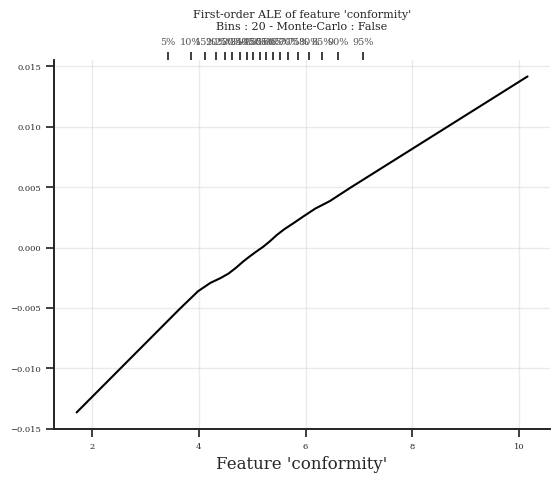

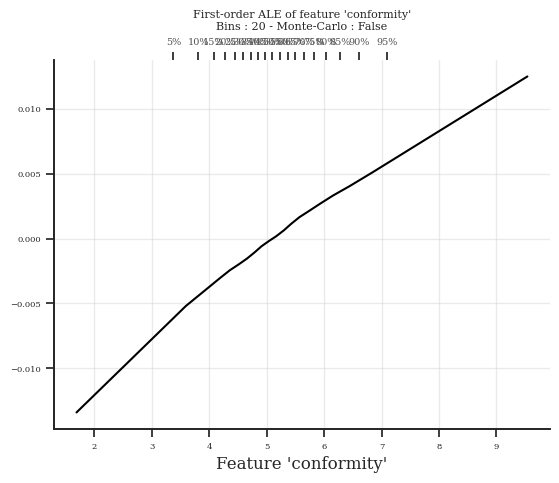

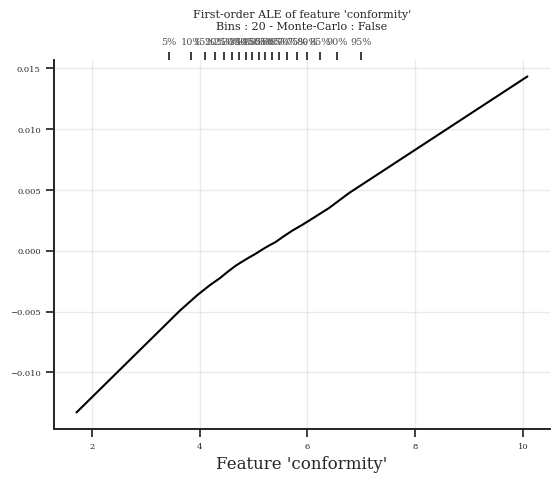

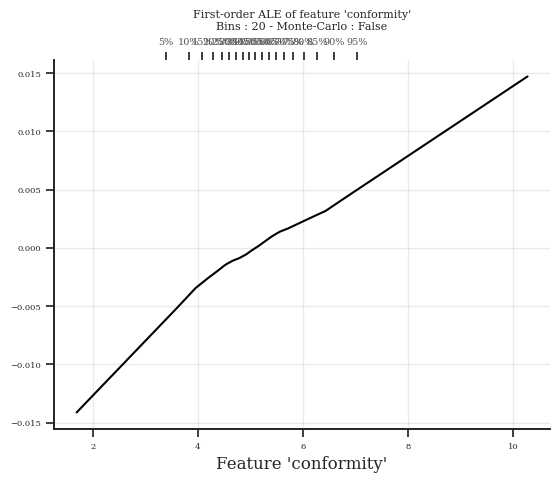

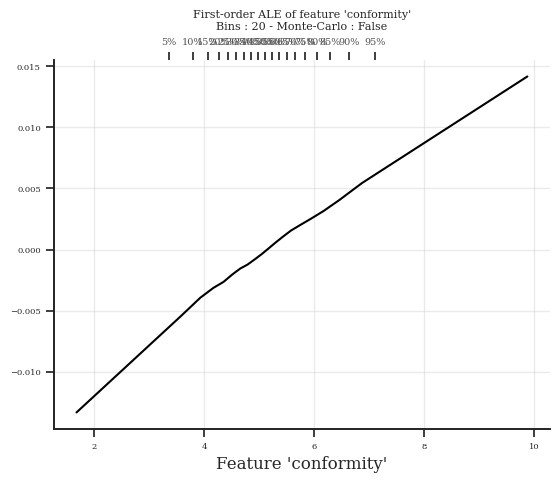

...

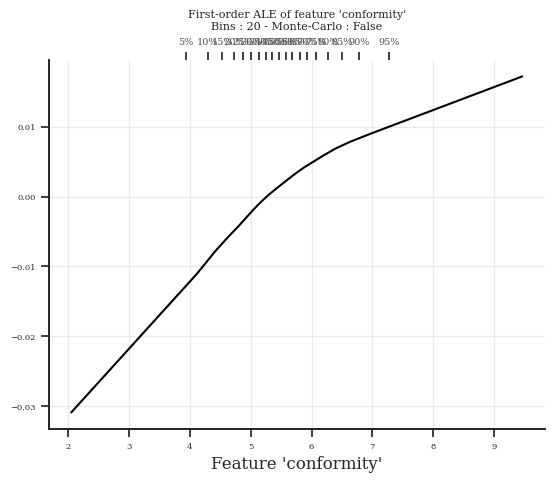

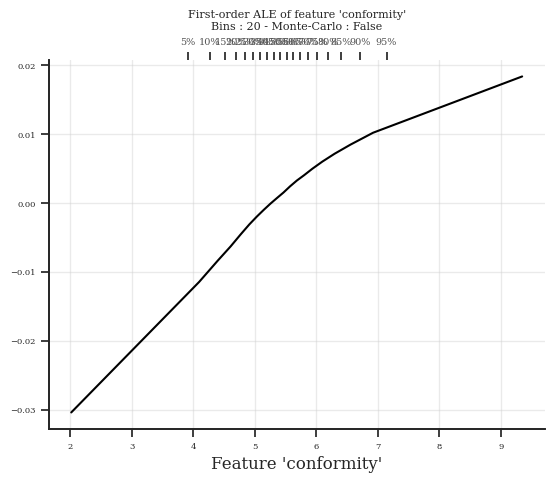

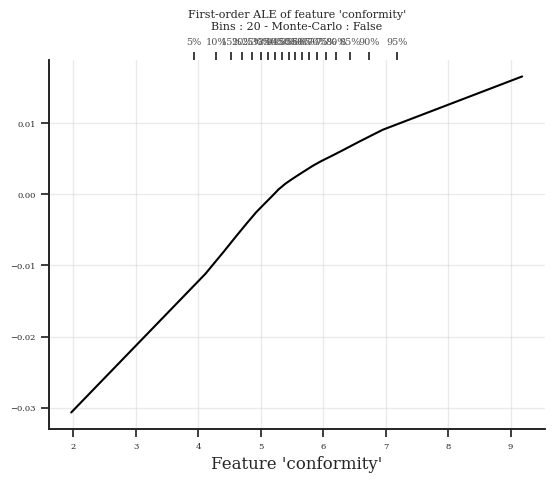

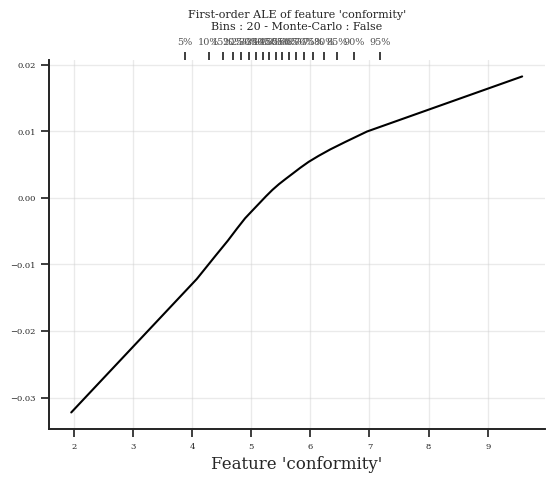

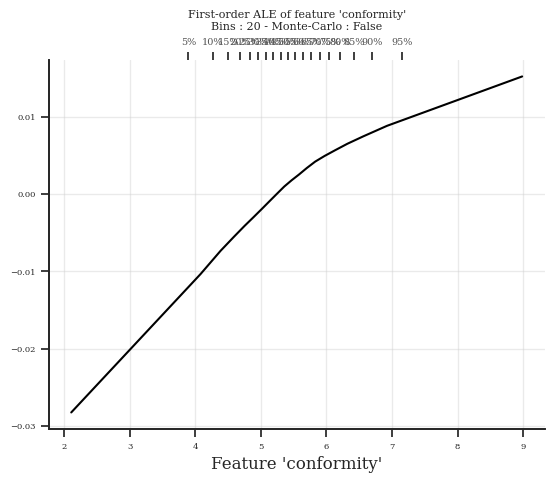

In [12]:
# 计算全局ale，转化成xarray的格式
bins = 20
quantiles = np.unique(
   np.quantile(
       dataset['treatments'].reshape(-1), np.linspace(0, 1, bins + 1), interpolation="linear"
   )
)

bins = (quantiles[1:] + quantiles[:-1]) / 2

data_vars = {}
n_bootstrap = 30


for i in [0,1,2]:
    dataset_year = [dataset19, dataset20, dataset23][i]
    year = [2019, 2020, 2023][i]
    ale = []
    
    for _ in range(n_bootstrap):
        sub_dataset = dataset_sampling(dataset_year, 1000)
        ale_fig, ale_1st, _ = compute_ale(sub_dataset, 'rmsn_'+str(exp_name), b_use_predicted_confounders=False, features = ['conformity'], default_quantiles=quantiles)
        ale.append(ale_1st)
    data_vars[f"conformity__RNN_Model_{year}__ale"] = (["n_bootstrap", f"n_bins__conformity"], ale)

data_vars[f"conformity__bin_values"] = (["n_bins__conformity"], bins)

data_vars[f"conformity"] = (["n_X"],dataset['treatments'][:,:,0].flatten())
    
ale_dataset = xr.Dataset(
    data_vars=data_vars,
    #coords={
    #    "n_bootstrap": np.arange(ale.shape[0]), 
    #    f"n_bins__{feature_name}": np.arange(quantiles.shape[0]),  
    #    "n_X": np.arange(flattened_values.shape[0]),  
    #},
    attrs={
        "estimator_output": "raw",
        "estimators used": ['RNN_Model_2019', 'RNN_Model_2020', 'RNN_Model_2023'],
        "method": "ale",
        "dimension": "1D",
        "features used": "conformity",
    }
)


In [13]:
# 还原SCI的log值
conformity_bin_values_log = ale_dataset['conformity__bin_values'].values
conformity_bin_values_original = np.exp(conformity_bin_values_log)-1
ale_dataset['conformity__bin_values'] = (('n_bins__conformity'), conformity_bin_values_original)

conformity_log = ale_dataset['conformity'].values
conformity_original = np.exp(conformity_log)-1
ale_dataset['conformity'] = (('n_X'), conformity_original)

# 将ALE值转换为倍数
ale_values = ale_dataset['conformity__RNN_Model_2019__ale'].values
ale_values_original = np.exp(ale_values)
ale_dataset['conformity__RNN_Model_2019__ale'] = ([('n_bootstrap'),('n_bins__conformity')], ale_values_original)

ale_values = ale_dataset['conformity__RNN_Model_2020__ale'].values
ale_values_original = np.exp(ale_values)
ale_dataset['conformity__RNN_Model_2020__ale'] = ([('n_bootstrap'),('n_bins__conformity')], ale_values_original)

ale_values = ale_dataset['conformity__RNN_Model_2023__ale'].values
ale_values_original = np.exp(ale_values)
ale_dataset['conformity__RNN_Model_2023__ale'] = ([('n_bootstrap'),('n_bins__conformity')], ale_values_original)

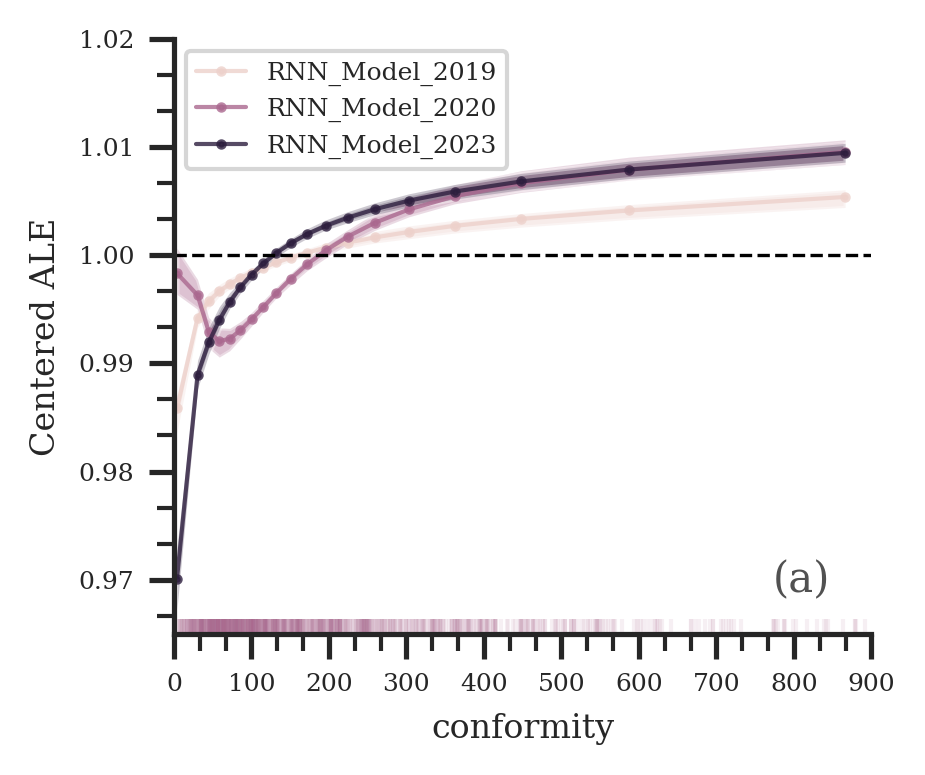

In [14]:
bins_to_keep = ale_dataset['n_bins__conformity'] != ale_dataset['n_bins__conformity'].loc[-1]
ale_dataset_select = ale_dataset.sel(n_bins__conformity=bins_to_keep)

estimator = [('RNN_Model_2019',RandomForestRegressor()),
            ('RNN_Model_2020',RandomForestRegressor()),
            ('RNN_Model_2023',RandomForestRegressor())]

explainer = skexplain.ExplainToolkit(estimator)

# 生成 cubehelix 调色盘
cubehelix_palette = sns.cubehelix_palette(n_colors=3)


fig, ax = explainer.plot_ale(
                                   ale = ale_dataset_select,
                                   features='conformity',
                                   display_units=plotting_config.display_units,
                                   display_feature_names=plotting_config.display_feature_names,
                                   line_kws={'marker': 'o', 'markersize':1.5,'linewidth':1, 'line_colors': cubehelix_palette},
hist_color = 'white', 
    edge_color= 'white'

                                  )

# ax.set_xscale('log')
ax.set_xlim(left = 0, right = 900)
# ax.set_xlim(left=1, right = 10 ** 5)
# ax.set_xlim(left=1, right = 11)
ax.set_ylim(bottom = 0.965, top = 1.02)

ax.axhline(y=1, color='black', ls='--', lw=0.8)

# ax.tick_params(axis='y', right=False, labelright=False)
# ax.tick_params(axis='y', tick1On=False, tick2On=False)
# ax.spines['bottom'].set_visible(False)
# ax.set_xticks(conformity_bin_values_original)
# ax.set_xticklabels([f'{val:.2f}' for val in conformity_bin_values_original])
ax.set_ylabel('Centered ALE', fontsize = 8)
ax.legend()

fig.axes[3].remove()
fig.axes[2].remove()
fig.axes[1].remove()



data = ale_dataset['conformity'].values
if len(data) > 1000:
    data_sample = np.random.choice(data, size=1000, replace=False)
else:
    data_sample = data
sns.rugplot(data_sample, ax=ax, color=cubehelix_palette[-2], alpha=0.1)

plt.show()

### some functions

In [4]:
# # 选取一定样本，对个体计算ale
# def select_indiviudal_from_dataset(dataset, index, overall=32000):
#     indiv_indices = [index, overall+index, overall*2 + index]
#     indiv_dataset = {key: value[indiv_indices] for key, value in dataset.items()}
#     return indiv_dataset

data selection

In [3]:
def _dataset_length(dataset):
    # 用任一字段的第一维推断样本总数 N
    return min(arr.shape[0] for arr in dataset.values())

def _infer_block_len(dataset, overall=None):
    """
    兼容旧逻辑：
    - 如提供 overall（例如 32000），严格按它作为分块长度，并检查是否越界；
    - 否则用真实长度 N // 3 自动推断 block（保证不越界）。
    """
    N = _dataset_length(dataset)
    if overall is not None:
        if 3 * overall > N:
            raise ValueError(
                f"overall={overall} 需要的最小样本数为 {3*overall}，"
                f"但当前数据只有 {N}。请减小 overall 或更换数据。"
            )
        return overall
    # 自动推断：尽量复现“等长三段”的意图
    block = N // 3
    if block == 0:
        raise ValueError(f"数据太短（N={N}），无法分成三段。")
    return block

def build_individual_dataset_fixed_offsets(dataset, n_bootstrap=1000, overall=None):
    """
    保持原始结果不变的安全实现：
    第 i 次抽样返回 [i, i+block, i+2*block]，其中 block 来自 overall 或 N//3。

    返回：
      indiv_dataset: 与原字段同名的新数据集，第一维长度为 n_bootstrap*3
      chosen_idx: 形状 (n_bootstrap, 3) 的索引记录
    """
    # 1) 确定 block，检查边界
    block = _infer_block_len(dataset, overall=overall)
    if n_bootstrap > block:
        raise ValueError(
            f"n_bootstrap={n_bootstrap} 不能大于分块长度 block={block}，"
            f"否则 i+2*block 会越界。请减小 n_bootstrap 或增大数据量/overall。"
        )

    # 2) 生成与旧代码完全一致的索引序列
    idx0 = np.arange(n_bootstrap, dtype=np.int64)
    chosen_idx = np.stack([idx0, idx0 + block, idx0 + 2 * block], axis=1)
    flat_idx = chosen_idx.reshape(-1)  # 展平成一维，便于一次性索引

    # 3) 一次性切片到新数组（保持 dtype 与形状一致）
    indiv_dataset = {}
    for key, arr in dataset.items():
        # arr 的形状如 (N, 161, 23)/(N, 161, 1)/(N,) 等
        sliced = arr[flat_idx]
        indiv_dataset[key] = sliced  # 直接返回切片结果，更快更干净

    return indiv_dataset, chosen_idx


In [4]:
def construct_relevant_dataframe(dataset, model_name, b_use_predicted_confounders,):
    model_name = model_name + '_use_confounders_' + str(b_use_predicted_confounders)
    model_root = os.path.join('results', model_name)
    config = {'covariate_cols':['gender','age','income','weekday_0','weekday_1','weekday_2','weekday_3','weekday_4', 'weekday_5', 'weekday_6',
           'voluntary','festivals','year_0','year_1','year_2','edu','married','dist_yes','density',
                           'temperature','percipit','E1','E2'],
            'treatment_cols':['conformity'],
             }
    
    # shape of data
    num_samples, length, num_covariates = dataset['covariates'].shape
    _, _, num_treatments = dataset['treatments'].shape
    num_years = 3
    FE_predict = Feature_Engineering(dataset, for_factor_model = False)
    X = FE_predict.construct_dataframe(config)
    dataset['output_means'] = FE_predict.scale_params['outcomes'][:, 0]
    dataset['output_stds'] = FE_predict.scale_params['outcomes'][:, 1]
    # add timeline and week column
    X['timeline'] = np.tile(np.arange(length), num_samples)
    start_date = pd.Timestamp('2019-12-21')
    X['date'] = X['timeline'].apply(lambda x: start_date + pd.Timedelta(days=x))
    X['week'] = ((X['date'] - start_date).dt.days / 7).astype(int)
    X['pid'] = np.repeat(np.arange(int(num_samples/3)), length*3)
    
    # ############################################################################################
    def ale_use_predict(X, dataset, config, model_root, FE_predict, b_use_predicted_confounders):
        # change data
        mod_dataset = dataset.copy()
        # 将修改完的值添加到mod_dataset
        covariate_shapes = dataset['covariates'].shape
        mod_dataset['covariates'] = X[config['covariate_cols']].values.reshape(covariate_shapes[0],covariate_shapes[1],covariate_shapes[2])
        treatment_shapes = dataset['treatments'].shape
        mod_dataset['treatments'] = X[config['treatment_cols']].values.reshape(treatment_shapes[0],treatment_shapes[1],treatment_shapes[2])

        # 使用原来的参数做标准化
        mod_dataset = FE_predict.get_dataset_normalize(mod_dataset, num_covariates, num_treatments)
        # 调用函数预测
        predictions, _ = \
        rnn_predict(dataset=mod_dataset, MODEL_ROOT=model_root,
                    b_use_predicted_confounders=b_use_predicted_confounders)
        outputs = predictions.reshape(-1)
        del mod_dataset; gc.collect()
        return outputs
    # ############################################################################################
    # define predictor
    predictor = lambda x: ale_use_predict(x, dataset, config, model_root, FE_predict, b_use_predicted_confounders)
    
    return X, predictor

In [5]:
def compute_ice(predictor, train_set, feature, bins, default_quantiles=None):
    
    if default_quantiles is None:
        quantiles, real_bins = _get_quantiles(train_set, feature, bins)
    else:
        quantiles, real_bins = default_quantiles, len(default_quantiles) - 1
    # adjust week to match index
    #adjusted_weeks_list = [week - 1 for week in sorted(train_set['week'].unique())]

    num_quantiles = len(quantiles)
    num_samples = len(train_set)
    predictions = np.zeros((num_quantiles, num_samples))

    # 对每个个体的数据都换成bins去预测（类似pdp的做法）
    for i in range(num_quantiles):
        # 复制整个训练集
        mod_train_set = train_set.copy()
        # 只更新当前 week 的特定特征值
        mod_train_set[feature] = quantiles[i]
        # 对整个训练集进行预测并记录
        predictions[i] = predictor(mod_train_set)

        del mod_train_set; gc.collect()

    effects = np.diff(predictions, axis=0)

    # 获取每个样本的分位数位置
    indices = np.zeros((num_samples, num_quantiles - 1))

    for i in range(num_samples):
        indices[i] = (np.arange(num_quantiles - 1)).astype("int")

    indiv_groups = pd.DataFrame(
        {"pid": train_set["pid"].values.repeat(num_quantiles - 1),  
         "index": indices.flatten(), 
         "effects": effects.flatten()}
    )
    
    ale_list = []
    for _, group in indiv_groups.groupby("pid"):
        mean_effects = group.groupby("index")["effects"].mean().to_numpy().flatten()
        ale = np.array([0, *np.cumsum(mean_effects)])
        ale = _get_centres(ale)
        ale -= np.mean(ale)
        ale_list.append(ale)
        
    return np.array(ale_list)

In [6]:
def create_ice_dataset(ice_dict, quantiles, model_names, feature_name):
  
    # quantiles取平均
    quantiles = (quantiles[:-1] + quantiles[1:]) / 2

    # 创建data_vars字典
    data_vars = {}
    for model_name in model_names:
        ice = ice_dict[model_name]
        # 如果 ale 是一维数组，则添加一个维度
        if ice.ndim == 1:
            ice = ice[np.newaxis, :]
        
        data_vars[f"{feature_name}__{model_name}__ice"] = (["n_bootstrap", f"n_bins__{feature_name}"], ice)

    data_vars[f"{feature_name}__bin_values"] = ([f"n_bins__{feature_name}"], quantiles)

    # 创建 xarray.Dataset
    dataset = xr.Dataset(
        data_vars=data_vars,
        attrs={
            "estimator_output": "raw",
            "estimators used": model_names,
            "method": "ale",
            "dimension": "1D",
            "features used": [feature_name],
        }
    )
    
    # === 新增部分：提取 first_values 并添加到 X_sampled 和 features 中 ===
    # 提取 'conformity__RNN_Model__ice' 中每条 ICE 曲线的第一个值
    first_values = dataset[f"{feature_name}__{model_name}__ice"].values[:, 0]

    # 将 first_values 转换为 X_sampled 格式
    X_sampled = np.expand_dims(first_values, axis=1)  # 将一维数组转换为二维数组

    # 将 X_sampled 和 features 添加到数据集
    dataset = dataset.assign(X_sampled=(['n_bootstrap', 'feature'], X_sampled))
    dataset = dataset.assign(features=(['feature'], ['first_values']))

    return dataset

### 0. data load

In [7]:
dataset = load_data("../data/sample_32w_add.h5")
# dataset = load_data("../data/sample_32w.h5")

index_to_remove = dataset['covariates'].shape[2] - 5
dataset['covariates'] = np.delete(dataset['covariates'], index_to_remove, axis=2)

index_to_remove = dataset['covariates'].shape[2] - 5
dataset['covariates'] = np.delete(dataset['covariates'], index_to_remove, axis=2)

for key in dataset.keys():
    print(key)
    print(dataset[key].shape)
    print(dataset[key].dtype)

covariates
(981651, 161, 23)
float32
outcomes
(981651, 161, 1)
float32
sequence_length
(981651,)
int64
treatments
(981651, 161, 1)
float32


### 1. calculate ICE

In [8]:
bins = 20
quantiles = np.unique(
   np.quantile(
       dataset['treatments'].reshape(-1), np.linspace(0, 1, bins + 1), interpolation="lower"
   )
)

the `interpolation=` argument to quantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)


In [9]:
column_2019 = 12  # index of year 2019 indicator
column_2023 = 14  # index of year 2023 indicator
dataset19 = obtain_dataset(dataset, column_2019)
dataset19_sample = dataset_sampling(dataset19, num_select=300000)

dataset23 = obtain_dataset(dataset, column_2023)
dataset23_sample = dataset_sampling(dataset23, num_select=300000)

del dataset; gc.collect()

0

In [10]:
exp_name = "base_model_optimal_v2"

2025-10-11 00:39:52.154 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3941836  3.8174138  4.0797157  4.278361   4.443224
  4.5828424  4.717648   4.845433   4.967092   5.0917187  5.217296
  5.3469024  5.4894056  5.6443586  5.8213363  6.034701   6.2912364
  6.597307   7.0613527 13.234694 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 0it [00:00, ?it/s]2025-10-11 00:39:53.564959: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:432] Loaded cuDNN version 8600
Predicting rnn_propensity_weighted: 16it [00:01, 13.90it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.55it/s]
2025-10-11 00:39:56.918 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3941836  3.8174138  4.0797157  4.278361   4.443224
  4.5828424  4.717648   4.845433   4.967092   5.0917187  5.217296
  5.3469024  5.4894056  5.6443586  5.8213363  6.034701   6.2912364
  6.597307   7.0613527 13.234694 ].


[ 1.6970918  3.6057987  3.9485648  4.179038   4.360792   4.513033
  4.650245   4.781541   4.9062624  5.0294056  5.1545076  5.2820992
  5.418154   5.566882   5.732847   5.9280186  6.1629686  6.444272
  6.82933   10.148024 ]


2025-10-11 00:39:58.278 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.4398     3.868255   4.135782   4.33453    4.4982038
  4.648156   4.779803   4.904625   5.0268884  5.145312   5.265152
  5.3913884  5.5281057  5.6804304  5.8534665  6.0530424  6.31655
  6.6214056  7.105135  13.165884 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.32it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.77it/s]
2025-10-11 00:40:02.740 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.4398     3.868255   4.135782   4.33453    4.4982038
  4.648156   4.779803   4.904625   5.0268884  5.145312   5.265152
  5.3913884  5.5281057  5.6804304  5.8534665  6.0530424  6.31655
  6.6214056  7.105135  13.165884 ].


[ 1.7199     3.6540275  4.0020185  4.235156   4.4163666  4.57318
  4.7139797  4.8422136  4.9657564  5.0861     5.2052317  5.32827
  5.4597473  5.604268   5.7669487  5.9532547  6.1847963  6.468978
  6.8632703 10.1355095]


2025-10-11 00:40:04.170 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3517427  3.796639   4.071618   4.280729   4.4515266
  4.599379   4.7330837  4.864232   4.997895   5.1270895  5.254606
  5.388969   5.522639   5.6740875  5.843898   6.0423284  6.284685
  6.5815563  7.050304  12.654121 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.01it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.37it/s]
2025-10-11 00:40:08.620 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3517427  3.796639   4.071618   4.280729   4.4515266
  4.599379   4.7330837  4.864232   4.997895   5.1270895  5.254606
  5.388969   5.522639   5.6740875  5.843898   6.0423284  6.284685
  6.5815563  7.050304  12.654121 ].


[1.6758714 3.5741909 3.9341285 4.176173  4.366128  4.5254526 4.666231
 4.798658  4.9310637 5.0624924 5.1908474 5.3217874 5.455804  5.598363
 5.7589927 5.9431133 6.1635065 6.4331207 6.8159304 9.852213 ]


2025-10-11 00:40:10.105 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.352272   3.807015   4.088069   4.2954707  4.466579
  4.6126423  4.7494698  4.87764    4.999662   5.122448   5.241929
  5.365813   5.503347   5.650468   5.823354   6.0264726  6.2849293
  6.595482   7.065183  12.654121 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.44it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.71it/s]
2025-10-11 00:40:14.384 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.352272   3.807015   4.088069   4.2954707  4.466579
  4.6126423  4.7494698  4.87764    4.999662   5.122448   5.241929
  5.365813   5.503347   5.650468   5.823354   6.0264726  6.2849293
  6.595482   7.065183  12.654121 ].


[1.676136  3.5796435 3.947542  4.1917696 4.381025  4.539611  4.681056
 4.813555  4.938651  5.061055  5.1821885 5.303871  5.43458   5.576907
 5.736911  5.9249134 6.1557007 6.4402056 6.8303328 9.8596525]


2025-10-11 00:40:15.673 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3505635  3.780309   4.051047   4.2604055  4.4284024
  4.5741997  4.7106085  4.8380427  4.965812   5.0908937  5.213033
  5.346306   5.4873395  5.6373925  5.813101   6.026994   6.2789073
  6.600537   7.0784607 13.563467 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.84it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.10it/s]
2025-10-11 00:40:19.921 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3505635  3.780309   4.051047   4.2604055  4.4284024
  4.5741997  4.7106085  4.8380427  4.965812   5.0908937  5.213033
  5.346306   5.4873395  5.6373925  5.813101   6.026994   6.2789073
  6.600537   7.0784607 13.563467 ].


[ 1.6752818  3.5654364  3.915678   4.1557264  4.344404   4.501301
  4.642404   4.7743254  4.9019275  5.0283527  5.151963   5.27967
  5.4168224  5.562366   5.7252464  5.9200478  6.152951   6.439722
  6.8394985 10.320964 ]


2025-10-11 00:40:21.254 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3471065  3.790662   4.0624385  4.268106   4.436456
  4.581915   4.7146764  4.840624   4.962575   5.081404   5.2067237
  5.3380632  5.4735556  5.616771   5.7845597  5.9918575  6.2494373
  6.5808277  7.1070404 12.499269 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.23it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.25it/s]
2025-10-11 00:40:25.584 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3471065  3.790662   4.0624385  4.268106   4.436456
  4.581915   4.7146764  4.840624   4.962575   5.081404   5.2067237
  5.3380632  5.4735556  5.616771   5.7845597  5.9918575  6.2494373
  6.5808277  7.1070404 12.499269 ].


[1.6735532 3.5688844 3.9265504 4.165272  4.352281  4.509186  4.6482954
 4.77765   4.9015994 5.02199   5.144064  5.272393  5.4058094 5.545163
 5.7006655 5.8882084 6.1206474 6.4151325 6.843934  9.803154 ]


2025-10-11 00:40:26.978 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3305717  3.7975628  4.073021   4.2730017  4.4353876
  4.579338   4.708903   4.8346934  4.9526386  5.0790963  5.20048
  5.3279114  5.4618387  5.6158614  5.791611   6.002814   6.261423
  6.609229   7.141264  13.567358 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.84it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.56it/s]
2025-10-11 00:40:31.206 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3305717  3.7975628  4.073021   4.2730017  4.4353876
  4.579338   4.708903   4.8346934  4.9526386  5.0790963  5.20048
  5.3279114  5.4618387  5.6158614  5.791611   6.002814   6.261423
  6.609229   7.141264  13.567358 ].


[ 1.6652858  3.5640674  3.9352918  4.1730113  4.3541946  4.507363
  4.64412    4.771798   4.8936663  5.015867   5.139788   5.2641954
  5.394875   5.53885    5.7037363  5.8972125  6.132118   6.435326
  6.8752465 10.354311 ]


2025-10-11 00:40:32.517 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3922372  3.8453279  4.1182976  4.316648   4.4864745
  4.6291876  4.761712   4.883571   5.002684   5.121005   5.2392783
  5.3665404  5.5095205  5.6673427  5.8317857  6.0258183  6.262411
  6.583074   7.0744677 13.226238 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.63it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.55it/s]
2025-10-11 00:40:36.792 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3922372  3.8453279  4.1182976  4.316648   4.4864745
  4.6291876  4.761712   4.883571   5.002684   5.121005   5.2392783
  5.3665404  5.5095205  5.6673427  5.8317857  6.0258183  6.262411
  6.583074   7.0744677 13.226238 ].


[ 1.6961186  3.6187825  3.9818127  4.217473   4.4015613  4.557831
  4.69545    4.8226414  4.9431276  5.061845   5.1801414  5.3029094
  5.4380302  5.5884314  5.749564   5.928802   6.1441145  6.422743
  6.8287706 10.1503525]


2025-10-11 00:40:38.077 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3416631  3.7944405  4.064626   4.270551   4.4447403
  4.594264   4.7287245  4.855929   4.981574   5.1054454  5.2340736
  5.3623996  5.5078387  5.6675735  5.845605   6.044819   6.2852244
  6.610424   7.107606  12.906198 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.65it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 15.75it/s]
2025-10-11 00:40:42.478 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3416631  3.7944405  4.064626   4.270551   4.4447403
  4.594264   4.7287245  4.855929   4.981574   5.1054454  5.2340736
  5.3623996  5.5078387  5.6675735  5.845605   6.044819   6.2852244
  6.610424   7.107606  12.906198 ].


[ 1.6708316  3.5680518  3.9295335  4.1675887  4.357646   4.519502
  4.6614943  4.792327   4.9187517  5.0435095  5.1697598  5.298237
  5.435119   5.587706   5.756589   5.945212   6.165022   6.4478245
  6.859015  10.006902 ]


2025-10-11 00:40:43.791 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.         3.3876905  3.8257558  4.09671    4.2900333  4.4571
  4.608677   4.747256   4.8761234  4.9993715  5.1209693  5.247425
  5.3798976  5.52061    5.673672   5.8356237  6.042633   6.293254
  6.6124887  7.09091   13.979414 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.19it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.62it/s]
2025-10-11 00:40:48.124 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.         3.3876905  3.8257558  4.09671    4.2900333  4.4571
  4.608677   4.747256   4.8761234  4.9993715  5.1209693  5.247425
  5.3798976  5.52061    5.673672   5.8356237  6.042633   6.293254
  6.6124887  7.09091   13.979414 ].


[ 1.6938453  3.6067233  3.9612331  4.193372   4.3735666  4.5328884
  4.677966   4.8116894  4.9377475  5.06017    5.1841974  5.3136616
  5.4502535  5.5971413  5.754648   5.9391284  6.1679435  6.4528713
  6.8516994 10.535162 ]


2025-10-11 00:40:49.482 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.09726883  3.9832156   4.325552    4.542646    4.708401    4.8534837
  4.9795403   5.1022      5.216138    5.3302784   5.441981    5.545267
  5.6532626   5.770449    5.895992    6.035079    6.2052      6.4242573
  6.7139397   7.1657667  11.768505  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.07it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.85it/s]
2025-10-11 00:40:53.963 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.09726883  3.9832156   4.325552    4.542646    4.708401    4.8534837
  4.9795403   5.1022      5.216138    5.3302784   5.441981    5.545267
  5.6532626   5.770449    5.895992    6.035079    6.2052      6.4242573
  6.7139397   7.1657667  11.768505  ].


[2.0402422 4.1543837 4.434099  4.6255236 4.7809424 4.916512  5.04087
 5.159169  5.273208  5.3861294 5.4936237 5.599265  5.711856  5.8332205
 5.965535  6.1201396 6.3147287 6.5690985 6.939853  9.467136 ]


2025-10-11 00:40:55.256 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.34776282  3.9631996   4.3473697   4.5771556   4.7556605   4.8968425
  5.0188265   5.1348405   5.241802    5.3480844   5.4590673   5.5709105
  5.6900625   5.812534    5.9543815   6.1123505   6.2953277   6.513462
  6.7968235   7.241069   11.25365   ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.75it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.17it/s]
2025-10-11 00:40:59.547 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.34776282  3.9631996   4.3473697   4.5771556   4.7556605   4.8968425
  5.0188265   5.1348405   5.241802    5.3480844   5.4590673   5.5709105
  5.6900625   5.812534    5.9543815   6.1123505   6.2953277   6.513462
  6.7968235   7.241069   11.25365   ].


[2.1554813 4.155285  4.4622626 4.666408  4.8262515 4.9578342 5.0768337
 5.188321  5.2949433 5.403576  5.514989  5.6304865 5.751298  5.8834577
 6.033366  6.2038393 6.404395  6.655143  7.018946  9.247359 ]


2025-10-11 00:41:00.882 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.7102416  3.880518   4.257141   4.496804   4.6764073  4.825705
  4.9530373  5.069793   5.1823835  5.294843   5.4028535  5.5114985
  5.6267457  5.7446275  5.872902   6.0168276  6.190759   6.4161305
  6.709057   7.1301436 11.226456 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.06it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.57it/s]
2025-10-11 00:41:05.339 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.7102416  3.880518   4.257141   4.496804   4.6764073  4.825705
  4.9530373  5.069793   5.1823835  5.294843   5.4028535  5.5114985
  5.6267457  5.7446275  5.872902   6.0168276  6.190759   6.4161305
  6.709057   7.1301436 11.226456 ].


[2.2953799 4.0688295 4.3769727 4.586606  4.751056  4.889371  5.0114155
 5.126088  5.238613  5.3488483 5.457176  5.5691223 5.6856866 5.8087645
 5.9448647 6.103793  6.303445  6.5625935 6.9196005 9.1783   ]


2025-10-11 00:41:06.661 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.19593695  3.8913054   4.271635    4.4946613   4.6688066   4.8140836
  4.9426327   5.0665402   5.18249     5.2963176   5.404191    5.514525
  5.626947    5.7463417   5.8727818   6.0078897   6.176215    6.4170747
  6.711357    7.1790223  10.997606  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.63it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.66it/s]
2025-10-11 00:41:10.987 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.19593695  3.8913054   4.271635    4.4946613   4.6688066   4.8140836
  4.9426327   5.0665402   5.18249     5.2963176   5.404191    5.514525
  5.626947    5.7463417   5.8727818   6.0078897   6.176215    6.4170747
  6.711357    7.1790223  10.997606  ].


[2.0436213 4.0814705 4.383148  4.5817337 4.741445  4.878358  5.004586
 5.124515  5.2394037 5.350254  5.459358  5.570736  5.6866446 5.8095617
 5.9403358 6.0920525 6.296645  6.5642157 6.9451895 9.088314 ]


2025-10-11 00:41:12.360 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.05809959  3.9316716   4.308708    4.534986    4.704929    4.8497853
  4.973684    5.0904455   5.20102     5.30521     5.4127736   5.5256968
  5.6407413   5.761616    5.892341    6.046286    6.2234845   6.446549
  6.761971    7.2218485  11.471176  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.94it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.89it/s]
2025-10-11 00:41:16.721 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.05809959  3.9316716   4.308708    4.534986    4.704929    4.8497853
  4.973684    5.0904455   5.20102     5.30521     5.4127736   5.5256968
  5.6407413   5.761616    5.892341    6.046286    6.2234845   6.446549
  6.761971    7.2218485  11.471176  ].


[1.9948856 4.1201897 4.4218473 4.6199574 4.777357  4.9117346 5.0320644
 5.145733  5.2531147 5.3589916 5.4692354 5.583219  5.7011786 5.8269787
 5.9693136 6.1348853 6.3350167 6.60426   6.99191   9.346512 ]


2025-10-11 00:41:18.053 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.10939856  3.8655667   4.2495036   4.4840727   4.6626506   4.805162
  4.930665    5.0440116   5.153535    5.263401    5.3729753   5.485943
  5.603174    5.7241325   5.845899    5.988373    6.1575384   6.405963
  6.7194934   7.1851587  12.345361  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.61it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.66it/s]
2025-10-11 00:41:22.393 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.10939856  3.8655667   4.2495036   4.4840727   4.6626506   4.805162
  4.930665    5.0440116   5.153535    5.263401    5.3729753   5.485943
  5.603174    5.7241325   5.845899    5.988373    6.1575384   6.405963
  6.7194934   7.1851587  12.345361  ].


[1.9874827 4.057535  4.366788  4.5733614 4.7339063 4.8679132 4.987338
 5.098773  5.208468  5.318188  5.429459  5.5445585 5.6636534 5.785016
 5.917136  6.0729556 6.2817507 6.562728  6.952326  9.76526  ]


2025-10-11 00:41:23.703 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.06166336  3.9261742   4.295031    4.528074    4.70115     4.8412404
  4.9681096   5.0865746   5.1999974   5.304391    5.4138083   5.5225053
  5.6341257   5.7510114   5.876301    6.0340486   6.2168303   6.429247
  6.732476    7.228788   11.57591   ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.29it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:01, 12.48it/s]
2025-10-11 00:41:28.380 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.06166336  3.9261742   4.295031    4.528074    4.70115     4.8412404
  4.9681096   5.0865746   5.1999974   5.304391    5.4138083   5.5225053
  5.6341257   5.7510114   5.876301    6.0340486   6.2168303   6.429247
  6.732476    7.228788   11.57591   ].


[1.9939188 4.1106024 4.4115524 4.6146116 4.7711954 4.904675  5.027342
 5.1432858 5.2521944 5.3590994 5.468157  5.5783157 5.692569  5.813656
 5.9551744 6.1254396 6.3230386 6.5808616 6.980632  9.4023485]


2025-10-11 00:41:29.749 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.70158607  3.9203472   4.3212667   4.5516605   4.7196198   4.859736
  4.989274    5.1107516   5.224722    5.332719    5.4366493   5.536808
  5.644515    5.7639275   5.8843      6.0237503   6.1975584   6.431595
  6.756918    7.1895027  11.780285  ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.78it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.75it/s]
2025-10-11 00:41:33.997 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.70158607  3.9203472   4.3212667   4.5516605   4.7196198   4.859736
  4.989274    5.1107516   5.224722    5.332719    5.4366493   5.536808
  5.644515    5.7639275   5.8843      6.0237503   6.1975584   6.431595
  6.756918    7.1895027  11.780285  ].


[2.3109667 4.1208067 4.4364634 4.63564   4.7896776 4.924505  5.0500126
 5.167737  5.2787204 5.384684  5.4867287 5.5906615 5.7042212 5.824114
 5.9540253 6.1106544 6.3145766 6.5942564 6.9732103 9.484894 ]


2025-10-11 00:41:35.387 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.6768867  3.9269912  4.299809   4.5203424  4.6888885  4.833777
  4.962048   5.078797   5.1906376  5.3025527  5.409661   5.5160193
  5.6220245  5.7378645  5.86119    6.008688   6.1824503  6.4029193
  6.6952634  7.170435  11.202193 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.76it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.37it/s]
2025-10-11 00:41:39.959 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.6768867  3.9269912  4.299809   4.5203424  4.6888885  4.833777
  4.962048   5.078797   5.1906376  5.3025527  5.409661   5.5160193
  5.6220245  5.7378645  5.86119    6.008688   6.1824503  6.4029193
  6.6952634  7.170435  11.202193 ].


[2.301939  4.1134    4.4100757 4.604615  4.7613325 4.8979125 5.0204225
 5.134717  5.2465954 5.3561068 5.46284   5.569022  5.6799445 5.799527
 5.934939  6.095569  6.2926846 6.5490913 6.932849  9.186314 ]


2025-10-11 00:41:41.442 | DEBUG    | ale:_first_order_ale_quant:394 - Quantiles: [ 0.6051662  3.9535131  4.3298965  4.566773   4.7402887  4.882996
  5.0116954  5.128977   5.2412667  5.3493724  5.451474   5.557142
  5.663494   5.772016   5.8973875  6.034944   6.206576   6.4266796
  6.702193   7.1630535 10.680134 ].


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 16.18it/s]


results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted.csv


INFO:Successfully loaded model from results/rmsn_base_model_optimal_v2_use_confounders_False/rnn_propensity_weighted/rnn_propensity_weighted_0.1_72_200_64_0.01_0.5_60_optimal
Predicting rnn_propensity_weighted: 16it [00:00, 17.09it/s]
2025-10-11 00:41:45.911 | DEBUG    | ale:_ax_quantiles:182 - Quantiles: [ 0.6051662  3.9535131  4.3298965  4.566773   4.7402887  4.882996
  5.0116954  5.128977   5.2412667  5.3493724  5.451474   5.557142
  5.663494   5.772016   5.8973875  6.034944   6.206576   6.4266796
  6.702193   7.1630535 10.680134 ].


[2.2793398 4.1417046 4.4483347 4.653531  4.8116426 4.9473457 5.0703363
 5.1851215 5.2953196 5.400423  5.5043077 5.610318  5.7177553 5.8347015
 5.9661655 6.12076   6.3166275 6.564436  6.932623  8.921594 ]


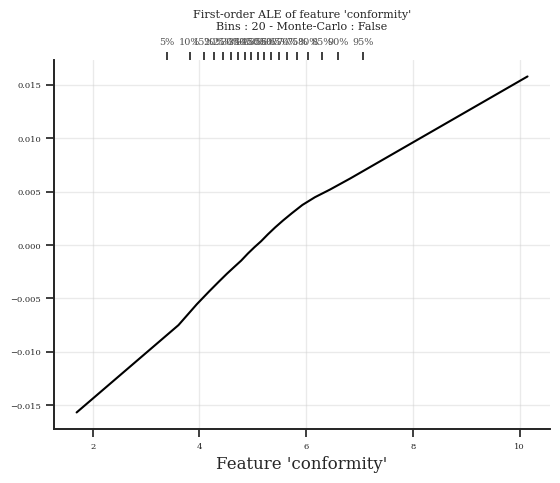

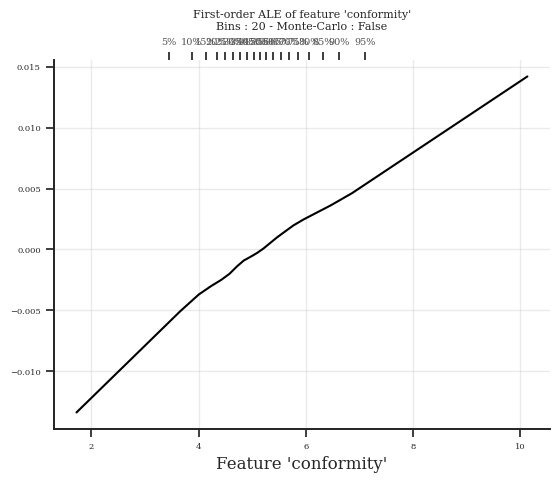

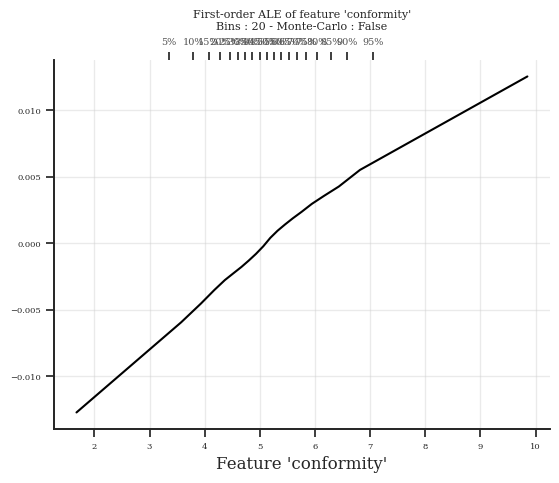

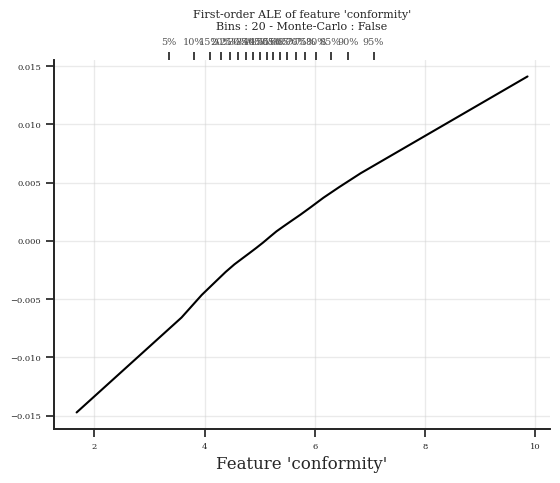

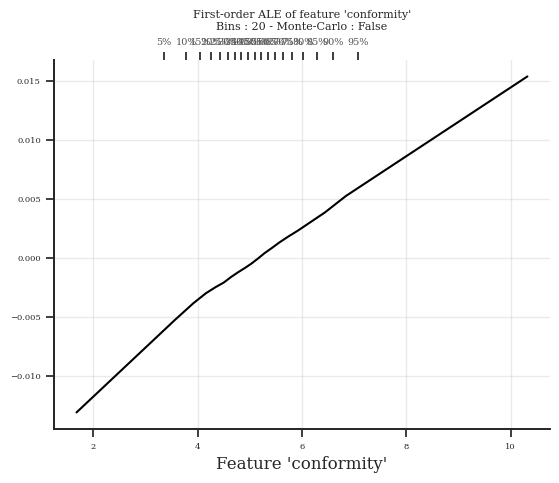

...

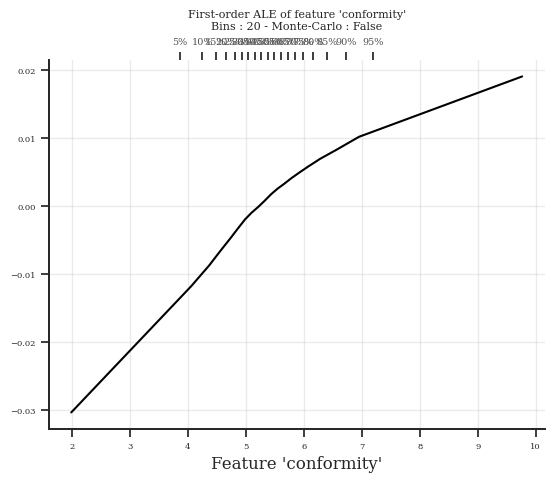

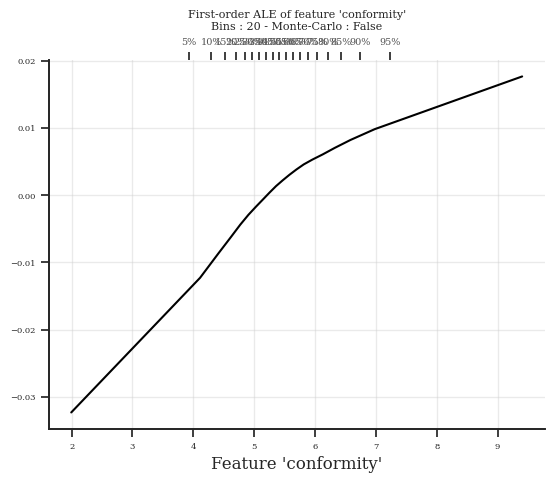

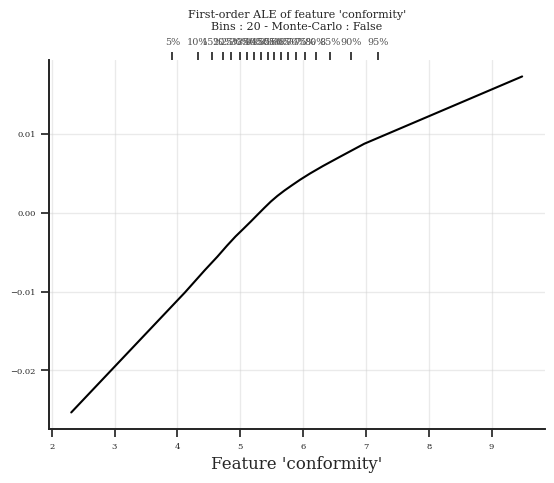

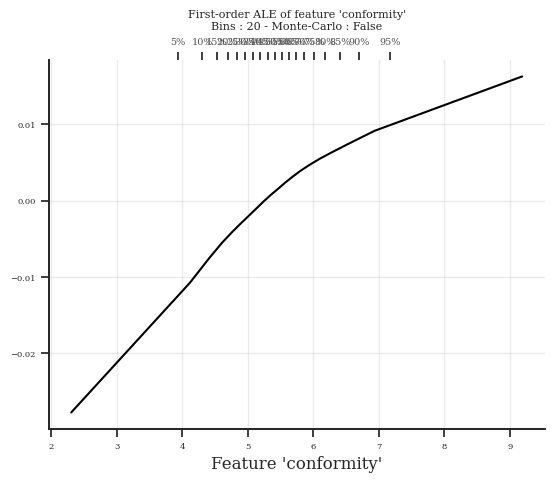

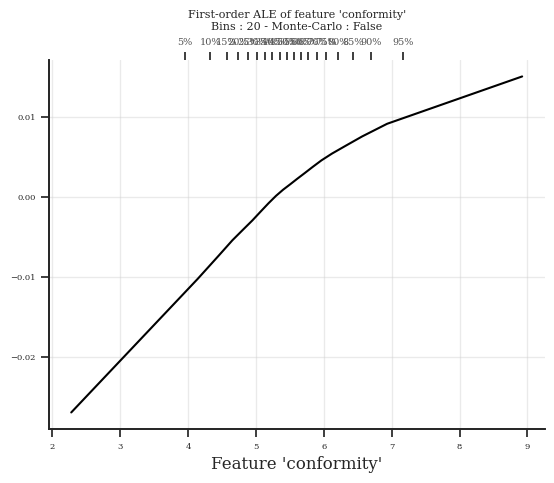

In [11]:
ALE_1ST_19 = {'RNN_Model': []}
ALE_1ST_23 = {'RNN_Model': []}
n_bootstrap = 10

for dataset, year in zip([dataset19, dataset23], ['19', '23']):
    for _ in range(n_bootstrap):
        sub_dataset = dataset_sampling(dataset, 1000)
        _, ale_1st, _ = compute_ale(sub_dataset, 'rmsn_' + str(exp_name), b_use_predicted_confounders=False, features=['conformity'], default_quantiles=quantiles)
        eval(f'ALE_1ST_{year}')['RNN_Model'].append(ale_1st)


ALE_1ST_19['RNN_Model'] = np.array(ALE_1ST_19['RNN_Model'])
ALE_1ST_23['RNN_Model'] = np.array(ALE_1ST_23['RNN_Model'])
ale_dataset_19 = create_ale_dataset(ALE_1ST_19, quantiles, dataset19['treatments'], ['RNN_Model'], 'conformity')
ale_dataset_23 = create_ale_dataset(ALE_1ST_23, quantiles, dataset23['treatments'], ['RNN_Model'], 'conformity')

In [ ]:
# 获取个体数据集
n_bootstrap = 100000
K = 3
ICE = {
    'ICE_19': [],
    'ICE_23': []
}
for dataset, ice_name in zip([dataset19, dataset23], ['ICE_19','ICE_23']):
    # 初始化新数据集
    indiv_dataset = {
        'covariates': np.zeros((n_bootstrap * 3, 161, 23), dtype='float32'),
        'outcomes': np.zeros((n_bootstrap * 3, 161, 1), dtype='float32'),
        'sequence_length': np.zeros((n_bootstrap * 3,), dtype='int64'),
        'treatments': np.zeros((n_bootstrap * 3, 161, 1), dtype='float32')
    }
    for index in range(n_bootstrap):
        indiv_dataset, chosen_idx = build_individual_dataset_fixed_offsets(
        dataset,
        n_bootstrap=n_bootstrap,   # 若不需要强行 32000，可用 overall=None 自动推断
    )
#         indiv_data = select_indiviudal_from_dataset(dataset, index)
#         start_idx = index * 3
#         end_idx = start_idx + 3

#         indiv_dataset['covariates'][start_idx:end_idx] = indiv_data['covariates']
#         indiv_dataset['outcomes'][start_idx:end_idx] = indiv_data['outcomes']
#         indiv_dataset['sequence_length'][start_idx:end_idx] = indiv_data['sequence_length']
#         indiv_dataset['treatments'][start_idx:end_idx] = indiv_data['treatments']
        
    indiv_dataframe, predictor = construct_relevant_dataframe(indiv_dataset,'rmsn_' + str(exp_name), b_use_predicted_confounders=False)

    ice = compute_ice(predictor, 
                      indiv_dataframe, 
                      ['conformity'], 
                      20, 
                      quantiles)
    ICE[ice_name] = ice

In [ ]:
ice_dataset_19 = create_ice_dataset({'RNN_Model':ICE['ICE_19']}, quantiles, ['RNN_Model'], 'conformity')
ice_dataset_23 = create_ice_dataset({'RNN_Model':ICE['ICE_23']}, quantiles, ['RNN_Model'], 'conformity')

In [ ]:
# save the sample ice data
ale_dataset_19.to_netcdf(path='figures/figure_data/fig_1d_ale19.nc')
ale_dataset_23.to_netcdf(path='figures/figure_data/fig_1d_ale23.nc')
ice_dataset_19.to_netcdf(path='figures/figure_data/fig_1d_ice19_10w.nc')
ice_dataset_23.to_netcdf(path='figures/figure_data/fig_1d_ice23_10w.nc')

### 2. plot ICE

In [4]:
ale_dataset_19 = xr.open_dataset('figures/figure_data/fig_1d_ale19.nc')
ale_dataset_23 = xr.open_dataset('figures/figure_data/fig_1d_ale23.nc')

ice_dataset_19 = xr.open_dataset('figures/figure_data/fig_1d_ice19_1w.nc')
ice_dataset_23 = xr.open_dataset('figures/figure_data/fig_1d_ice23_1w.nc')

In [5]:
replace_num = 100
feature = "conformity"
model_name = "RNN_Model"

# 1) 先检查 features 顺序一致
feat_23 = list(ice_dataset_23["features"].values)
feat_19 = list(ice_dataset_19["features"].values)
if feat_23 != feat_19:
    raise ValueError("features 顺序不一致，无法直接替换。请先对齐列顺序。")

# 2) 替换 ICE 曲线
da_name = f"{feature}__{model_name}__ice"
ice_23_vals = ice_dataset_23[da_name].values.copy()
ice_19_vals = ice_dataset_19[da_name].values
ice_23_vals[:replace_num, :] = ice_19_vals[:replace_num, :]
ice_dataset_23 = ice_dataset_23.assign(
    {da_name: (["n_bootstrap", f"n_bins__{feature}"], ice_23_vals)}
)

# 3) 同步替换 X_sampled（供 color_by 上色用）
X19 = ice_dataset_19["X_sampled"].values
ice_dataset_23 = ice_dataset_23.copy()  # 避免就地视图问题
ice_dataset_23["X_sampled"].loc[dict(n_bootstrap=slice(0, replace_num))] = X19[:replace_num, :]

In [6]:
ice_dataset_19.to_netcdf(path='figures/figure_data/fig_1d_ice19_1w_new.nc')
ice_dataset_23.to_netcdf(path='figures/figure_data/fig_1d_ice23_1w_new.nc')

测试一下自定义colorbar

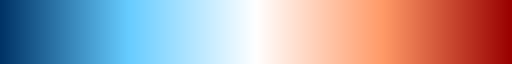

In [11]:
colors = ["#003366", "#66CCFF", "#FFFFFF", "#FF9966", "#990000"]

# 从颜色列表生成一个连续 colormap 对象
my_cmap = mcolors.LinearSegmentedColormap.from_list("111", colors)
my_cmap

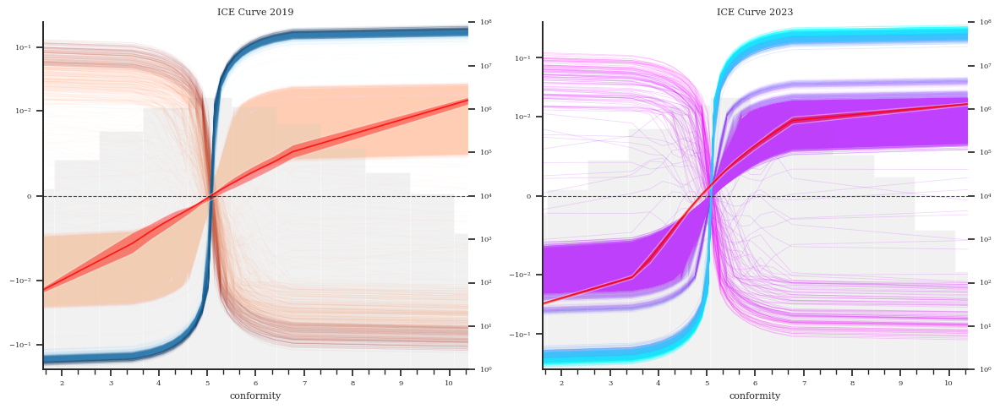

In [13]:
# 创建1×2的图窗
fig, axs = plt.subplots(1, 2, figsize=(12, 5))  # 1行2列的图窗，尺寸为12×6
estimator = [('RNN_Model',RandomForestRegressor())]
explainer = skexplain.ExplainToolkit(estimator)

# 绘制 RNN_Model_19 的 ALE 和 ICE 曲线

explainer.plot_ale(
    ale=ale_dataset_19,
    features='conformity',
    display_units=plotting_config.display_units,
    display_feature_names=plotting_config.display_feature_names,
    ice_curves=ice_dataset_19,
    hist_color = 'lightgrey',
    ice_color = '#2E167E',
    ice_cmap = my_cmap,
    color_by='first_values',
    yscale='symlog',
    y_linscale=1.2, # 越小零附近放大越强
    show_colorbar=False, 
    ice_alpha=0.05,
    ice_linewidth=0.6,
    wspace=0.25,
    ax=axs[0]  # 绘制在第一个子图中
)
axs[0].set_title('ICE Curve 2019')  # 设置标题

# 绘制 RNN_Model_23 的 ALE 和 ICE 曲线
explainer.plot_ale(
    ale=ale_dataset_23,
    features='conformity',
    display_units=plotting_config.display_units,
    display_feature_names=plotting_config.display_feature_names,
    ice_curves=ice_dataset_23,
    hist_color = 'lightgrey',
    ice_cmap='cool',
    color_by='first_values',
    yscale='symlog',
    y_linscale=1.2, # 越小零附近放大越强
    show_colorbar=False, 
    ice_split_threshold = [-0.05,-0.02],
    ice_alpha=[0.05,0.2],
    ice_linewidth=[0.1,0.6],
    wspace=0.25,
    ax=axs[1]  # 绘制在第二个子图中
)
axs[1].set_title('ICE Curve 2023')  # 设置标题

# 调整图窗布局
plt.tight_layout()

# 显示图窗
plt.show()